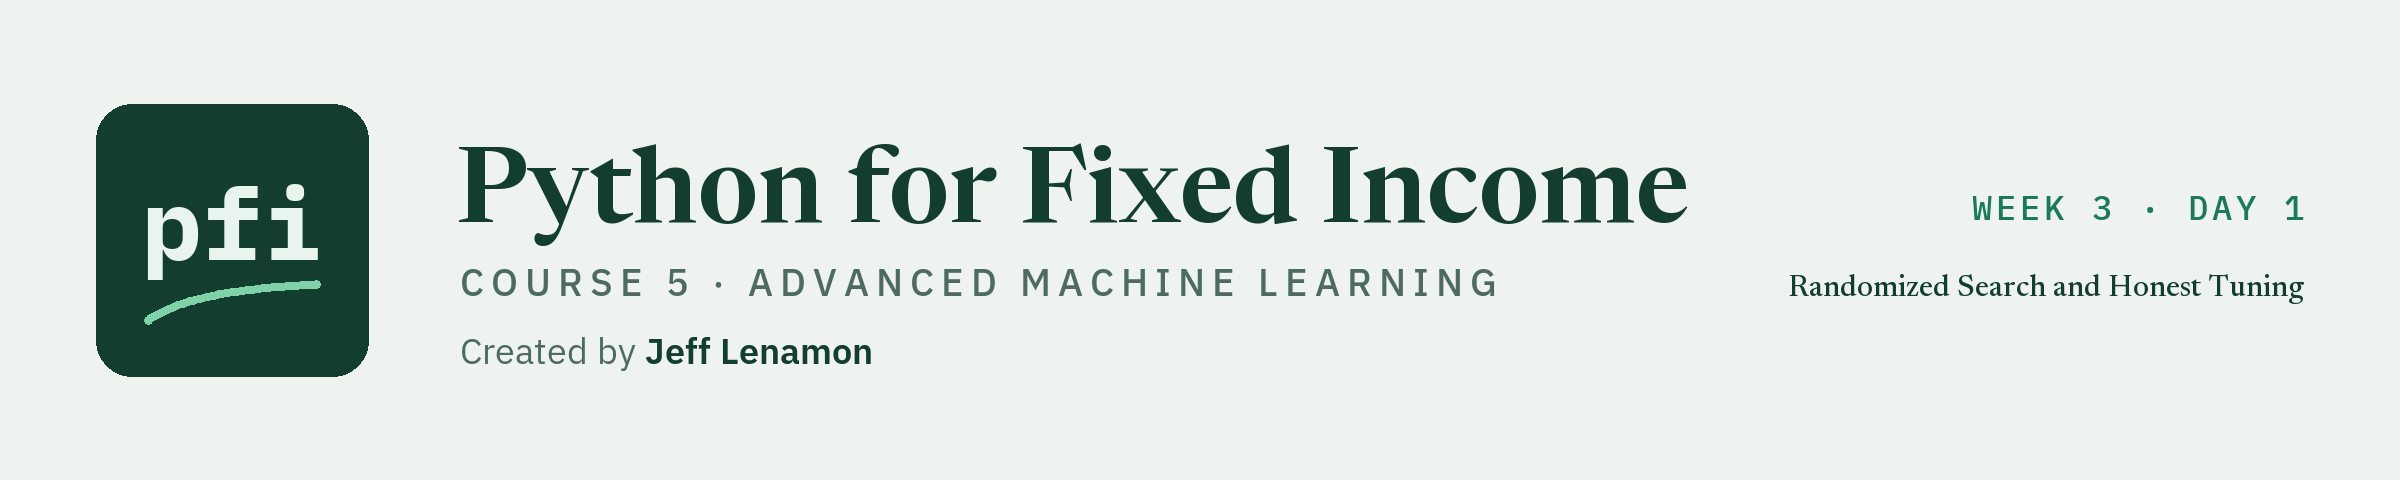

# Randomized Search and Honest Tuning

Week 3, Day 1. A search for better settings always finds a best candidate. Today: how to search efficiently, how to read what the search found, and how to measure honestly whether tuning bought anything at all.

**Data:** `polish_bankruptcy_5year.csv`, 5,910 financial statements of Polish companies: **real**, UCI Machine Learning Repository dataset 365, CC BY 4.0. Citation: Tomczak, S. (2016). Polish Companies Bankruptcy [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5F600.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week3/day1/11_randomized_search_and_honest_tuning.ipynb)

Week 3 moves from the card file to the Polish companies Course 4 used in its capstone. Course 4 chose a logistic regression there; this week asks what tuning, feature engineering, resampling, and SHAP values add on the same rows. Today is about tuning, and about one question a desk should ask of any tuned model: **how much of the improvement is real, and how much is the search congratulating itself?**

**The Polish rules, for every day of week 3.**

* **The data is real.** `polish_bankruptcy_5year.csv` is the UCI file of 5,910 financial statements of Polish companies, anonymised: 64 ratios (`Attr1` to `Attr64`) and a class column. The dataset page says the bankrupt companies were analysed in the period 2000 to 2012 and the still operating companies from 2007 to 2013, and that for this file the class "indicates bankruptcy status after 1 year". Nothing here describes any other market or period.
* **Course 4's split, rebuilt.** Course 4 dropped 60 exact duplicate rows and split the remaining 5,850 80/20, stratified, with the course seed. Its 1,170 test rows were opened once, in its capstone. By day 1's test-row rule they stay closed for the whole of Course 5: `ensemblekit.course4_polish_rows` never returns them.
* **Choices and scores inside the training rows.** The Polish file has no validation rows. Every model today is fitted and scored by cross-validation inside Course 4's 4,680 training rows, and every setting is chosen there too.
* **A model's output is described, never acted on.** A model's output is the model probability of bankruptcy in this file, or a flag at a threshold. It is not a credit view on any company, not a rating, and not an investment decision.

Today you will:

1. Rebuild Course 4's Polish training rows with `course4_polish_rows`, and score LightGBM with its default settings by five folds.
2. Count what a grid search costs.
3. Climb the tuning ladder on one model and one set of folds: a plain loop over a list, nested loops with a heatmap, `GridSearchCV`, `RandomizedSearchCV`, and a mini Optuna study.
4. Run a randomized search at full size with `scipy.stats` distributions.
5. Read the search's results with `search_table`.
6. Measure what tuning bought, against the default model on three other fold seeds.
7. Score the tuned model honestly with nested cross-validation (`nested_score`).
8. List what to tune first, and when to stop.
9. See that a threshold chosen after the search is one more choice.

Q. Set up today's work folder: the thread settings, the seed, the course data, and the modules as day 10 left them.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course05_advanced_ml/requirements.txt
NEEDED = {
    "catboost": "catboost==1.2.10",
    "imblearn": "imbalanced-learn==0.14.2",
    "ipykernel": "ipykernel==7.4.0",
    "ipywidgets": "ipywidgets==8.1.9",
    "jinja2": "jinja2==3.1.6",
    "lightgbm": "lightgbm==4.7.0",
    "matplotlib": "matplotlib==3.11.2",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "optuna": "optuna==5.0.0",
    "pandas": "pandas==3.0.6",
    "pytest": "pytest==9.1.1",
    "sklearn": "scikit-learn==1.9.1",
    "scipy": "scipy==1.18.1",
    "shap": "shap==0.52.0",
    "statsmodels": "statsmodels==0.15.0",
    "xgboost": "xgboost==3.4.1",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

17 packages checked, all present


In [2]:
# today's setup: the thread settings, the modules, the seed, the course data, and a fresh work folder
import os

# one thread for the maths libraries, so every run of the notebook gives the same last digits.
# These two lines must run before numpy, pandas, scikit-learn, XGBoost, or LightGBM is imported: if you ran another
# cell first, restart the kernel and run this cell first (in Colab: Runtime, Restart session).
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

import importlib
import importlib.metadata
import importlib.util
import platform
import shutil
import subprocess
import sys
import tempfile
import urllib.request
from pathlib import Path

# packages a Colab runtime or a new environment may lack: stop with the line that installs the missing one
for module_name, install_name in [("sklearn", "scikit-learn"), ("statsmodels", "statsmodels"), ("scipy", "scipy"), ("xgboost", "xgboost"), ("lightgbm", "lightgbm"), ("imblearn", "imbalanced-learn"), ("shap", "shap"), ("pytest", "pytest")]:
    if importlib.util.find_spec(module_name) is None:
        raise RuntimeError(f"{install_name} is not installed. Run  !pip install {install_name}  in a new cell, "
                           "then run this cell again.")

import numpy as np
import pandas as pd

# the versions the saved outputs of this notebook came from (course05_advanced_ml/requirements.txt)
PINNED = {"numpy": "2.5.3", "pandas": "3.0.6", "scikit-learn": "1.9.1", "scipy": "1.18.1", "xgboost": "3.4.1", "lightgbm": "4.7.0", "imbalanced-learn": "0.14.2", "shap": "0.52.0", "matplotlib": "3.11.2", "pytest": "9.1.1"}
installed = {name: importlib.metadata.version(name) for name in PINNED}
print(f"Python {platform.python_version()}; " + ", ".join(f"{name} {version}" for name, version in installed.items()))
different = [name for name in PINNED if installed[name] != PINNED[name]]
if different:
    print(f"Not the course's pinned version: {', '.join(different)}. Printed numbers may differ in the last digits from the saved notebook.")

# the seed: one number for every random choice the course makes, so every run makes the same choices
SEED = 42

# remember the notebook's own folder, so that running this cell again starts from the same place
if "notebook_folder" not in globals():
    notebook_folder = Path.cwd()

# 1. find the course data before moving: the repo's data folder on your machine, GitHub in Colab
RAW_DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"
local_data = (notebook_folder / ".." / ".." / ".." / "data").resolve()
on_github = not (local_data / "credit_card_default.csv").exists()

# 2. a fresh work folder for today, in the system temp folder, outside the course repo
work = Path(tempfile.mkdtemp(prefix="pfi_course5_11_"))
os.chdir(work)

# 3. copy today's data files into the work folder
DATA_FILES = ["credit_card_default.csv", "benchmark.csv", "ratings.csv", "polish_bankruptcy_5year.csv"]
for name in DATA_FILES:
    if on_github:
        urllib.request.urlretrieve(RAW_DATA + name, work / name)
    else:
        shutil.copy(local_data / name, work / name)

# print the folder's name only: its full path would show your user name
print(f"Work folder: {work.name}, in your temp folder")
print(f"Data files from {'GitHub' if on_github else 'the data folder of the course repo'}: {', '.join(DATA_FILES)}")
print(f"SEED = {SEED}")

Python 3.13.8; numpy 2.5.3, pandas 3.0.6, scikit-learn 1.9.1, scipy 1.18.1, xgboost 3.4.1, lightgbm 4.7.0, imbalanced-learn 0.14.2, shap 0.52.0, matplotlib 3.11.2, pytest 9.1.1
Work folder: pfi_course5_11_nwn4hy6s, in your temp folder
Data files from the data folder of the course repo: credit_card_default.csv, benchmark.csv, ratings.csv, polish_bankruptcy_5year.csv
SEED = 42


* The setup copies four data files: the card file, the two benchmark files, and, new today, the Polish file. `test_ensemblekit.py` holds every day's tests, and they read all four. The modules are written as day 10 left them; today adds three functions.
* `plotkit.py` is Course 4's chart and table helper module, written unchanged, as every Course 5 notebook writes it: bars, lines, confusion heatmaps, and formatted comparison tables. It is the course's helper, not today's work, so it stays out of today's commits, like the data files.

Q. Write `mlkit.py`, Course 4's complete module, unchanged. `ensemblekit` imports it.

In [3]:
%%writefile mlkit.py
"""mlkit: the small pieces of machine learning that scikit-learn leaves to the analyst, written down and tested.

Written day by day in Python for Fixed Income, Course 4: Machine Learning.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- Spreads are in basis points (bp). A model of log_oas is fitted in natural logs of bp; its errors are reported
  in bp after exp, and exp of a fitted log is a median-type value, not a mean.
- The positive class is 1 (default, bankrupt). Precision, recall, and F1 are for class 1 only.
- A row is flagged when its model probability is at least the threshold (probability >= threshold).
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart; the split
  functions here prove it with a check that stops.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from numpy.typing import ArrayLike  # a list, an array, or a pandas Series


def assert_disjoint(train_index: ArrayLike, test_index: ArrayLike) -> None:
    """Stop if any row label is in both the training rows and the test rows.

    Inputs: the labels (or positions) of the rows in each part, for example X_train.index and X_test.index.
    Output: None when the parts share no label.
    Convention: a row in both parts is a test row the model has already seen, which flatters every metric.
    Raises AssertionError naming how many labels are in both parts, and ValueError if either part is empty.
    """
    # the labels of each part as sets
    train = set(np.asarray(train_index).tolist())
    test = set(np.asarray(test_index).tolist())
    if not train or not test:
        raise ValueError("train_index and test_index must both hold at least one label")
    # the labels found in both parts
    shared = train & test
    if shared:
        raise AssertionError(f"{len(shared)} row labels are in both the training and the test rows")


def _as_1d_array(values: ArrayLike, name: str) -> np.ndarray:
    """Return `values` as a 1-D float array, or raise ValueError naming the input."""
    array = np.asarray(values, dtype=float)
    if array.ndim != 1:
        raise ValueError(f"{name} must be one-dimensional, not {array.ndim}-dimensional")
    if array.size == 0:
        raise ValueError(f"{name} is empty")
    return array


def regression_metrics(y_true: ArrayLike, y_fitted: ArrayLike) -> dict[str, float]:
    """R-squared, mean absolute error, and root mean squared error of fitted values.

    Inputs: y_true and y_fitted, the same length, in the target's unit (for example oas in bp).
    Output: {"r2", "mae", "rmse"}. r2 is unitless, 1 - SS_res / SS_tot on the rows given (on test rows it can
    be negative); mae and rmse are in the target's unit. For a log_oas model, pass exp of both to get bp.
    Convention: equal to scikit-learn's r2_score, mean_absolute_error, and root_mean_squared_error.
    Excel: =RSQ(...) only for a straight line on one feature; =AVERAGE(ABS(a-b)) and =SQRT(SUMXMY2(a,b)/COUNT(a)).
    Raises ValueError if the inputs are empty, not one-dimensional, or of different lengths.
    """
    # check both inputs and that they line up row for row
    actual = _as_1d_array(y_true, "y_true")
    fitted = _as_1d_array(y_fitted, "y_fitted")
    if actual.size != fitted.size:
        raise ValueError(f"y_true has {actual.size} values and y_fitted has {fitted.size}")
    # each error in the target's unit
    errors = actual - fitted
    # R-squared: the share of the spread around the mean that the fitted values account for
    ss_res = float(np.sum(errors ** 2))
    ss_tot = float(np.sum((actual - actual.mean()) ** 2))
    r2 = 1 - ss_res / ss_tot
    # the average size of an error, and the square root of the average squared error
    mae = float(np.mean(np.abs(errors)))
    rmse = float(np.sqrt(np.mean(errors ** 2)))
    return {"r2": r2, "mae": mae, "rmse": rmse}


def adjusted_r2(r2: float, n_rows: int, n_features: int) -> float:
    """Adjusted R-squared: R-squared with a charge for each feature.

    Inputs: r2 on the training rows (unitless), n_rows the number of training rows, n_features the number of
    features not counting the intercept.
    Output: 1 - (1 - r2) x (n_rows - 1) / (n_rows - n_features - 1), unitless. An in-sample measure, so it is
    computed on training rows only.
    Excel: =1-(1-R2)*(n-1)/(n-k-1)
    Raises ValueError if n_features is negative or n_rows is not above n_features + 1.
    """
    # the formula needs at least one degree of freedom left after the features and the intercept
    if n_features < 0:
        raise ValueError(f"n_features must be 0 or more, not {n_features}")
    if n_rows <= n_features + 1:
        raise ValueError(f"n_rows ({n_rows}) must be greater than n_features + 1 ({n_features + 1})")
    # scale the unexplained share by the ratio of degrees of freedom
    return 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1)


def rating_dummies(ratings: pd.Series, levels: list[str], reference: str) -> pd.DataFrame:
    """One indicator column per rating level except the reference level, which the intercept stands for.

    Inputs: ratings, one text rating per bond (for example "BBB+"); levels, every allowed level in the order the
    columns should follow (the rating column of ratings.csv, known in advance, not learned from the data);
    reference, the level left out.
    Output: a DataFrame with the same index, one float column (0.0 or 1.0) per level except reference, named
    rating_<level>, in the order of levels. A coefficient on rating_BB is then the difference from a bond rated
    `reference`, other features fixed.
    Convention: floats, not booleans, so every library and an Excel formula read the same 0.0 and 1.0. The
    reference is named by the caller, never chosen by alphabetical order.
    Raises ValueError if ratings is empty, reference is not in levels, or a rating is not in levels.
    """
    # check the inputs before building anything
    if len(ratings) == 0:
        raise ValueError("ratings is empty")
    if reference not in levels:
        raise ValueError(f"reference {reference!r} is not one of the levels")
    unknown = sorted(set(ratings) - set(levels))
    if unknown:
        raise ValueError(f"ratings not in levels: {unknown}")
    # one column per level, 1.0 where the bond has that rating
    columns = {f"rating_{level}": (ratings == level).astype(float) for level in levels if level != reference}
    return pd.DataFrame(columns, index=ratings.index)


def vif_table(X: pd.DataFrame) -> pd.Series:
    """Variance inflation factor of each feature: how much its coefficient's variance grows from the overlap with
    the other features.

    Input: X, the features as numeric columns (no constant column; one is added inside).
    Output: a Series named vif, one value per column, sorted from highest to lowest. VIF_j = 1 / (1 - R2_j),
    where R2_j is the R-squared of column j regressed on a constant and every other column. 1 means no overlap;
    above 5 is called high and above 10 very high, as conventions. A column that is an exact copy (or exact
    combination) of others has R2_j = 1 and VIF infinity.
    Convention: equal to statsmodels' variance_inflation_factor on X with a constant added.
    Excel: =1/(1-INDEX(LINEST(xj, other columns, TRUE, TRUE), 3, 1))
    Raises ValueError if X has fewer than two columns or fewer rows than columns plus two.
    """
    # check there is something to regress on, and enough rows to do it
    if X.shape[1] < 2:
        raise ValueError(f"X needs at least two columns, not {X.shape[1]}")
    if X.shape[0] < X.shape[1] + 2:
        raise ValueError(f"X has {X.shape[0]} rows, too few for {X.shape[1]} columns")
    values = X.to_numpy(dtype=float)
    result = {}
    for j, name in enumerate(X.columns):
        # column j is the target; a constant and the other columns are the features
        target = values[:, j]
        others = np.column_stack([np.ones(len(values)), np.delete(values, j, axis=1)])
        # least squares fit and its R-squared
        coefficients, *_ = np.linalg.lstsq(others, target, rcond=None)
        ss_res = float(np.sum((target - others @ coefficients) ** 2))
        ss_tot = float(np.sum((target - target.mean()) ** 2))
        r2 = 1 - ss_res / ss_tot
        # an exact combination of the others leaves no residual (R-squared 1 to the last digit): the VIF is infinite
        result[name] = np.inf if r2 >= 1 else 1 / (1 - r2)
    return pd.Series(result, name="vif").sort_values(ascending=False)


from scipy import stats  # Jarque-Bera and Shapiro-Wilk
from statsmodels.stats.diagnostic import het_breuschpagan  # Breusch-Pagan
from statsmodels.tools import add_constant  # the intercept column


def residual_tests(residuals: pd.Series, exog: pd.DataFrame) -> dict[str, float]:
    """p-values of three checks on a regression's residuals: constant variance and normality (two tests).

    Inputs: residuals, actual minus fitted on the training rows, in the target's unit; exog, the features the
    model was fitted on, without a constant (one is added inside), with the same rows.
    Output: {"breusch_pagan", "jarque_bera", "shapiro_wilk"}, each a p-value between 0 and 1. A small p-value
    (below 0.05, the course's convention) means the data would be surprising if the assumption held:
    - breusch_pagan: statsmodels het_breuschpagan with its default (Koenker's form, n x R-squared of the squared
      residuals regressed on a constant and exog); the assumption is constant variance;
    - jarque_bera: scipy.stats.jarque_bera (skew and kurtosis); the assumption is normal residuals;
    - shapiro_wilk: scipy.stats.shapiro; the assumption is normal residuals.
    Excel has no function for these; Breusch-Pagan can be built from LINEST and CHISQ.DIST.RT.
    Raises ValueError if the inputs are empty or have different numbers of rows.
    """
    # check the two inputs line up
    if len(residuals) == 0 or len(exog) == 0:
        raise ValueError("residuals and exog must not be empty")
    if len(residuals) != len(exog):
        raise ValueError(f"residuals has {len(residuals)} rows and exog has {len(exog)}")
    values = np.asarray(residuals, dtype=float)
    # Breusch-Pagan: returns the LM statistic, its p-value, then an F form; the LM p-value is kept
    _, bp_pvalue, _, _ = het_breuschpagan(values, add_constant(np.asarray(exog, dtype=float), has_constant="add"))
    # the two normality tests
    jb_pvalue = stats.jarque_bera(values).pvalue
    sw_pvalue = stats.shapiro(values).pvalue
    return {"breusch_pagan": float(bp_pvalue), "jarque_bera": float(jb_pvalue), "shapiro_wilk": float(sw_pvalue)}


from sklearn.pipeline import Pipeline  # the type of a chain of steps


def named_coefficients(pipeline: Pipeline) -> pd.Series:
    """The fitted coefficients of a pipeline's last step, labelled with the feature names that step saw.

    Input: a fitted scikit-learn Pipeline whose last step has coef_ (LinearRegression, Ridge, Lasso,
    LogisticRegression) and whose step before it has get_feature_names_out (a ColumnTransformer, a scaler).
    Output: a Series of coefficients indexed by feature name, in the order the model used them. Units: per unit
    of each feature as the model saw it, so per standard deviation after StandardScaler; the intercept is not
    included. For a binary LogisticRegression the one row of coef_ is used (log-odds of class 1).
    Raises ValueError if the last step has no coef_ (a tree, for example) or the pipeline has one step only.
    """
    # the model is the last step; the names come from everything before it
    if len(pipeline.steps) < 2:
        raise ValueError("the pipeline needs a preprocessing step before the model")
    model = pipeline.steps[-1][1]
    if not hasattr(model, "coef_"):
        raise ValueError(f"the last step, {type(model).__name__}, has no coef_")
    names = pipeline[:-1].get_feature_names_out()
    # a binary classifier keeps its coefficients in one row; flatten it
    coefficients = np.ravel(model.coef_)
    if coefficients.size != len(names):
        raise ValueError(f"{coefficients.size} coefficients but {len(names)} feature names")
    return pd.Series(coefficients, index=names, name="coefficient")


def odds_ratios(coefficients: pd.Series) -> pd.Series:
    """Odds ratios from logistic regression coefficients: exp of each coefficient, the intercept left out.

    Input: coefficients in log-odds, indexed by feature name, as statsmodels' Logit params (the intercept is
    named "const") or a Series with an entry named "intercept".
    Output: a Series of exp(coefficient) per feature: the factor by which the odds of class 1 multiply for one
    more unit of that feature, other features fixed. The unit is the feature's own (per 10,000 NT dollars if the
    feature was divided by 10,000; per standard deviation if it was scaled).
    Excel: =EXP(coef)
    Raises ValueError if no coefficient is left once the intercept is removed.
    """
    # leave out the intercept: exp of it is the odds when every feature is 0, not a ratio
    slopes = coefficients.drop(labels=["const", "intercept"], errors="ignore")
    if slopes.empty:
        raise ValueError("no coefficients left after removing the intercept")
    return np.exp(slopes).rename("odds_ratio")


def logistic_probability(z: float | ArrayLike) -> float | np.ndarray:
    """The logistic curve: turns log-odds z into a probability between 0 and 1.

    Input: z, a number or an array of numbers in log-odds (intercept plus coefficients times features).
    Output: 1 / (1 + exp(-z)), a float for a number, an array for an array. z = 0 gives 0.5.
    Excel: =1/(1+EXP(-z))
    """
    # numpy's exp works on a number and on an array alike
    probability = 1 / (1 + np.exp(-np.asarray(z, dtype=float)))
    return float(probability) if probability.ndim == 0 else probability


def _check_labels(y_true: ArrayLike, y_flag: ArrayLike) -> tuple[np.ndarray, np.ndarray]:
    """Return both inputs as integer arrays of 0 and 1, or raise ValueError."""
    actual = np.asarray(y_true)
    flagged = np.asarray(y_flag)
    if actual.ndim != 1 or flagged.ndim != 1 or actual.size == 0:
        raise ValueError("y_true and y_flag must be non-empty and one-dimensional")
    if actual.size != flagged.size:
        raise ValueError(f"y_true has {actual.size} values and y_flag has {flagged.size}")
    for name, values in (("y_true", actual), ("y_flag", flagged)):
        others = sorted(set(values.tolist()) - {0, 1})
        if others:
            raise ValueError(f"{name} holds labels other than 0 and 1: {others[:5]}")
    return actual.astype(int), flagged.astype(int)


def confusion_counts(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, int]:
    """The four cells of the confusion matrix, with 1 (default) as the positive class.

    Inputs: y_true, the actual outcome per row (0 or 1); y_flag, the model's flag per row (0 or 1), for example
    (probability >= threshold).
    Output: {"tn", "fp", "fn", "tp"} as whole numbers: true negatives (0 flagged 0), false positives (0 flagged
    1), false negatives (1 flagged 0), true positives (1 flagged 1). They add up to the number of rows.
    Convention: the same counts as confusion_matrix(y_true, y_flag).ravel() in scikit-learn.
    Excel: =COUNTIFS(actual,1,flag,1) and the other three combinations.
    Raises ValueError on labels other than 0 and 1, empty inputs, or inputs of different lengths.
    """
    actual, flagged = _check_labels(y_true, y_flag)
    # count each combination of actual and flag
    return {"tn": int(np.sum((actual == 0) & (flagged == 0))), "fp": int(np.sum((actual == 0) & (flagged == 1))),
            "fn": int(np.sum((actual == 1) & (flagged == 0))), "tp": int(np.sum((actual == 1) & (flagged == 1)))}


def classification_metrics(y_true: ArrayLike, y_flag: ArrayLike) -> dict[str, float]:
    """Accuracy, precision, recall, and F1 for class 1 (default), from 0/1 flags.

    Inputs: y_true and y_flag, as confusion_counts.
    Output: {"accuracy", "precision", "recall", "f1"}, each between 0 and 1:
    accuracy (TP + TN) / n; precision TP / (TP + FP), the share of flagged rows that are defaults; recall
    TP / (TP + FN), the share of defaults that are flagged; F1 their harmonic mean, 2TP / (2TP + FP + FN).
    Convention: pos_label=1, binary averaging, zero_division=0 (a model that flags nothing has precision 0, not
    an error), as scikit-learn's functions with those arguments.
    Excel: =TP/(TP+FP), =TP/(TP+FN) with the COUNTIFS cells.
    Raises ValueError as confusion_counts.
    """
    counts = confusion_counts(y_true, y_flag)
    tn, fp, fn, tp = counts["tn"], counts["fp"], counts["fn"], counts["tp"]
    # each ratio is 0 when its denominator is 0 (zero_division=0)
    accuracy = (tp + tn) / (tn + fp + fn + tp)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * tp / (2 * tp + fp + fn) if tp + fp + fn else 0.0
    return {"accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


def threshold_for_recall(y_true: ArrayLike, proba: ArrayLike, target_recall: float) -> float:
    """The highest threshold at which the model still catches at least `target_recall` of the defaults.

    Inputs: y_true, actual outcomes (0 or 1) on the rows used to choose (validation rows, or out-of-fold
    predictions on training rows, never test rows); proba, the model probability of class 1 per row;
    target_recall, the share of defaults the desk asks to catch, above 0 and at most 1.
    Output: one of the distinct probabilities. Flagging rows with probability >= that threshold gives recall at
    least target_recall, and the next higher distinct probability would give less. A higher threshold flags
    fewer rows, so this is the threshold with the fewest flags that meets the target.
    Convention: the course's threshold rule, stated as an illustration of the recall-against-precision choice.
    Raises ValueError if target_recall is not in (0, 1], the inputs differ in length, or there is no row of
    class 1.
    """
    # check the target and the inputs
    if not 0 < target_recall <= 1:
        raise ValueError(f"target_recall must be above 0 and at most 1, not {target_recall}")
    scores = _as_1d_array(proba, "proba")
    # y_true is checked as a set of 0/1 labels the same length as proba
    actual, _ = _check_labels(y_true, np.zeros(scores.size, dtype=int))
    positives = int(actual.sum())
    if positives == 0:
        raise ValueError("y_true has no row of class 1, so recall is undefined")
    # sort rows from the highest probability down; lowering the threshold adds rows in this order
    order = np.argsort(-scores, kind="stable")
    sorted_scores, sorted_actual = scores[order], actual[order]
    # defaults caught when every row down to this one is flagged
    caught = np.cumsum(sorted_actual)
    # a threshold equal to a probability flags every row with that probability, so look at the last row of
    # each run of equal probabilities
    last_of_run = np.append(sorted_scores[1:] != sorted_scores[:-1], True)
    recall = caught[last_of_run] / positives
    thresholds = sorted_scores[last_of_run]
    # thresholds run from high to low and recall only rises: take the first one that meets the target
    meets = np.nonzero(recall >= target_recall)[0]
    return float(thresholds[meets[0]])


from sklearn.model_selection import KFold, StratifiedKFold  # the course's cross-validation splitters


def cv_folds(kind: str = "classification") -> KFold | StratifiedKFold:
    """The course's cross-validation splitter, so the choice lives in one place.

    Input: kind, "classification" or "regression".
    Output: StratifiedKFold(5, shuffle=True, random_state=42) for classification (each fold keeps the share of
    class 1), KFold(5, shuffle=True, random_state=42) for regression. Pass it as cv= to GridSearchCV,
    cross_val_score, or cross_val_predict, on training rows only.
    Convention: never for dated rows, which use walk_forward_splits or TimeSeriesSplit (no shuffle).
    Raises ValueError for any other kind.
    """
    # five folds, shuffled once with the course's seed
    if kind == "classification":
        return StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    if kind == "regression":
        return KFold(n_splits=5, shuffle=True, random_state=42)
    raise ValueError(f'kind must be "classification" or "regression", not {kind!r}')


import re  # whole-word search

from sklearn.metrics import average_precision_score, roc_auc_score

# words that turn a description into a forecast, advice, or a lending decision; a reminder, not a proof
FORECAST_WORDS = ["will", "expect", "expects", "should", "forecast", "forecasts", "cheap", "rich", "attractive",
                  "signal", "signals", "buy", "sell", "approve", "decline", "lend", "invest"]


def compare_models(models: dict, X: pd.DataFrame, y: ArrayLike, thresholds: dict[str, float]) -> pd.DataFrame:
    """One row of metrics per fitted model, on the rows given.

    Inputs: models, {name: a fitted classifier with predict_proba}, fitted by the caller on training rows;
    X and y, the rows to report on (validation rows, or the test rows once at the end); thresholds,
    {name: threshold} for every model, chosen on rows other than these test rows.
    Output: a DataFrame indexed by model name with columns roc_auc and average_precision (from probabilities,
    no threshold), then threshold, accuracy, precision, recall, f1 for rows flagged at probability >= threshold.
    Convention: nothing is fitted here; an unfitted model raises scikit-learn's NotFittedError.
    Raises ValueError if models is empty or a model has no threshold.
    """
    # check every model has a threshold before computing anything
    if not models:
        raise ValueError("models is empty")
    missing = sorted(set(models) - set(thresholds))
    if missing:
        raise ValueError(f"no threshold for: {missing}")
    rows = {}
    for name, model in models.items():
        # the model probability of class 1 per row
        proba = model.predict_proba(X)[:, 1]
        # metrics that rank without a threshold, then metrics at the model's threshold
        row = {"roc_auc": roc_auc_score(y, proba), "average_precision": average_precision_score(y, proba),
               "threshold": thresholds[name]}
        row |= classification_metrics(y, (proba >= thresholds[name]).astype(int))
        rows[name] = row
    return pd.DataFrame.from_dict(rows, orient="index")


def assert_descriptive(text: str) -> None:
    """Stop if a written description uses a word from FORECAST_WORDS.

    Input: text, a description of what a model shows.
    Output: None if no listed word appears as a whole word, in any case.
    Convention: the list is a reminder, not a proof. A text can pass and still make a forecast in other words,
    and a listed word can be harmless in context; the check makes the writer look again.
    Raises ValueError naming every listed word found, in the order of FORECAST_WORDS.
    """
    # whole words only, ignoring case: "willing" does not match "will"
    found = [word for word in FORECAST_WORDS if re.search(rf"\b{word}\b", text, flags=re.IGNORECASE)]
    if found:
        raise ValueError(f"the text uses forecast, advice, or lending words: {found}")


def walk_forward_splits(dates: pd.DatetimeIndex, min_train: int, test_size: int,
                        gap: int = 0) -> list[tuple[np.ndarray, np.ndarray]]:
    """Expanding-window splits for dated rows: train on the past, test on the rows that follow.

    Inputs: dates, the rows' dates, unique and ascending; min_train, the rows in the first training window;
    test_size, the rows in each test window; gap, rows left out between the last training row and the first
    test row (use the number of rows a target or feature spans; 0 for a same-day target).
    Output: a list of (train_positions, test_positions), integer positions into dates. Fold k trains on
    positions 0 to min_train + k x test_size - 1 and tests the next test_size positions after `gap` rows.
    The window steps forward by test_size; a last test window shorter than test_size is dropped.
    Convention: never shuffled; every training date is before every test date.
    Raises ValueError if the dates are not unique and ascending, min_train or test_size is below 1, gap is
    negative, or there are too few rows for one fold.
    """
    # check the dates and the sizes
    index = pd.DatetimeIndex(dates)
    if not (index.is_unique and index.is_monotonic_increasing):
        raise ValueError("dates must be unique and ascending")
    if min_train < 1 or test_size < 1 or gap < 0:
        raise ValueError(f"need min_train >= 1, test_size >= 1, gap >= 0; got {min_train}, {test_size}, {gap}")
    splits = []
    train_end = min_train  # one past the last training position
    # add folds while a whole test window fits after the gap
    while train_end + gap + test_size <= len(index):
        test_start = train_end + gap
        splits.append((np.arange(0, train_end), np.arange(test_start, test_start + test_size)))
        train_end += test_size
    if not splits:
        raise ValueError(f"{len(index)} rows are too few for min_train {min_train}, gap {gap}, test_size {test_size}")
    return splits


def assert_past_only(train_dates: ArrayLike, test_dates: ArrayLike, gap: int = 0,
                     calendar: ArrayLike | None = None) -> None:
    """Stop unless every training date is earlier than every test date, with a gap where one is asked for.

    Inputs: the dates of the training rows and of the test rows; gap, the rows of `calendar` that must lie
    strictly between the last training date and the first test date; calendar, every date of the dataset
    (needed when gap is above 0).
    Output: None when the split uses only the past.
    Raises AssertionError naming the last training date and the first test date when the order or the gap is
    wrong, and ValueError if either part is empty or a gap is asked for without a calendar.
    """
    train = pd.DatetimeIndex(train_dates)
    test = pd.DatetimeIndex(test_dates)
    if len(train) == 0 or len(test) == 0:
        raise ValueError("train_dates and test_dates must both hold at least one date")
    # the latest training date must come before the earliest test date
    last_train, first_test = train.max(), test.min()
    if not last_train < first_test:
        raise AssertionError(f"a training date ({last_train.date()}) is not before the first test date "
                             f"({first_test.date()})")
    if gap > 0:
        if calendar is None:
            raise ValueError("a gap is counted in rows of the calendar, so calendar is needed")
        # rows of the calendar strictly between the two dates
        days = pd.DatetimeIndex(calendar)
        between = int(((days > last_train) & (days < first_test)).sum())
        if between < gap:
            raise AssertionError(f"only {between} rows lie between {last_train.date()} and {first_test.date()}, "
                                 f"fewer than the gap of {gap}")


from collections.abc import Iterable

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


def elbow_table(X: ArrayLike, k_values: Iterable[int], seed: int = 42) -> pd.DataFrame:
    """Inertia and silhouette of K-means for each number of clusters, to choose k by judgement.

    Inputs: X, the features already scaled (K-means measures distance, so units decide the clusters); k_values,
    the numbers of clusters to try, each 2 or more; seed, passed as random_state.
    Output: a DataFrame indexed by k (named k) with columns inertia (the within-cluster sum of squared distances,
    in squared scaled units; it falls as k rises) and silhouette (the mean silhouette coefficient, Euclidean,
    -1 to 1; higher means tighter, better separated clusters).
    Convention: KMeans(n_clusters=k, n_init=10, random_state=seed), n_init written out.
    Raises ValueError if k_values is empty, a k is below 2, or a k is not below the number of rows.
    """
    # check the k values before fitting
    ks = list(k_values)
    if not ks:
        raise ValueError("k_values is empty")
    n_rows = len(X)
    bad = [k for k in ks if k < 2 or k >= n_rows]
    if bad:
        raise ValueError(f"each k must be at least 2 and below the {n_rows} rows; not {bad}")
    rows = []
    for k in ks:
        # fit K-means with ten starts and the course's seed
        model = KMeans(n_clusters=k, n_init=10, random_state=seed).fit(X)
        rows.append({"k": k, "inertia": float(model.inertia_), "silhouette": float(silhouette_score(X, model.labels_))})
    return pd.DataFrame(rows).set_index("k")


def cluster_profile(frame: pd.DataFrame, labels: ArrayLike, columns: list[str]) -> pd.DataFrame:
    """Describe each cluster in the data's own units: how many rows, and the median of each column.

    Inputs: frame, the rows in their original units (oas in bp, duration in years), not the scaled features the
    clusters were fitted on; labels, the cluster of each row, in the same order; columns, the columns to profile.
    Output: a DataFrame indexed by cluster (named cluster, sorted), with count and one median column per name in
    columns, in the frame's units. A profile describes a group; it does not rank one.
    Excel: a pivot table counts and averages but has no median; =MEDIAN(IF(labels=k, column)) does.
    Raises ValueError if labels and frame differ in length, frame is empty, or a column is not in frame.
    """
    # check the inputs line up and the columns exist
    labels = np.asarray(labels)
    if len(frame) == 0:
        raise ValueError("frame is empty")
    if len(labels) != len(frame):
        raise ValueError(f"labels has {len(labels)} values and frame has {len(frame)} rows")
    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"columns not in frame: {missing}")
    # group the original rows by cluster, then count and take medians
    grouped = frame[columns].groupby(pd.Series(labels, index=frame.index, name="cluster"))
    profile = grouped.median()
    profile.insert(0, "count", grouped.size())
    return profile.sort_index()


from sklearn.decomposition import PCA


def pca_loadings(pca: PCA, names: list[str]) -> pd.DataFrame:
    """The loadings of a fitted PCA, one column per component, each with a fixed sign.

    Inputs: pca, a fitted scikit-learn PCA; names, the input columns in the order the PCA saw them (for the
    curve, the tenors).
    Output: a DataFrame indexed by name with columns PC1, PC2, ...: each component's weights on the inputs
    (pca.components_ transposed, unit length). A component's sign is arbitrary, so each column is multiplied by
    -1 where needed to make its loadings sum to a positive number; a rerun or another library then gives the
    same picture. Scores that match these loadings are (X - pca.mean_) @ loadings.
    Excel: no PCA function; =MMULT(changes less their column means, loadings) gives the scores.
    Raises ValueError if names does not have one entry per input column.
    """
    # one name per input column
    components = np.asarray(pca.components_)
    if len(names) != components.shape[1]:
        raise ValueError(f"{len(names)} names for {components.shape[1]} input columns")
    loadings = pd.DataFrame(components.T, index=names,
                            columns=[f"PC{i}" for i in range(1, components.shape[0] + 1)])
    # flip each component whose loadings sum to a negative number
    signs = np.where(loadings.sum(axis=0) < 0, -1.0, 1.0)
    return loadings * signs


def explained_table(pca: PCA) -> pd.DataFrame:
    """The share of variance each component of a fitted PCA accounts for, and the running total, in percent.

    Input: pca, a fitted scikit-learn PCA.
    Output: a DataFrame indexed by PC1, PC2, ... with explained_pct (explained_variance_ratio_ x 100) and
    cumulative_pct (the running sum). With every component kept, the last cumulative_pct is 100.
    """
    # the ratios in percent, then their running sum
    explained = np.asarray(pca.explained_variance_ratio_) * 100
    index = [f"PC{i}" for i in range(1, len(explained) + 1)]
    return pd.DataFrame({"explained_pct": explained, "cumulative_pct": np.cumsum(explained)}, index=index)

Writing mlkit.py


Q. Write `ensemblekit.py` and `test_ensemblekit.py` as they stand at the start of today: the reference version at the end of the last notebook.

In [4]:
%%writefile ensemblekit.py
"""ensemblekit: the pieces of ensembles, tuning, and rare-event modelling that the libraries leave to the analyst,
written down and tested.

Written day by day in Python for Fixed Income, Course 5: Advanced Machine Learning. It imports mlkit (Course 4's
module) and never changes it.

Conventions, the same in every function:
- The seed is 42 wherever a function takes one, so every run gives the same numbers.
- The positive class is 1 (default, bankrupt). A row is flagged when its model output is at least the threshold.
- Course 5 never scores a row that Course 4 used as a test row. The course4_*_rows functions rebuild Course 4's
  splits exactly and return only the rows Course 5 may use; the closed rows are never returned.
- Rows that fit a model, rows that choose a setting, and rows that report a result are kept apart.
- Every library call that can use more than one thread is given n_jobs=1, so every run gives the same digits.
- Inputs of the wrong shape, or empty inputs, raise ValueError with a message that says what was wrong.
"""
import numpy as np  # arrays and arithmetic
import pandas as pd  # tables with labels
from sklearn.model_selection import train_test_split  # Course 4's split, rebuilt

import mlkit  # Course 4's module: thresholds, metrics, splitters, and the no-leak check

# the card file: its outcome column and the 19 model columns (the four person columns are never features)
CARD_TARGET = "default payment next month"
CARD_FEATURES = ["LIMIT_BAL", "PAY_0", "PAY_2", "PAY_3", "PAY_4", "PAY_5", "PAY_6"] + \
    [f"BILL_AMT{i}" for i in range(1, 7)] + [f"PAY_AMT{i}" for i in range(1, 7)]


def course4_card_rows(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """Course 4's 60/20/20 split of the card file, rebuilt, without its test rows.

    Input: frame, the 30,000 accounts of credit_card_default.csv as read by pd.read_csv.
    Output: X_train (18,000 rows), X_valid (6,000 rows), y_train, y_valid, with the 19 model columns in
    CARD_FEATURES and the file's row labels. Course 4's 6,000 test rows are never returned.
    Convention: the same two calls as Course 4: train_test_split(test_size=0.2, stratify=y, random_state=42), then
    the remaining 80 percent split with test_size=0.25, stratified, same seed. The validation rows were used in
    Course 4 to choose a threshold and a pruning level, never to fit.
    Raises ValueError if a column is missing or the frame does not have 30,000 rows.
    """
    # check the frame is the whole card file
    missing = [name for name in CARD_FEATURES + [CARD_TARGET] if name not in frame.columns]
    if missing:
        raise ValueError(f"frame lacks the columns {missing}")
    if len(frame) != 30_000:
        raise ValueError(f"frame must hold the 30,000 card accounts, not {len(frame)}")
    X, y = frame[CARD_FEATURES], frame[CARD_TARGET]
    # Course 4's first cut puts 20 percent aside as test rows: they are dropped here, never returned
    X_rest, _, y_rest, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    # Course 4's second cut: a quarter of the rest (20 percent of the file) as validation rows
    X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest,
                                                          random_state=42)
    mlkit.assert_disjoint(X_train.index, X_valid.index)
    return X_train, X_valid, y_train, y_valid


def bootstrap_positions(n_rows: int, seed: int = 42) -> np.ndarray:
    """Draw n_rows row positions with replacement: one bootstrap sample.

    Input: n_rows, how many rows the data has (at least 1); seed, the random seed.
    Output: an array of n_rows positions from 0 to n_rows - 1, in the order drawn. A position can appear more than
    once, and some positions do not appear at all (about 36.8 percent of them for large n_rows).
    Convention: np.random.default_rng(seed).integers(0, n_rows, n_rows), so the same seed gives the same sample.
    Excel: =RANDBETWEEN(1,n) draws one position but takes no seed and changes at every recalculation.
    Raises ValueError if n_rows is below 1.
    """
    if n_rows < 1:
        raise ValueError(f"n_rows must be at least 1, not {n_rows}")
    # one generator per call, seeded, so the draw does not depend on anything drawn before
    rng = np.random.default_rng(seed)
    return rng.integers(0, n_rows, n_rows)


def out_of_bag(n_rows: int, drawn: np.ndarray) -> np.ndarray:
    """The positions a bootstrap sample never drew: its out-of-bag rows.

    Inputs: n_rows, how many rows the data has; drawn, the positions of a bootstrap sample.
    Output: the sorted positions from 0 to n_rows - 1 that are not in drawn.
    Convention: a model fitted on the drawn rows has never seen these rows, so they can score it.
    Raises ValueError if drawn is empty or holds a position outside 0 to n_rows - 1.
    """
    positions = np.asarray(drawn)
    if positions.size == 0:
        raise ValueError("drawn is empty")
    if positions.min() < 0 or positions.max() > n_rows - 1:
        raise ValueError(f"drawn holds a position outside 0 to {n_rows - 1}")
    # every position, minus the ones drawn at least once
    return np.setdiff1d(np.arange(n_rows), positions)


from sklearn.metrics import roc_auc_score  # ranking quality from probabilities


def bagged_proba(bagging, X: pd.DataFrame) -> np.ndarray:
    """Bagging by hand: the average of each fitted tree's class-1 probability, each on its own columns.

    Inputs: bagging, a fitted BaggingClassifier; X, the rows to score, with the columns it was fitted on.
    Output: one number per row, the mean over bagging.estimators_ of each tree's class-1 probability on the
    columns listed in bagging.estimators_features_. It equals bagging.predict_proba(X)[:, 1] within 1e-12.
    Convention: a tree whose bootstrap sample held only one class gives 0 for class 1 when that class is 0.
    Excel: with each tree's column of outputs pasted side by side, =AVERAGE(B2:K2) filled down.
    Raises ValueError if bagging is not fitted.
    """
    if not hasattr(bagging, "estimators_"):
        raise ValueError("bagging is not fitted: call fit first")
    # the trees were fitted on plain arrays of the chosen columns, so score them the same way
    values = np.asarray(X, dtype=float)
    total = np.zeros(len(values))
    for tree, columns in zip(bagging.estimators_, bagging.estimators_features_):
        proba = tree.predict_proba(values[:, columns])
        # the tree's classes are positions in bagging.classes_; class 1 is position 1
        position = np.flatnonzero(tree.classes_ == 1)
        total += proba[:, position[0]] if position.size else 0.0
    return total / len(bagging.estimators_)


def oob_auc(model, y_train) -> float:
    """ROC AUC of the out-of-bag probabilities of a bagged model or a random forest.

    Inputs: model, fitted with oob_score=True on the training rows; y_train, those rows' outcomes, in order.
    Output: roc_auc_score(y_train, model.oob_decision_function_[:, 1]): each row scored only by the trees that
    did not draw it.
    Convention: model.oob_score_ is the accuracy of the out-of-bag votes for a classifier, not ROC AUC; this
    function gives the ranking number the course compares models by.
    Raises ValueError if the model was fitted without oob_score=True, or if a row has no out-of-bag vote (too few
    trees, so some row was drawn by every tree).
    """
    if not hasattr(model, "oob_decision_function_"):
        raise ValueError("the model has no out-of-bag outputs: fit it with oob_score=True")
    proba = model.oob_decision_function_[:, 1]
    if np.isnan(proba).any():
        raise ValueError(f"{int(np.isnan(proba).sum())} rows have no out-of-bag vote: use more trees")
    return float(roc_auc_score(y_train, proba))


def tree_correlation(forest, X: pd.DataFrame) -> float:
    """How much the trees of an ensemble agree: the mean pairwise correlation of their class-1 outputs.

    Inputs: forest, a fitted random forest, extra-trees, or bagging model (anything with estimators_, and
    estimators_features_ for bagging); X, the rows to score (validation rows).
    Output: the mean of the upper triangle of np.corrcoef over the trees' class-1 probabilities on X: 1 means
    every tree gives the same ranking, 0 means no linear agreement.
    Convention: averaging trees removes less noise the more they agree; a random forest tries a random subset of
    columns at each split to lower this number.
    Excel: =CORREL(B2:B6001,C2:C6001) for one pair of pasted tree columns.
    Raises ValueError if the ensemble has fewer than two trees.
    """
    trees = list(forest.estimators_)
    if len(trees) < 2:
        raise ValueError(f"need at least two trees, the ensemble has {len(trees)}")
    # each tree was fitted on a plain array; bagging may give each tree its own columns
    values = np.asarray(X, dtype=float)
    columns = getattr(forest, "estimators_features_", [slice(None)] * len(trees))
    outputs = np.array([tree.predict_proba(values[:, cols])[:, -1] for tree, cols in zip(trees, columns)])
    # the correlation of every pair of trees, then the mean above the diagonal
    matrix = np.corrcoef(outputs)
    return float(matrix[np.triu_indices(len(trees), k=1)].mean())


from sklearn.inspection import permutation_importance  # the drop in a score when one column is shuffled


def importance_table(model, X_valid: pd.DataFrame, y_valid, scoring: str = "roc_auc", n_repeats: int = 5,
                     seed: int = 42) -> pd.DataFrame:
    """Two importance measures side by side: impurity importance and permutation importance.

    Inputs: model, a fitted tree ensemble with feature_importances_, fitted on a DataFrame; X_valid, y_valid,
    rows the model was NOT fitted on (validation rows); scoring, the score whose drop is measured; n_repeats, how
    many shuffles per column; seed, the random seed of the shuffles.
    Output: a DataFrame indexed by feature with columns impurity (model.feature_importances_, from the training
    rows, sums to 1), permutation (the mean drop in the score over n_repeats shuffles of that column),
    permutation_sd (their standard deviation), impurity_rank and permutation_rank (1 = largest), sorted by
    permutation, largest first.
    Convention: impurity importance is learned on the training rows and rewards columns the trees could split on
    to fit noise; permutation importance on unseen rows measures how much the score leans on a column there.
    Neither measure is a cause. permutation_importance runs with n_jobs=1.
    Raises ValueError if the model has no feature_importances_ (an unfitted model, or a linear model).
    """
    if not hasattr(model, "feature_importances_"):
        raise ValueError("the model has no feature_importances_: fit a tree ensemble first")
    # shuffle each column n_repeats times on the rows given and record the drop in the score
    result = permutation_importance(model, X_valid, y_valid, scoring=scoring, n_repeats=n_repeats,
                                    random_state=seed, n_jobs=1)
    table = pd.DataFrame({"impurity": model.feature_importances_, "permutation": result.importances_mean,
                          "permutation_sd": result.importances_std}, index=pd.Index(X_valid.columns, name="feature"))
    # rank 1 is the largest value; ties share the better rank
    table["impurity_rank"] = table["impurity"].rank(ascending=False, method="min").astype(int)
    table["permutation_rank"] = table["permutation"].rank(ascending=False, method="min").astype(int)
    return table.sort_values("permutation", ascending=False, kind="stable")


from sklearn.model_selection import cross_val_predict  # out-of-fold outputs, one per row


def course4_bench_rows(bench: pd.DataFrame, ratings: pd.DataFrame) -> pd.DataFrame:
    """Course 4's 615 training bonds of the synthetic benchmark, without its 206 test bonds.

    Inputs: bench, the 821 bonds of benchmark.csv; ratings, ratings.csv (rating and score).
    Output: the 615 training bonds with every column of bench plus score (the rating's number, 1 = AAA),
    log_oas (natural log of oas in bp), years (days from as_of_date to maturity / 365.25), and amount_bn
    (amount_outstanding in billions), with bench's row labels. Course 4's 206 test bonds are never returned.
    Convention: Course 4's split, train_test_split(test_size=0.25, random_state=42) on the joined rows. The bonds
    and their spreads are invented by the course's generator.
    Raises ValueError if bench does not hold 821 bonds.
    """
    if len(bench) != 821:
        raise ValueError(f"bench must hold the 821 benchmark bonds, not {len(bench)}")
    # the rating's number, joined row for row (each rating appears once in ratings)
    frame = bench.merge(ratings[["rating", "score"]], on="rating", how="left", validate="many_to_one")
    frame["log_oas"] = np.log(frame["oas"])
    dates = pd.to_datetime(frame["maturity"]) - pd.to_datetime(frame["as_of_date"])
    frame["years"] = dates.dt.days / 365.25
    frame["amount_bn"] = frame["amount_outstanding"] / 1e9
    # Course 4's split: the second part was its test set, dropped here
    train, _ = train_test_split(frame, test_size=0.25, random_state=42)
    return train


def oof_threshold(model, X, y, target_recall: float = 0.70, cv=None) -> tuple[float, np.ndarray]:
    """The course's threshold rule, applied to out-of-fold probabilities on the training rows.

    Inputs: model, an unfitted (or fitted) classifier with predict_proba; X, y, the training rows; target_recall,
    the share of defaults to catch; cv, a splitter (default mlkit.cv_folds(), stratified 5-fold, seed 42).
    Output: (threshold, proba): proba holds each training row's class-1 probability from the fold model that did
    not see it (cross_val_predict, n_jobs=1); threshold is mlkit.threshold_for_recall(y, proba, target_recall),
    the highest threshold whose out-of-fold recall is at least target_recall.
    Convention: the threshold is chosen on training rows only, so validation and test rows stay for reporting.
    cross_val_predict fits clones, so the caller's model is left as it was.
    Raises ValueError from mlkit.threshold_for_recall on a bad target or no row of class 1.
    """
    folds = cv if cv is not None else mlkit.cv_folds()
    proba = cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
    return mlkit.threshold_for_recall(y, proba, target_recall), proba


def samme_alpha(weighted_error: float, learning_rate: float = 1.0) -> float:
    """The weight AdaBoost gives one stump's vote, for two classes.

    Inputs: weighted_error, the stump's error with each row counted by its weight (above 0, below 0.5);
    learning_rate, the shrinkage AdaBoostClassifier applies (default 1.0).
    Output: learning_rate * ln((1 - e) / e), in natural logs. A stump right on 80 percent of the weight gets
    ln(4) = 1.3863; one barely better than a coin gets almost 0.
    Convention: the SAMME weight with two classes (its extra term ln(classes - 1) is ln 1 = 0); it equals
    AdaBoostClassifier's estimator_weights_.
    Excel: =LN((1-e)/e).
    Raises ValueError unless 0 < weighted_error < 0.5.
    """
    if not 0 < weighted_error < 0.5:
        raise ValueError(f"weighted_error must be above 0 and below 0.5, not {weighted_error}")
    return float(learning_rate * np.log((1 - weighted_error) / weighted_error))


def reweight(weights: np.ndarray, missed: np.ndarray, alpha: float) -> np.ndarray:
    """AdaBoost's new row weights after one round: the rows the stump missed count for more.

    Inputs: weights, the current row weights (non-negative); missed, 1 where the stump was wrong and 0 where it
    was right, the same length; alpha, the stump's weight (samme_alpha).
    Output: weights * exp(alpha * missed), divided by their sum so the new weights sum to 1.
    Excel: =w*EXP(alpha*miss) filled down, then each divided by the column's SUM.
    Raises ValueError if the lengths differ, the input is empty, or a weight is negative.
    """
    w = np.asarray(weights, dtype=float)
    m = np.asarray(missed, dtype=float)
    if w.size == 0 or w.shape != m.shape:
        raise ValueError(f"weights and missed must be non-empty and the same length, not {w.size} and {m.size}")
    if (w < 0).any():
        raise ValueError("weights must not be negative")
    # a missed row is multiplied by e^alpha, a correct row by 1
    new = w * np.exp(alpha * m)
    return new / new.sum()


from sklearn.tree import DecisionTreeRegressor  # one round's tree, fitted to the residuals


def boost_by_hand(X, y, n_rounds: int, learning_rate: float, max_depth: int, seed: int = 42) -> np.ndarray:
    """Gradient boosting for a squared error, by hand: start from the mean, then fit trees to the residuals.

    Inputs: X, the feature rows; y, the target (for example log_oas); n_rounds, how many trees; learning_rate,
    the fraction of each tree's output added; max_depth, each tree's depth; seed, each tree's random_state.
    Output: the fitted values on X after n_rounds: F0 = mean(y), then for each round
    F = F + learning_rate * tree.predict(X), with the tree fitted to the residuals y - F.
    Convention: equals GradientBoostingRegressor(n_estimators=n_rounds, learning_rate=..., max_depth=...,
    random_state=seed).predict(X) on the rows it was fitted on, within 1e-12. No criterion= is passed (scikit-learn
    1.9 deprecates "friedman_mse" for a regression tree).
    Excel: one round is =y-F, the two leaf means by AVERAGEIFS on either side of the stump's threshold, and
    =F+lr*IF(x<=t,left,right).
    Raises ValueError if n_rounds is below 1 or learning_rate is not positive.
    """
    if n_rounds < 1 or learning_rate <= 0:
        raise ValueError(f"n_rounds must be at least 1 and learning_rate positive, not {n_rounds}, {learning_rate}")
    target = np.asarray(y, dtype=float)
    # round 0: every row's fitted value is the mean
    fitted = np.full(target.size, target.mean())
    for _ in range(n_rounds):
        # fit a small tree to what is still unexplained, then add a fraction of it
        tree = DecisionTreeRegressor(max_depth=max_depth, random_state=seed).fit(X, target - fitted)
        fitted = fitted + learning_rate * tree.predict(X)
    return fitted


def mae_bp(log_true, log_fitted) -> float:
    """Mean absolute error in bp of a model fitted on log spreads.

    Inputs: log_true and log_fitted, natural logs of spreads in bp, the same length.
    Output: mean(|exp(log_true) - exp(log_fitted)|), in bp.
    Convention: the course's benchmark metric; exp of a fitted log is a median-type value, not a mean.
    Excel: =AVERAGE(ABS(EXP(a)-EXP(b))).
    Raises ValueError if the inputs are empty or of different lengths.
    """
    true, fitted = np.asarray(log_true, dtype=float), np.asarray(log_fitted, dtype=float)
    if true.size == 0 or true.shape != fitted.shape:
        raise ValueError(f"inputs must be non-empty and the same length, not {true.size} and {fitted.size}")
    return float(np.mean(np.abs(np.exp(true) - np.exp(fitted))))


def early_stopping_rows(X_train, y_train, fraction: float = 0.2, seed: int = 42) -> tuple:
    """Carve stopping rows out of the training rows, for early stopping, so no report row chooses the trees.

    Inputs: X_train, y_train, the training rows; fraction, the share set aside to stop on (above 0, below 0.5);
    seed, the split's seed.
    Output: X_fit, X_stop, y_fit, y_stop: a stratified split of the training rows only. Fit on X_fit and pass
    (X_stop, y_stop) as eval_set; validation and test rows are never an eval_set.
    Convention: train_test_split(test_size=fraction, stratify=y_train, random_state=seed), checked with
    mlkit.assert_disjoint.
    Raises ValueError unless 0 < fraction < 0.5.
    """
    if not 0 < fraction < 0.5:
        raise ValueError(f"fraction must be above 0 and below 0.5, not {fraction}")
    X_fit, X_stop, y_fit, y_stop = train_test_split(X_train, y_train, test_size=fraction, stratify=y_train,
                                                    random_state=seed)
    mlkit.assert_disjoint(X_fit.index, X_stop.index)
    return X_fit, X_stop, y_fit, y_stop


def scale_pos_weight(y) -> float:
    """XGBoost's weight for the rare class: negatives divided by positives.

    Input: y, the outcomes of the training rows (0 or 1).
    Output: (number of 0s) / (number of 1s). On Course 4's card training rows about 3.5.
    Convention: passed as XGBClassifier(scale_pos_weight=...); the model's output is then a score whose average
    is above the outcome rate, not a probability.
    Raises ValueError if y is empty or has no positive.
    """
    outcomes = np.asarray(y)
    positives = int((outcomes == 1).sum())
    if positives == 0:
        raise ValueError("y has no row of class 1")
    return float((outcomes == 0).sum() / positives)


def stack_inputs(models: dict, X, y, cv=None) -> pd.DataFrame:
    """The columns a stack's final model is fitted on: each base model's out-of-fold class-1 probability.

    Inputs: models, {name: classifier with predict_proba}; X, y, the training rows; cv, a splitter (default
    mlkit.cv_folds()).
    Output: a DataFrame with X's row labels and one column per model, in the order of models: each row's
    probability from the fold model that did not see it (cross_val_predict, n_jobs=1).
    Convention: what StackingClassifier(stack_method="predict_proba", cv=cv) feeds its final estimator for two
    classes. A final model fitted on in-sample outputs would learn to trust the base models too much.
    Raises ValueError if models is empty.
    """
    if not models:
        raise ValueError("models is empty")
    folds = cv if cv is not None else mlkit.cv_folds()
    columns = {name: cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
               for name, model in models.items()}
    return pd.DataFrame(columns, index=X.index)


def bootstrap_interval(y_true, proba, metric, n_boot: int = 1000, level: float = 0.95,
                       seed: int = 42) -> tuple[float, float]:
    """A percentile interval for a metric, from resampling the scored rows.

    Inputs: y_true, the outcomes of the scored rows (0 or 1); proba, the model's outputs on them; metric, a
    function metric(y_true, proba) such as roc_auc_score; n_boot, how many resamples; level, the interval's
    coverage (0.95 for a 95 percent interval); seed, the resampling seed.
    Output: (lower, upper), numpy.percentile (linear) of the n_boot values at (1 - level) / 2 and (1 + level) / 2.
    Convention: each resample draws len(y_true) rows with replacement by np.random.default_rng(seed); a resample
    holding one class only is drawn again. The interval describes the noise from which rows happened to be
    scored, not the noise from refitting the model.
    Excel: =PERCENTILE.INC(range,0.025) and =PERCENTILE.INC(range,0.975) on the pasted resampled values.
    Raises ValueError on inputs of different lengths, fewer than both classes, n_boot below 1, or level outside
    (0, 1).
    """
    actual, scores = np.asarray(y_true), np.asarray(proba, dtype=float)
    if actual.size == 0 or actual.shape != scores.shape:
        raise ValueError(f"y_true and proba must be non-empty and the same length, not {actual.size} and {scores.size}")
    if len(np.unique(actual)) < 2:
        raise ValueError("y_true must hold both classes")
    if n_boot < 1 or not 0 < level < 1:
        raise ValueError(f"n_boot must be at least 1 and level between 0 and 1, not {n_boot}, {level}")
    rng = np.random.default_rng(seed)
    values = []
    while len(values) < n_boot:
        rows = rng.integers(0, actual.size, actual.size)
        # a resample with one class has no ROC AUC; draw again
        if len(np.unique(actual[rows])) < 2:
            continue
        values.append(metric(actual[rows], scores[rows]))
    lower, upper = np.percentile(values, [100 * (1 - level) / 2, 100 * (1 + level) / 2])
    return float(lower), float(upper)

Writing ensemblekit.py


In [5]:
%%writefile test_ensemblekit.py
"""Tests for ensemblekit.py.

Expected values come from scikit-learn, XGBoost, LightGBM, imbalanced-learn, or SHAP on the same inputs, from
Course 4's published numbers, or from small examples worked by hand. No test touches the network.
Run from this folder with:  python -m pytest
"""
from functools import cache
from pathlib import Path

import numpy as np
import pandas as pd
import pytest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import ensemblekit

HERE = Path(__file__).resolve().parent
SEED = 42


@cache
def read_card() -> pd.DataFrame:
    """The 30,000 UCI card accounts, read once per test run."""
    return pd.read_csv(HERE / "credit_card_default.csv")


@cache
def card_rows() -> tuple[pd.DataFrame, pd.DataFrame, pd.Series, pd.Series]:
    """Course 4's training and validation rows of the card file."""
    return ensemblekit.course4_card_rows(read_card())


def card_small(n: int = 3_000) -> tuple[pd.DataFrame, pd.Series]:
    """The first n of Course 4's training rows, for tests that fit many models and must stay fast."""
    X_train, _, y_train, _ = card_rows()
    return X_train.iloc[:n], y_train.iloc[:n]


def course4_card_test_labels() -> set:
    """The row labels of Course 4's card test set, recomputed with Course 4's own call."""
    card = read_card()
    y = card[ensemblekit.CARD_TARGET]
    _, X_test = train_test_split(card, test_size=0.2, stratify=y, random_state=SEED)
    return set(X_test.index)


def test_course4_card_rows_counts():
    X_train, X_valid, y_train, y_valid = card_rows()
    assert (len(X_train), len(X_valid), len(y_train), len(y_valid)) == (18_000, 6_000, 18_000, 6_000)
    assert list(X_train.columns) == ensemblekit.CARD_FEATURES
    for person in ("SEX", "EDUCATION", "MARRIAGE", "AGE", "ID"):
        assert person not in X_train.columns
    with pytest.raises(ValueError):
        ensemblekit.course4_card_rows(read_card().iloc[:100])


def test_course4_card_rows_closed_rows():
    X_train, X_valid, _, _ = card_rows()
    closed = course4_card_test_labels()
    assert len(closed) == 6_000
    assert not closed & set(X_train.index)
    assert not closed & set(X_valid.index)


def test_course4_card_rows_reproduces_logistic():
    X_train, X_valid, y_train, y_valid = card_rows()
    model = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))])
    model.fit(X_train, y_train)
    # Course 4 day 10's validation ROC AUC for the scaled logistic regression
    assert round(roc_auc_score(y_valid, model.predict_proba(X_valid)[:, 1]), 4) == 0.7190


def test_bootstrap_positions_with_replacement():
    drawn = ensemblekit.bootstrap_positions(1_000)
    assert drawn.shape == (1_000,)
    assert drawn.min() >= 0 and drawn.max() <= 999
    # with replacement: some rows twice, so fewer distinct positions than rows
    assert len(np.unique(drawn)) < 1_000
    with pytest.raises(ValueError):
        ensemblekit.bootstrap_positions(0)


def test_bootstrap_positions_seeded():
    first = ensemblekit.bootstrap_positions(500, seed=SEED)
    assert np.array_equal(first, ensemblekit.bootstrap_positions(500, seed=SEED))
    assert np.array_equal(first, np.random.default_rng(SEED).integers(0, 500, 500))
    assert not np.array_equal(first, ensemblekit.bootstrap_positions(500, seed=7))


def test_out_of_bag_hand():
    # rows 0 to 5; the sample drew 0, 0, 2, 5, 5, 5: rows 1, 3, 4 were never drawn
    left_out = ensemblekit.out_of_bag(6, np.array([0, 0, 2, 5, 5, 5]))
    assert left_out.tolist() == [1, 3, 4]
    with pytest.raises(ValueError):
        ensemblekit.out_of_bag(6, np.array([0, 6]))
    with pytest.raises(ValueError):
        ensemblekit.out_of_bag(6, np.array([], dtype=int))


def test_out_of_bag_share_near_e():
    n = 18_000
    drawn = ensemblekit.bootstrap_positions(n)
    left_out = ensemblekit.out_of_bag(n, drawn)
    # no row is both drawn and out of bag
    assert not set(left_out.tolist()) & set(drawn.tolist())
    # (1 - 1/n)^n tends to 1/e = 0.3679
    assert abs(len(left_out) / n - np.exp(-1)) < 0.01


from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier


def small_bagging(n_estimators: int = 10, oob: bool = False) -> tuple[BaggingClassifier, pd.DataFrame, pd.Series]:
    X, y = card_small()
    bagging = BaggingClassifier(DecisionTreeClassifier(random_state=SEED), n_estimators=n_estimators,
                                oob_score=oob, random_state=SEED, n_jobs=1)
    return bagging.fit(X, y), X, y


def test_bagged_proba_matches_sklearn():
    bagging, X, _ = small_bagging()
    _, X_valid, _, _ = card_rows()
    assert ensemblekit.bagged_proba(bagging, X_valid) == pytest.approx(bagging.predict_proba(X_valid)[:, 1], abs=1e-12)
    # also with a random half of the columns per tree, so estimators_features_ matters
    X, y = card_small()
    half = BaggingClassifier(DecisionTreeClassifier(random_state=SEED), n_estimators=10, max_features=0.5,
                             random_state=SEED, n_jobs=1).fit(X, y)
    assert ensemblekit.bagged_proba(half, X_valid) == pytest.approx(half.predict_proba(X_valid)[:, 1], abs=1e-12)


def test_bagged_proba_rejects_unfitted():
    with pytest.raises(ValueError, match="not fitted"):
        ensemblekit.bagged_proba(BaggingClassifier(random_state=SEED), card_small()[0])


def test_oob_auc_matches_roc_auc():
    bagging, _, y = small_bagging(n_estimators=40, oob=True)
    assert ensemblekit.oob_auc(bagging, y) == pytest.approx(roc_auc_score(y, bagging.oob_decision_function_[:, 1]),
                                                            abs=1e-12)
    # oob_score_ is accuracy, a different number
    assert ensemblekit.oob_auc(bagging, y) != pytest.approx(bagging.oob_score_, abs=1e-3)


def test_oob_auc_requires_oob_score():
    bagging, _, y = small_bagging()
    with pytest.raises(ValueError, match="oob_score=True"):
        ensemblekit.oob_auc(bagging, y)


from types import SimpleNamespace

from sklearn.ensemble import RandomForestClassifier


class StandInTree:
    """A stand-in for a fitted tree: its class-1 output is the first column plus a constant."""

    def __init__(self, shift: float):
        self.shift = shift

    def predict_proba(self, values: np.ndarray) -> np.ndarray:
        p = values[:, 0] / 10 + self.shift
        return np.column_stack([1 - p, p])


def test_tree_correlation_hand():
    X = pd.DataFrame({"a": [1.0, 2.0, 3.0, 4.0], "b": [0.0, 0.0, 1.0, 1.0]})
    # two outputs that differ by a constant are perfectly correlated
    forest = SimpleNamespace(estimators_=[StandInTree(0.1), StandInTree(0.3)])
    assert ensemblekit.tree_correlation(forest, X) == pytest.approx(1.0, abs=1e-12)


def test_tree_correlation_forest_below_bagging():
    X, y = card_small()
    _, X_valid, _, _ = card_rows()
    bagging = BaggingClassifier(DecisionTreeClassifier(random_state=SEED), n_estimators=10, random_state=SEED,
                                n_jobs=1).fit(X, y)
    forest = RandomForestClassifier(n_estimators=10, random_state=SEED, n_jobs=1).fit(X, y)
    assert forest.estimators_[0].max_features == "sqrt"
    assert ensemblekit.tree_correlation(forest, X_valid) < ensemblekit.tree_correlation(bagging, X_valid)


def test_tree_correlation_rejects_one_tree():
    X, y = card_small(500)
    forest = RandomForestClassifier(n_estimators=1, random_state=SEED, n_jobs=1).fit(X, y)
    with pytest.raises(ValueError, match="at least two trees"):
        ensemblekit.tree_correlation(forest, X)


from sklearn.inspection import permutation_importance


@cache
def forest_with_noise() -> tuple[RandomForestClassifier, pd.DataFrame, pd.Series]:
    """A 50-tree forest with 20-row leaves on 3,000 training rows plus a column of random numbers, and 2,000
    validation rows with their own random column."""
    X, y = card_small()
    _, X_valid, _, y_valid = card_rows()
    rng = np.random.default_rng(SEED)
    X = X.assign(noise=rng.normal(size=len(X)))
    X_valid = X_valid.iloc[:2_000].assign(noise=rng.normal(size=2_000))
    forest = RandomForestClassifier(n_estimators=50, min_samples_leaf=20, random_state=SEED, n_jobs=1).fit(X, y)
    return forest, X_valid, y_valid.iloc[:2_000]


def test_importance_table_columns_and_ranks():
    forest, X_valid, y_valid = forest_with_noise()
    table = ensemblekit.importance_table(forest, X_valid, y_valid)
    assert list(table.columns) == ["impurity", "permutation", "permutation_sd", "impurity_rank", "permutation_rank"]
    assert set(table.index) == set(X_valid.columns)
    assert table["impurity"].sum() == pytest.approx(1.0, abs=1e-12)
    assert table["permutation"].is_monotonic_decreasing
    assert table["permutation_rank"].iloc[0] == 1
    assert table.loc[table["impurity"].idxmax(), "impurity_rank"] == 1


def test_importance_table_matches_permutation_importance():
    forest, X_valid, y_valid = forest_with_noise()
    table = ensemblekit.importance_table(forest, X_valid, y_valid, n_repeats=3)
    direct = permutation_importance(forest, X_valid, y_valid, scoring="roc_auc", n_repeats=3, random_state=SEED,
                                    n_jobs=1)
    expected = pd.Series(direct.importances_mean, index=X_valid.columns)
    assert table["permutation"].to_numpy() == pytest.approx(expected[table.index].to_numpy(), abs=1e-12)


def test_importance_table_noise_near_zero():
    forest, X_valid, y_valid = forest_with_noise()
    table = ensemblekit.importance_table(forest, X_valid, y_valid)
    # on unseen rows, shuffling a column of random numbers costs (almost) nothing
    assert abs(table.loc["noise", "permutation"]) < 0.01
    assert table.loc["PAY_0", "permutation"] > 10 * abs(table.loc["noise", "permutation"])


def test_importance_table_rejects_model_without_importances():
    X, y = card_small(500)
    model = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))]).fit(X, y)
    with pytest.raises(ValueError, match="feature_importances_"):
        ensemblekit.importance_table(model, X, y)


from sklearn.exceptions import NotFittedError
from sklearn.utils.validation import check_is_fitted


@cache
def bench_rows() -> pd.DataFrame:
    """Course 4's 615 training bonds."""
    return ensemblekit.course4_bench_rows(pd.read_csv(HERE / "benchmark.csv"), pd.read_csv(HERE / "ratings.csv"))


def test_course4_bench_rows_counts_and_closed():
    train = bench_rows()
    assert len(train) == 615
    assert {"score", "log_oas", "years", "amount_bn"} <= set(train.columns)
    assert train["log_oas"].to_numpy() == pytest.approx(np.log(train["oas"]).to_numpy(), abs=1e-12)
    # Course 4's test bonds, recomputed with Course 4's call on the file
    bench = pd.read_csv(HERE / "benchmark.csv")
    _, bench_test = train_test_split(bench, test_size=0.25, random_state=SEED)
    assert len(bench_test) == 206
    assert not set(bench_test["cusip"]) & set(train["cusip"])
    with pytest.raises(ValueError):
        ensemblekit.course4_bench_rows(bench.iloc[:800], pd.read_csv(HERE / "ratings.csv"))


def test_oof_threshold_meets_recall():
    X, y = card_small()
    model = Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))])
    threshold, proba = ensemblekit.oof_threshold(model, X, y, target_recall=0.70)
    assert proba.shape == (len(X),)
    flagged = proba >= threshold
    assert flagged[y.to_numpy() == 1].mean() >= 0.70
    # the next higher distinct probability would miss the target
    higher = np.unique(proba[proba > threshold])
    if higher.size:
        assert (proba >= higher[0])[y.to_numpy() == 1].mean() < 0.70


def test_oof_threshold_does_not_fit_callers_model():
    X, y = card_small(1_000)
    model = DecisionTreeClassifier(max_depth=3, random_state=SEED)
    ensemblekit.oof_threshold(model, X, y)
    with pytest.raises(NotFittedError):
        check_is_fitted(model)


from sklearn.ensemble import AdaBoostClassifier


def test_samme_alpha_hand():
    # right on 80 percent of the weight: ln(0.8 / 0.2) = ln 4
    assert ensemblekit.samme_alpha(0.2) == pytest.approx(np.log(4), abs=1e-12)
    assert ensemblekit.samme_alpha(0.2, learning_rate=0.5) == pytest.approx(0.5 * np.log(4), abs=1e-12)


def test_samme_alpha_rejects_error_at_half():
    for error in (0.5, 0.0, 0.7):
        with pytest.raises(ValueError):
            ensemblekit.samme_alpha(error)


def test_reweight_sums_to_one():
    new = ensemblekit.reweight(np.full(4, 0.25), np.array([1, 0, 0, 0]), np.log(3))
    # the missed row is multiplied by 3: weights 3, 1, 1, 1 over 6
    assert new == pytest.approx([0.5, 1 / 6, 1 / 6, 1 / 6], abs=1e-12)
    assert new.sum() == pytest.approx(1.0, abs=1e-12)
    with pytest.raises(ValueError):
        ensemblekit.reweight(np.array([0.5, -0.5]), np.array([1, 0]), 1.0)
    with pytest.raises(ValueError):
        ensemblekit.reweight(np.array([0.5, 0.5]), np.array([1, 0, 0]), 1.0)


def test_three_rounds_match_sklearn():
    X, y = card_small()
    ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1, random_state=SEED), n_estimators=3,
                             random_state=SEED).fit(X, y)
    # three rounds by hand: fit a stump on the weights, measure its weighted error, weight it, reweight the rows
    weights = np.full(len(X), 1 / len(X))
    alphas = []
    for _ in range(3):
        stump = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X, y, sample_weight=weights)
        missed = (stump.predict(X) != y.to_numpy()).astype(float)
        error = float(np.sum(weights * missed) / np.sum(weights))
        alphas.append(ensemblekit.samme_alpha(error))
        weights = ensemblekit.reweight(weights, missed, alphas[-1])
    assert alphas == pytest.approx(ada.estimator_weights_.tolist(), abs=1e-12)


from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor


def test_boost_by_hand_matches_sklearn():
    train = bench_rows()
    X, y = train[["score", "duration", "years"]], train["log_oas"]
    fitted = ensemblekit.boost_by_hand(X, y, n_rounds=100, learning_rate=0.1, max_depth=2)
    library = GradientBoostingRegressor(n_estimators=100, learning_rate=0.1, max_depth=2, random_state=SEED).fit(X, y)
    assert fitted == pytest.approx(library.predict(X), abs=1e-12)


def test_boost_by_hand_one_round_is_mean_plus_stump():
    train = bench_rows()
    X, y = train[["score"]], train["log_oas"]
    fitted = ensemblekit.boost_by_hand(X, y, n_rounds=1, learning_rate=0.5, max_depth=1)
    stump = DecisionTreeRegressor(max_depth=1, random_state=SEED).fit(X, y - y.mean())
    assert fitted == pytest.approx(y.mean() + 0.5 * stump.predict(X), abs=1e-12)
    # a stump has two leaves, so one round gives two distinct fitted values
    assert len(np.unique(fitted.round(12))) == 2
    with pytest.raises(ValueError):
        ensemblekit.boost_by_hand(X, y, n_rounds=0, learning_rate=0.1, max_depth=1)


def test_mae_bp_hand():
    # spreads of 100 and 200 bp fitted at 110 and 180 bp: errors 10 and 20 bp
    log_true, log_fitted = np.log([100.0, 200.0]), np.log([110.0, 180.0])
    assert ensemblekit.mae_bp(log_true, log_fitted) == pytest.approx(15.0, abs=1e-9)
    with pytest.raises(ValueError):
        ensemblekit.mae_bp([1.0], [1.0, 2.0])


def test_early_stopping_rows_stratified_and_disjoint():
    X_train, X_valid, y_train, _ = card_rows()
    X_fit, X_stop, y_fit, y_stop = ensemblekit.early_stopping_rows(X_train, y_train)
    assert (len(X_fit), len(X_stop)) == (14_400, 3_600)
    assert not set(X_fit.index) & set(X_stop.index)
    # the stopping rows come from the training rows, never from the validation rows
    assert set(X_stop.index) <= set(X_train.index)
    assert not set(X_stop.index) & set(X_valid.index)
    assert abs(y_stop.mean() - y_train.mean()) < 0.001


def test_early_stopping_rows_rejects_fraction():
    X, y = card_small(500)
    for fraction in (0.0, 0.5, 0.8):
        with pytest.raises(ValueError):
            ensemblekit.early_stopping_rows(X, y, fraction=fraction)


def test_scale_pos_weight_hand():
    assert ensemblekit.scale_pos_weight([0, 0, 0, 1]) == pytest.approx(3.0, abs=1e-12)
    assert ensemblekit.scale_pos_weight(pd.Series([1, 0, 1, 0, 0, 0])) == pytest.approx(2.0, abs=1e-12)


def test_scale_pos_weight_rejects_no_positive():
    with pytest.raises(ValueError):
        ensemblekit.scale_pos_weight([0, 0, 0])


from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import cross_val_predict


def base_models() -> dict:
    return {"logistic": Pipeline([("scale", StandardScaler()), ("model", LogisticRegression(max_iter=1000))]),
            "tree": DecisionTreeClassifier(max_depth=3, random_state=SEED)}


def test_stack_inputs_match_cross_val_predict():
    X, y = card_small()
    inputs = ensemblekit.stack_inputs(base_models(), X, y)
    for name, model in base_models().items():
        direct = cross_val_predict(model, X, y, cv=ensemblekit.mlkit.cv_folds(), method="predict_proba", n_jobs=1)
        assert inputs[name].to_numpy() == pytest.approx(direct[:, 1], abs=1e-12)


def test_stack_inputs_columns_named():
    X, y = card_small(1_000)
    inputs = ensemblekit.stack_inputs(base_models(), X, y)
    assert list(inputs.columns) == ["logistic", "tree"]
    assert inputs.index.equals(X.index)
    with pytest.raises(ValueError):
        ensemblekit.stack_inputs({}, X, y)


def test_stacking_classifier_uses_out_of_fold():
    X, y = card_small()
    stack = StackingClassifier(list(base_models().items()), final_estimator=LogisticRegression(),
                               stack_method="predict_proba", cv=ensemblekit.mlkit.cv_folds(), n_jobs=1).fit(X, y)
    inputs = ensemblekit.stack_inputs(base_models(), X, y)
    by_hand = LogisticRegression().fit(inputs.to_numpy(), y)
    assert stack.final_estimator_.coef_ == pytest.approx(by_hand.coef_, abs=1e-10)
    assert stack.final_estimator_.intercept_ == pytest.approx(by_hand.intercept_, abs=1e-10)


def validation_scores(n: int = 2_000) -> tuple[pd.Series, np.ndarray]:
    """Outcomes and probabilities of a depth-3 tree, fitted on 3,000 training rows, on n validation rows."""
    X, y = card_small()
    _, X_valid, _, y_valid = card_rows()
    tree = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(X, y)
    return y_valid.iloc[:n], tree.predict_proba(X_valid.iloc[:n])[:, 1]


def test_bootstrap_interval_contains_point():
    y, proba = validation_scores()
    lower, upper = ensemblekit.bootstrap_interval(y, proba, roc_auc_score, n_boot=200)
    assert lower < roc_auc_score(y, proba) < upper
    assert upper - lower < 0.1


def test_bootstrap_interval_seeded():
    y, proba = validation_scores(500)
    first = ensemblekit.bootstrap_interval(y, proba, roc_auc_score, n_boot=100, seed=SEED)
    assert first == ensemblekit.bootstrap_interval(y, proba, roc_auc_score, n_boot=100, seed=SEED)
    assert first != ensemblekit.bootstrap_interval(y, proba, roc_auc_score, n_boot=100, seed=7)


def test_bootstrap_interval_redraws_one_class_resample():
    # one positive in five rows: about a third of the resamples hold no positive and must be drawn again
    y, proba = np.array([0, 0, 0, 0, 1]), np.array([0.1, 0.2, 0.3, 0.4, 0.9])

    def strict_auc(actual, scores):
        assert len(np.unique(actual)) == 2, "a resample with one class reached the metric"
        return roc_auc_score(actual, scores)

    lower, upper = ensemblekit.bootstrap_interval(y, proba, strict_auc, n_boot=50)
    assert lower == upper == pytest.approx(1.0, abs=1e-12)
    with pytest.raises(ValueError):
        ensemblekit.bootstrap_interval(np.zeros(5), proba, roc_auc_score)

Writing test_ensemblekit.py


Q. Import the modules.

In [6]:
# Python finds a module in the folders listed in sys.path. Put the work folder first.
sys.path.insert(0, str(work))
import mlkit
import ensemblekit

# reload reads each file again, so that running this cell after a change picks up the change
importlib.reload(mlkit)
importlib.reload(ensemblekit)

# the functions and classes defined in ensemblekit itself, not the ones it imports, and not its helpers that start with _
functions = [name for name, obj in vars(ensemblekit).items()
             if callable(obj) and getattr(obj, "__module__", "") == "ensemblekit" and not name.startswith("_")]
print(f"ensemblekit functions: {functions}")

ensemblekit functions: ['course4_card_rows', 'bootstrap_positions', 'out_of_bag', 'bagged_proba', 'oob_auc', 'tree_correlation', 'importance_table', 'course4_bench_rows', 'oof_threshold', 'samme_alpha', 'reweight', 'boost_by_hand', 'mae_bp', 'early_stopping_rows', 'scale_pos_weight', 'stack_inputs', 'bootstrap_interval']


Q. Write `plotkit.py`, the course's chart and table helpers (you read this module; you do not write it), and set the course's chart style.

In [7]:
%%writefile plotkit.py
"""plotkit: the course's chart and table helpers.

Written by the setup of every notebook from Course 4, day 7, on. You read this module; you do not write it. Every
helper draws on matplotlib and returns the Axes or the Figure; the cell that calls it ends with plt.show(), so the
chart is saved in the notebook. Confusion matrices are drawn with imshow and annotated cells, in Blues.

Names: a model's 0/1 output is "the model's flag" (threshold rule: probability >= threshold, as the course counts);
a regression model's output is "the fitted value". Units are stated in each docstring.
"""
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pandas.io.formats.style import Styler
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix, f1_score,
                             mean_absolute_error, mean_absolute_percentage_error, precision_recall_curve,
                             precision_score, r2_score, recall_score, roc_auc_score, roc_curve,
                             root_mean_squared_error)

GREEN_DARK, GREEN, GREEN_LIGHT = "#123d2f", "#1c7a57", "#7fd1a8"
GREY = "#7a8580"
HEATMAP = "Blues"


def plot_style() -> None:
    """Set the course's chart style for every figure after this call.

    Figure 9 by 5 inches at 110 dots per inch, 11 pt text, the course greens as the colour cycle, a light grid,
    no top or right frame line.
    """
    plt.rcParams.update({
        "figure.figsize": (9, 5), "figure.dpi": 110, "savefig.dpi": 110,
        "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
        "legend.fontsize": 10, "axes.titleweight": "bold",
        "axes.prop_cycle": plt.cycler(color=[GREEN_DARK, GREEN, GREEN_LIGHT, GREY]),
        "axes.grid": True, "grid.color": "#dddddd", "grid.linewidth": 0.6,
        "axes.spines.top": False, "axes.spines.right": False,
        "image.cmap": HEATMAP,
    })


def _flags(model, X, threshold: float) -> np.ndarray:
    """The model's flag per row: 1 when its probability of class 1 is at least the threshold."""
    return (model.predict_proba(X)[:, 1] >= threshold).astype(int)


def confusion_heatmap(y_true, y_flag, title: str, labels=("No", "Yes"), ax=None):
    """One confusion matrix as a heatmap: the count and the percentage of all rows in each cell.

    Inputs: y_true, the actual class per row (0 or 1); y_flag, the model's flag per row (0 or 1); title, naming
    the rows (for example "Validation rows"); labels, the names of class 0 and class 1; ax, an Axes to draw on
    (a new figure when None).
    Layout: as scikit-learn's confusion_matrix, the actual class down the side ("True label") and the flag
    across the top ("Model's flag"), both in the order 0, 1. Percentages are of the matrix's own rows, in percent.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    counts = confusion_matrix(y_true, y_flag, labels=[0, 1])
    total = counts.sum()
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 4.4))
    ax.imshow(counts, cmap=HEATMAP, vmin=0, vmax=counts.max())
    ax.grid(False)
    for row in range(2):
        for col in range(2):
            value = counts[row, col]
            # dark cells get white text, light cells dark text
            colour = "white" if value > counts.max() / 2 else GREEN_DARK
            ax.text(col, row, f"{value:,}\n{100 * value / total:.1f}%", ha="center", va="center", color=colour,
                    fontsize=12, fontweight="bold")
    ax.set_xticks([0, 1], labels=list(labels))
    ax.set_yticks([0, 1], labels=list(labels))
    ax.set_xlabel("Model's flag")
    ax.set_ylabel("True label")
    ax.set_title(title)
    return ax


def confusion_by_split(model, splits: dict, labels=("No", "Yes"), threshold: float = 0.5):
    """The standard view: one row of confusion heatmaps, one panel per split.

    Inputs: model, fitted, with predict_proba; splits, {name: (X, y)} in the order to draw, training first, then
    validation, then test (pass only the rows the day may open); labels, the names of class 0 and class 1;
    threshold, the probability at or above which a row is flagged (unitless, 0 to 1).
    Each panel's title names the split and its rows; percentages are of that split's rows.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    if not splits:
        raise ValueError("splits is empty")
    fig, axes = plt.subplots(1, len(splits), figsize=(4.6 * len(splits), 4.4), squeeze=False)
    for ax, (name, (X, y)) in zip(axes[0], splits.items()):
        confusion_heatmap(y, _flags(model, X, threshold), f"{name.capitalize()} rows ({len(y):,})", labels, ax=ax)
    fig.suptitle(f"Confusion matrix by split, flagged at threshold {threshold:g}", fontweight="bold")
    fig.tight_layout()
    return fig


def classification_table(model, splits: dict, threshold: float = 0.5) -> pd.DataFrame:
    """Accuracy, Recall, Precision, and F1 for class 1, one row per split, at one threshold.

    Inputs: as confusion_by_split. A row is flagged when its probability is at least the threshold.
    Output: a DataFrame indexed by split name, each value between 0 and 1 (pos_label=1, zero_division=0).
    """
    rows = {}
    for name, (X, y) in splits.items():
        flag = _flags(model, X, threshold)
        rows[name] = {"Accuracy": accuracy_score(y, flag),
                      "Recall": recall_score(y, flag, pos_label=1, zero_division=0),
                      "Precision": precision_score(y, flag, pos_label=1, zero_division=0),
                      "F1": f1_score(y, flag, pos_label=1, zero_division=0)}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


def regression_table(model, splits: dict) -> pd.DataFrame:
    """RMSE, MAE, MAPE (%), R-squared, and Adjusted R-squared, one row per split.

    Inputs: model, fitted, with predict; splits, {name: (X, y)}, the training rows first.
    Output: a DataFrame indexed by split name. RMSE and MAE are in the target's unit (bp for oas); MAPE in percent
    of the actual value; R-squared 1 - SS_res / SS_tot on that split's rows. Adjusted R-squared,
    1 - (1 - R2)(n - 1)/(n - k - 1) with k the number of columns of X, is an in-sample measure: shown for the
    first split only, NaN for the others.
    """
    rows = {}
    for position, (name, (X, y)) in enumerate(splits.items()):
        fitted = model.predict(X)
        r2 = r2_score(y, fitted)
        n_rows, n_features = X.shape
        adjusted = 1 - (1 - r2) * (n_rows - 1) / (n_rows - n_features - 1) if position == 0 else np.nan
        rows[name] = {"RMSE": root_mean_squared_error(y, fitted), "MAE": mean_absolute_error(y, fitted),
                      "MAPE (%)": 100 * mean_absolute_percentage_error(y, fitted), "R-squared": r2,
                      "Adjusted R-squared": adjusted}
    table = pd.DataFrame.from_dict(rows, orient="index")
    table.index.name = "rows"
    return table


class _StyledTable(Styler):
    """A Styler whose plain text is its caption: the notebook saves no memory address, so two runs print the same."""

    def __repr__(self) -> str:
        return f"<styled table: {self.caption}>"


def styled(frame: pd.DataFrame, metric_columns: list, caption: str, higher_is_better=True, fmt: str = "{:.3f}"):
    """A comparison table formatted for reading: values with their decimals, the best value per metric marked.

    Inputs: frame, one row per model, setting, split, or period; metric_columns, the columns to compare;
    caption, what the rows are and on which rows they were scored (shown above the table); higher_is_better,
    True, False, or {column: True or False}; fmt, the format of the metric columns (other float columns too).
    Whole-number columns get thousands separators. With two or more rows, the best value in each metric column is
    bold on a light green background.
    Returns a pandas Styler (its HTML is the notebook's output). Needs jinja2, which pandas uses for HTML.
    """
    missing = [c for c in metric_columns if c not in frame.columns]
    if missing:
        raise ValueError(f"not columns of the frame: {missing}")
    table = _StyledTable(frame)
    # a fixed id from the caption, so the HTML is the same on every run
    table.set_uuid(hashlib.sha256(caption.encode("utf-8")).hexdigest()[:8])
    formats = {}
    for column in frame.columns:
        if pd.api.types.is_integer_dtype(frame[column]):
            formats[column] = "{:,}"
        elif pd.api.types.is_float_dtype(frame[column]):
            formats[column] = fmt
    table.format(formats, na_rep="")
    if pd.api.types.is_float_dtype(frame.index):
        table.format_index("{:g}")
    if len(frame) >= 2:
        best = "font-weight: bold; background-color: #d6efe2; color: #123d2f"
        for column in metric_columns:
            higher = higher_is_better[column] if isinstance(higher_is_better, dict) else higher_is_better
            if higher:
                table.highlight_max(subset=[column], props=best)
            else:
                table.highlight_min(subset=[column], props=best)
    table.set_caption(caption)
    table.set_table_styles([{"selector": "caption",
                             "props": "caption-side: top; text-align: left; font-weight: bold; padding-bottom: 6px;"},
                            {"selector": "th", "props": "text-align: right;"}])
    return table


def _mark_threshold(ax, x: float, y: float, threshold: float) -> None:
    ax.plot([x], [y], marker="o", markersize=9, color=GREEN_DARK, linestyle="none",
            label=f"threshold {threshold:g}")


def roc_curve_plot(model, X, y, threshold=None, ax=None, title: str = "ROC curve"):
    """The ROC curve on the rows given: true positive rate against false positive rate, both 0 to 1.

    Inputs: model, fitted, with predict_proba; X, y, the rows to score (validation rows when choosing); threshold,
    a probability to mark as a point (flagged when probability >= threshold), or None; ax, an Axes or None.
    The legend carries the ROC AUC (roc_auc_score on probabilities). The diagonal is a model with no ranking skill.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    fpr, tpr, _ = roc_curve(y, proba)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.plot(fpr, tpr, color=GREEN, linewidth=2, label=f"ROC AUC {roc_auc_score(y, proba):.4f}")
    ax.plot([0, 1], [0, 1], color=GREY, linestyle="--", linewidth=1, label="no ranking skill")
    if threshold is not None:
        actual, flag = np.asarray(y), (proba >= threshold).astype(int)
        _mark_threshold(ax, flag[actual == 0].mean(), flag[actual == 1].mean(), threshold)
    ax.set_xlabel("False positive rate (share of class 0 flagged)")
    ax.set_ylabel("True positive rate (recall)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    return ax


def pr_curve_plot(model, X, y, threshold=None, ax=None, title: str = "Precision-recall curve"):
    """The precision-recall curve on the rows given: precision against recall, both 0 to 1.

    Inputs: as roc_curve_plot. The legend carries the average precision (average_precision_score, a step sum); the
    dashed line is the share of class 1 in the rows, the precision of flagging every row.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    proba = model.predict_proba(X)[:, 1]
    precision, recall, _ = precision_recall_curve(y, proba)
    actual = np.asarray(y)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5.2))
    ax.step(recall, precision, where="post", color=GREEN, linewidth=2,
            label=f"average precision {average_precision_score(y, proba):.4f}")
    ax.axhline(actual.mean(), color=GREY, linestyle="--", linewidth=1, label=f"share of class 1 ({actual.mean():.2%})")
    if threshold is not None:
        flag = (proba >= threshold).astype(int)
        _mark_threshold(ax, recall_score(actual, flag, zero_division=0), precision_score(actual, flag, zero_division=0),
                        threshold)
    ax.set_xlabel("Recall (share of class 1 flagged)")
    ax.set_ylabel("Precision (share of flags that are class 1)")
    ax.set_ylim(0, 1.02)
    ax.set_title(title)
    ax.legend(loc="upper right")
    return ax


def importance_bars(names, values, title: str, ax=None, xlabel: str = "Importance"):
    """Horizontal bars, one per feature, sorted by size (largest at the top); negative values in light green.

    Inputs: names and values of the same length (importances, or coefficients with their unit in xlabel).
    Returns the Axes. The caller ends the cell with plt.show().
    """
    series = pd.Series(np.asarray(values, dtype=float), index=list(names))
    if series.empty:
        raise ValueError("no values to draw")
    series = series.reindex(series.abs().sort_values().index)
    if ax is None:
        _, ax = plt.subplots(figsize=(9, max(2.5, 0.38 * len(series) + 1.2)))
    ax.barh(series.index, series.to_numpy(), color=[GREEN if v >= 0 else GREEN_LIGHT for v in series])
    ax.axvline(0, color=GREY, linewidth=0.8)
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title)
    return ax


def learning_curve_plot(train_sizes, train_scores, valid_scores, title: str, ylabel: str, ax=None):
    """Training and validation scores against the number of training rows, mean with a one-standard-deviation band.

    Inputs: the three arrays sklearn.model_selection.learning_curve returns (scores: one row per size, one column
    per fold); ylabel, the score and its unit.
    Returns the Axes. The caller ends the cell with plt.show().
    """
    if ax is None:
        _, ax = plt.subplots()
    for scores, name, colour in ((train_scores, "training", GREEN_DARK), (valid_scores, "validation", GREEN_LIGHT)):
        scores = np.asarray(scores, dtype=float)
        mean, spread = scores.mean(axis=1), scores.std(axis=1)
        ax.plot(train_sizes, mean, marker="o", color=colour, label=name)
        ax.fill_between(train_sizes, mean - spread, mean + spread, color=colour, alpha=0.2)
    ax.set_xlabel("Training rows")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def residual_plots(y_true, y_fitted, unit: str = ""):
    """Two panels: fitted value against actual with the 45-degree line, and residual against fitted value.

    Inputs: y_true, the actual values; y_fitted, the model's fitted values, same length; unit, for the axis labels
    (for example "bp"). Residual = actual - fitted, in the same unit.
    Returns the Figure. The caller ends the cell with plt.show().
    """
    actual, fitted = np.asarray(y_true, dtype=float), np.asarray(y_fitted, dtype=float)
    if actual.shape != fitted.shape or actual.size == 0:
        raise ValueError("y_true and y_fitted must be non-empty and the same length")
    suffix = f" ({unit})" if unit else ""
    fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8))
    left.scatter(actual, fitted, s=12, alpha=0.6, color=GREEN)
    low, high = min(actual.min(), fitted.min()), max(actual.max(), fitted.max())
    left.plot([low, high], [low, high], color=GREY, linestyle="--", linewidth=1)
    left.set_xlabel(f"Actual{suffix}")
    left.set_ylabel(f"Fitted value{suffix}")
    left.set_title("Fitted against actual")
    right.scatter(fitted, actual - fitted, s=12, alpha=0.6, color=GREEN)
    right.axhline(0, color=GREY, linestyle="--", linewidth=1)
    right.set_xlabel(f"Fitted value{suffix}")
    right.set_ylabel(f"Residual{suffix}")
    right.set_title("Residual against fitted value")
    fig.tight_layout()
    return fig


def line_compare(frame: pd.DataFrame, title: str, ylabel: str, ax=None):
    """One line per column of frame against its index (dates, thresholds, epochs, or sizes).

    ylabel carries the unit. The x label is the index's name. Returns the Axes. The caller ends the cell with
    plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    for column in frame.columns:
        ax.plot(frame.index, frame[column], marker="o" if len(frame) <= 30 else None, label=str(column))
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    return ax


def bars(frame: pd.DataFrame, title: str, ylabel: str, ax=None, fmt: str = "{:.3f}"):
    """Grouped bars: the index on the x axis, one bar per column, each bar labelled with its value in fmt.

    ylabel carries the unit. Returns the Axes. The caller ends the cell with plt.show().
    """
    if frame.empty:
        raise ValueError("frame is empty")
    if ax is None:
        _, ax = plt.subplots()
    positions = np.arange(len(frame))
    width = 0.8 / len(frame.columns)
    colours = [GREEN_DARK, GREEN, GREEN_LIGHT, GREY]
    for i, column in enumerate(frame.columns):
        drawn = ax.bar(positions + (i - (len(frame.columns) - 1) / 2) * width, frame[column].to_numpy(dtype=float),
                       width, label=str(column), color=colours[i % len(colours)])
        ax.bar_label(drawn, fmt=fmt, fontsize=9, padding=2)
    ax.set_xticks(positions, labels=[str(i) for i in frame.index])
    ax.grid(axis="x", visible=False)
    ax.set_xlabel(str(frame.index.name or ""))
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    if len(frame.columns) > 1:
        ax.legend()
    return ax

Writing plotkit.py


In [8]:
# the course's chart and table helpers; plot_style() sets the look of every chart from here on
import matplotlib.pyplot as plt
import plotkit

importlib.reload(plotkit)
plotkit.plot_style()
helpers = [name for name, obj in vars(plotkit).items()
           if callable(obj) and getattr(obj, "__module__", "") == "plotkit" and not name.startswith("_")]
print(f"plotkit helpers: {helpers}")

plotkit helpers: ['plot_style', 'confusion_heatmap', 'confusion_by_split', 'classification_table', 'regression_table', 'styled', 'roc_curve_plot', 'pr_curve_plot', 'importance_bars', 'learning_curve_plot', 'residual_plots', 'line_compare', 'bars']


## 11.1 The Rows, the Default Model, and What a Grid Costs

**How it works.** A model's score on the rows it was fitted on says little, and the Polish file has no validation rows to score on instead. Five-fold cross-validation makes them out of the training rows. It cuts the rows into five folds with the bankrupt share the same in each, fits the model on four folds, scores it on the fifth, and does that five times, so every row is scored once by a model that did not see it. The five scores are averaged, and their spread says how far a score moves with which rows are held out. You control the number of folds and the shuffle seed (`mlkit.cv_folds()` fixes both) and the score, here average precision. What comes out is five scores per model: a mean to compare and a standard deviation to compare it against.

Q. Add `course4_polish_rows` to `ensemblekit.py`. Read the docstring first.

In [9]:
%%writefile -a ensemblekit.py


from sklearn.model_selection import cross_val_score  # one score per fold


def course4_polish_rows(frame: pd.DataFrame) -> tuple[pd.DataFrame, pd.Series]:
    """Course 4's 4,680 training rows of the Polish bankruptcy file, without its 1,170 test rows.

    Input: frame, the 5,910 rows of polish_bankruptcy_5year.csv read with float_precision="round_trip".
    Output: X_train (Attr1 to Attr64, missing values kept) and y_train (class), 4,680 rows, 326 of them bankrupt,
    with the file's row labels. Course 4's 1,170 test rows are never returned.
    Convention: Course 4's capstone steps: exact duplicate rows dropped (5,910 to 5,850), then
    train_test_split(test_size=0.2, stratify=y, random_state=42).
    Raises ValueError if the frame does not hold 5,910 rows with a class column.
    """
    if len(frame) != 5_910 or "class" not in frame.columns:
        raise ValueError(f"frame must be the 5,910 rows of the Polish file with a class column, not {len(frame)} rows")
    unique = frame.drop_duplicates()
    X, y = unique.drop(columns="class"), unique["class"]
    # Course 4's split: the second part was its test set, dropped here
    X_train, _, y_train, _ = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
    return X_train, y_train

Appending to ensemblekit.py


* Course 4's capstone steps, in Course 4's order: exact duplicate rows dropped, then one stratified 80/20 split with the course seed. The second part was Course 4's test set; it goes into `_` and is never returned.
* The docstring says to read the file with `float_precision="round_trip"`, as Course 4 did, so every ratio is read back to the last digit and the duplicate check finds the same 60 rows.

Q. Add its test: the counts, the 64 columns, and no closed row returned.

In [10]:
%%writefile -a test_ensemblekit.py


from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold


@cache
def polish_rows() -> tuple[pd.DataFrame, pd.Series]:
    """Course 4's 4,680 training rows of the Polish file."""
    frame = pd.read_csv(HERE / "polish_bankruptcy_5year.csv", float_precision="round_trip")
    return ensemblekit.course4_polish_rows(frame)


def small_search() -> RandomizedSearchCV:
    return RandomizedSearchCV(DecisionTreeClassifier(random_state=SEED),
                              {"max_depth": randint(2, 6), "min_samples_leaf": randint(5, 50)}, n_iter=4,
                              scoring="average_precision", cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                              random_state=SEED, n_jobs=1)


def test_course4_polish_rows_counts_and_closed():
    X_train, y_train = polish_rows()
    assert (len(X_train), int(y_train.sum())) == (4_680, 326)
    assert list(X_train.columns) == [f"Attr{k}" for k in range(1, 65)]
    # Course 4's test rows, recomputed with Course 4's capstone code
    frame = pd.read_csv(HERE / "polish_bankruptcy_5year.csv", float_precision="round_trip")
    unique = frame.drop_duplicates()
    _, X_test = train_test_split(unique, test_size=0.2, stratify=unique["class"], random_state=SEED)
    assert len(X_test) == 1_170
    assert not set(X_test.index) & set(X_train.index)
    with pytest.raises(ValueError):
        ensemblekit.course4_polish_rows(frame.iloc[:100])

Appending to test_ensemblekit.py


* The test recomputes Course 4's 1,170 test rows with Course 4's own call, only to collect their row labels, and asserts none of them is among the rows the function returns. The helper at the top, `small_search`, is for the next tests; it is a randomized search over two settings of a decision tree, small enough to run in seconds.

Q. Reload the module and run the new test only. `-k` keeps the tests whose names contain the text given.

In [11]:
# the file changed, so reload before using the new function
importlib.reload(ensemblekit)
print(f"course4_polish_rows in ensemblekit: {hasattr(ensemblekit, 'course4_polish_rows')}")

course4_polish_rows in ensemblekit: True


In [12]:
import re

# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_ensemblekit.py", "-k", "course4_polish_rows"],
                        cwd=work, capture_output=True, text=True)
# past one minute pytest adds the run time again as h:mm:ss in brackets; run times differ every run, so it is left out
print(re.sub(r" \(\d+:\d\d:\d\d\)", "", result.stdout + result.stderr))

.                                                                        [100%]
1 passed, 38 deselected in 2.03s



* `1 passed, 38 deselected`: the new test passes, and pytest skipped the other 38, which section 11.8 runs.

Q. Load the Polish file and take Course 4's training rows.

In [13]:
# the 5,910 UCI financial statements (real data, CC BY 4.0; the citation is under the title)
polish = pd.read_csv("polish_bankruptcy_5year.csv", float_precision="round_trip")
X_train, y_train = ensemblekit.course4_polish_rows(polish)

print(f"training rows: {len(X_train):,}, of which bankrupt {int(y_train.sum())} ({y_train.mean():.2%})")
print(f"features: {X_train.shape[1]}, columns with a missing value: {int(X_train.isna().any().sum())}")

training rows: 4,680, of which bankrupt 326 (6.97%)
features: 64, columns with a missing value: 48


* 4,680 rows, 326 of them bankrupt (6.97 percent), the counts Course 4 reported. 48 of the 64 ratios have at least one missing value. LightGBM takes missing values as they are, so no imputer is needed today.

Q. Score LightGBM with its default settings by five folds of the training rows.

In [14]:
from lightgbm import LGBMClassifier
from sklearn.model_selection import cross_val_score

# LightGBM with its own defaults; n_jobs=1 and verbose=-1 are Course 5's rules for every LightGBM model
default_model = LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1)
settings = default_model.get_params()
print(f"default settings: {settings['n_estimators']} trees, {settings['num_leaves']} leaves, "
      f"learning rate {settings['learning_rate']}, at least {settings['min_child_samples']} rows per leaf")

# five folds of the training rows (mlkit.cv_folds: stratified, shuffled with SEED); each fold scores the model
# fitted on the other four
default_scores = cross_val_score(default_model, X_train, y_train, cv=mlkit.cv_folds(),
                                 scoring="average_precision", n_jobs=1)
print(f"fold scores: {np.round(default_scores, 4).tolist()}")
print(f"default LightGBM: mean average precision {default_scores.mean():.4f}, fold standard deviation {default_scores.std():.4f}")

default settings: 100 trees, 31 leaves, learning rate 0.1, at least 20 rows per leaf


fold scores: [0.7077, 0.7988, 0.7434, 0.8013, 0.8405]
default LightGBM: mean average precision 0.7783, fold standard deviation 0.0469


**Rows.** Every model on the Polish file in this notebook is fitted and scored by five-fold cross-validation inside Course 4's 4,680 training rows; Course 4's 1,170 test rows are never scored in this course.

* The scores are average precision, the course's primary metric where the outcome is rare: a model that ranked companies at random would score about 0.0697, the bankrupt share. Each fold's model outputs the model probability of bankruptcy in this file, and the score summarises how well those outputs rank the held-out fold.
* The mean is 0.7783 and the five folds spread with a standard deviation of 0.0469. Keep that second number in mind: it says how much the score moves just from which 936 or so rows land in a fold.

Q. Draw the five fold scores, with their mean.

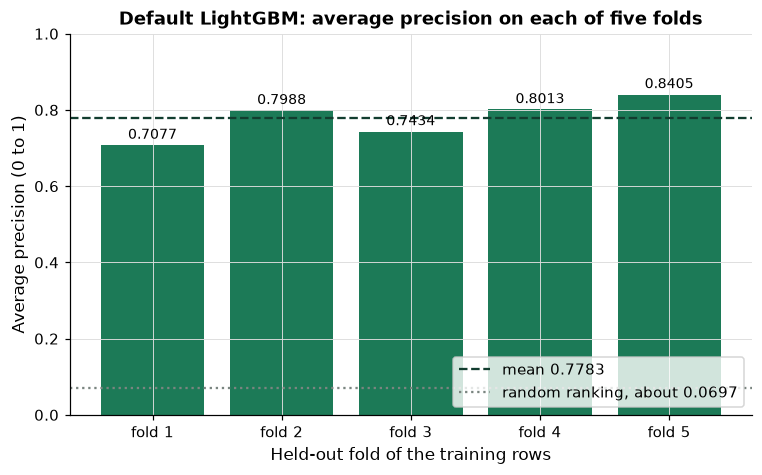

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.5))
fold_names = [f"fold {i}" for i in range(1, 6)]
# one bar per fold: the same model, scored on five different sets of held-out rows
drawn = ax.bar(fold_names, default_scores, color=plotkit.GREEN)
ax.bar_label(drawn, fmt="{:.4f}", fontsize=9, padding=2)
ax.axhline(default_scores.mean(), color=plotkit.GREEN_DARK, linestyle="--",
           label=f"mean {default_scores.mean():.4f}")
# a model that ranked the companies at random scores about the bankrupt share
ax.axhline(y_train.mean(), color=plotkit.GREY, linestyle=":", label=f"random ranking, about {y_train.mean():.4f}")
ax.set_ylim(0, 1)
ax.set_title("Default LightGBM: average precision on each of five folds")
ax.set_xlabel("Held-out fold of the training rows")
ax.set_ylabel("Average precision (0 to 1)")
ax.legend(loc="lower right")
plt.show()

* Fold 1 scores 0.7077 and fold 5 scores 0.8405: 0.1328 apart, for one model with nothing changed. Every bar sits far above the random line; the spread between the bars is the rows, not the model.

Q. A grid search over three settings with two values each: how many models does it fit?

In [16]:
from sklearn.model_selection import ParameterGrid

# two values of each of three settings: every combination is a candidate
grid = {'num_leaves': [15, 31], 'learning_rate': [0.05, 0.1], 'min_child_samples': [10, 40]}
n_candidates = len(ParameterGrid(grid))
print(f"candidates: {n_candidates}; models fitted with 5 folds: {n_candidates * 5}, plus 1 refit on all rows")

# five values of each setting: the count multiplies
grid_five = {'num_leaves': [8, 16, 31, 48, 63], 'learning_rate': [0.02, 0.05, 0.1, 0.2, 0.3], 'min_child_samples': [5, 10, 20, 40, 60]}
print(f"five values of each: {len(ParameterGrid(grid_five))} candidates, {len(ParameterGrid(grid_five)) * 5} models")

candidates: 8; models fitted with 5 folds: 40, plus 1 refit on all rows
five values of each: 125 candidates, 625 models


* A grid's cost is candidates times folds. Two values of three settings is 8 candidates and 40 fitted models; five values of each is 125 candidates and 625 models. Every setting added multiplies the count again.
* And for all that cost, the 8-candidate grid tries only two values of each setting. If the best `num_leaves` is 22, a grid of 15 and 31 never sees it.
* The next five sections spend a grid for real, then replace it with other ways of choosing candidates.

## 11.2 Rung 1: a Plain Loop

**How it works.** A hyperparameter search looks for the settings, chosen before the fit, that score best. Every method in it does the same four things: write down candidate settings, fit a model for each, score each by the same folds, and keep the best. They differ only in how the candidates are written down. The plainest way is a Python loop: a list of values, a `for` loop that sets the setting, fits on four folds, scores the fifth, and appends the mean to a list; two settings are two loops, one inside the other. You control the lists, the folds, and the score. What comes out is one score per candidate and the best row. The next four sections climb a ladder of ways to write the candidates down, on one model, one set of rows, and one set of folds, so their scores compare.

**The rows of the ladder.** The Polish file has no validation rows, and Course 4's 1,170 test rows are closed. So the ladder cuts a check set out of the training rows first: it searches 80 percent of them, and each rung's winner is scored once on the other 20 percent at the end.

Q. Cut the check rows out of the training rows, and fix the folds and the number of trees for every rung.

In [17]:
from sklearn.model_selection import train_test_split

# the ladder searches 80 percent of the training rows; the other 20 percent are the check, scored once per rung at the end
X_tune, X_check, y_tune, y_check = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
# the same five stratified folds of the tuning rows for every rung, so the rungs' scores compare
ladder_folds = mlkit.cv_folds()
# every candidate keeps 100 trees, as the default model does; the rungs change the shape of the trees and the step size
LADDER_TREES = 100
print(f"tuning rows: {len(X_tune):,}, of which bankrupt {int(y_tune.sum())}; check rows: {len(X_check):,}, of which bankrupt {int(y_check.sum())}")

tuning rows: 3,744, of which bankrupt 261; check rows: 936, of which bankrupt 65


* 3,744 tuning rows with 261 bankrupt companies, and 936 check rows with 65. The split is stratified, so both keep the bankrupt share, and it uses the course seed. The check rows take no part in any search below.
* `ladder_folds` is the course's five stratified folds, cut from the tuning rows. Every rung is scored by them.
* Only 65 bankrupt companies are in the check rows, so a check score moves by a few hundredths when a handful of companies change places. The check column at the end is for reading, not for ranking the rungs.

Q. Which settings does the ladder search, and over what values?

In [18]:
# day 9's table marks six settings "tune first"; a grid over six settings with four values each would be this many candidates
print(f"four values of six settings: {4 ** 6:,} candidates, {4 ** 6 * 5:,} fits")

space_table = pd.DataFrame([
    ("num_leaves", "tune first", "4, 8, 16, 31", "the main size control of a tree; on the card file day 9's sweeps put the best value below the default of 31"),
    ("learning_rate", "tune first, with n_estimators", "0.05, 0.1, 0.2", "the step each tree takes; the trees stay at 100, so the rate decides how far the model goes"),
    ("min_child_samples", "tune first", "default 20", "a third axis would multiply the grid by 4; section 11.7's search adds it"),
    ("n_estimators", "tune first, with learning_rate", "default 100", "it moves with the rate (day 8's early stopping chooses it); fixed here so two settings carry the lesson"),
    ("reg_lambda, subsample, colsample_bytree", "tune first", "defaults", "each would need an axis of its own; the ladder keeps two, so that a heatmap can show the whole search"),
], columns=["setting", "day 9's table", "values searched", "why"]).set_index("setting")
display(plotkit.styled(space_table, [], "The search space of rungs 1 to 4, built from day 9's table of LGBMClassifier settings")
        .set_properties(**{"text-align": "left", "white-space": "normal"}))

four values of six settings: 4,096 candidates, 20,480 fits


,day 9's table,values searched,why
setting,,,
num_leaves,tune first,"4, 8, 16, 31",the main size control of a tree; on the card file day 9's sweeps put the best value below the default of 31
learning_rate,"tune first, with n_estimators","0.05, 0.1, 0.2","the step each tree takes; the trees stay at 100, so the rate decides how far the model goes"
min_child_samples,tune first,default 20,a third axis would multiply the grid by 4; section 11.7's search adds it
n_estimators,"tune first, with learning_rate",default 100,it moves with the rate (day 8's early stopping chooses it); fixed here so two settings carry the lesson
"reg_lambda, subsample, colsample_bytree",tune first,defaults,"each would need an axis of its own; the ladder keeps two, so that a heatmap can show the whole search"


* Day 9's table shaded six groups of settings "tune first" (the learning rate and the number of trees count as one). A grid of four values of each group would be 4,096 candidates and 20,480 fits, so the ladder searches the two that size the trees and set the step, and leaves the rest at the defaults the table printed. Section 11.7's search at full size adds a third, `min_child_samples`.
* The ranges come from day 9's table: `num_leaves` stops at the default of 31, because on the card file day 9 found the best values below it, and the learning rate runs from 0.05 to 0.2 with the trees fixed at 100.

Q. Rung 1. Loop over four values of `num_leaves`, scoring each by the five folds.

In [19]:
from sklearn.metrics import average_precision_score

# rung 1: a plain loop over a list of four values of one setting, num_leaves; every other setting stays at its default
leaves_list = [4, 8, 16, 31]
loop_rows = []
for num_leaves in leaves_list:
    fold_means = []
    # five fits per value: fit on four folds of the tuning rows, score the fifth
    for train_index, valid_index in ladder_folds.split(X_tune, y_tune):
        loop_model = LGBMClassifier(n_estimators=LADDER_TREES, num_leaves=num_leaves, random_state=SEED, n_jobs=1, verbose=-1)
        loop_model.fit(X_tune.iloc[train_index], y_tune.iloc[train_index])
        output = loop_model.predict_proba(X_tune.iloc[valid_index])[:, 1]
        fold_means.append(average_precision_score(y_tune.iloc[valid_index], output))
    # one row per value: the mean of the five folds and their standard deviation
    loop_rows.append({"num_leaves": num_leaves, "mean": np.mean(fold_means), "sd": np.std(fold_means)})
loop_table = pd.DataFrame(loop_rows).set_index("num_leaves")
best_leaves = int(loop_table["mean"].idxmax())
print(loop_table.round(4).to_string())
print(f"{len(leaves_list)} values x 5 folds = {len(leaves_list) * 5} fits; the best value is num_leaves {best_leaves}")

              mean      sd
num_leaves                
4           0.7517  0.0470
8           0.7738  0.0468
16          0.7693  0.0410
31          0.7728  0.0419
4 values x 5 folds = 20 fits; the best value is num_leaves 8


* Four values and five folds: 20 fits. The loop is written out fold by fold so each fit is visible: `ladder_folds.split` gives the row numbers of the four folds to fit on and the one to score.
* The best value is `num_leaves` 8, at 0.7738. Four leaves is the weakest (0.7517); the other three lie within 0.0045 of each other, less than the smallest fold standard deviation (0.0410).

Q. Show the loop's table and draw it, with the best value marked.

,mean,sd
num_leaves,,
4,0.7517,0.0470
8,0.7738,0.0468
16,0.7693,0.0410
31,0.7728,0.0419


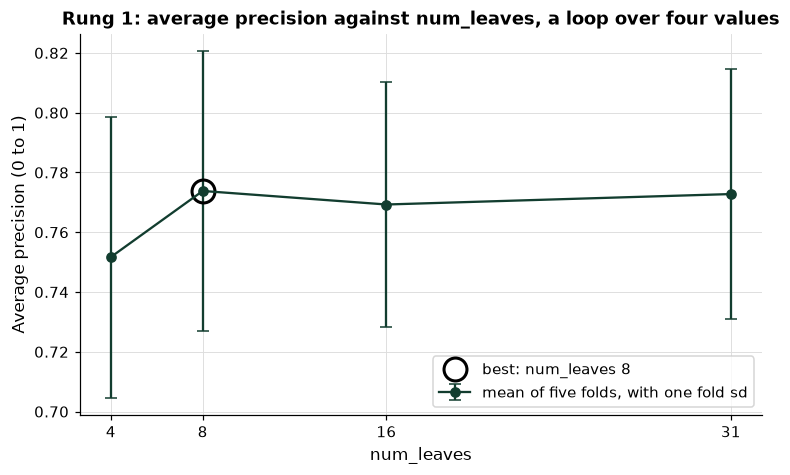

In [20]:
display(plotkit.styled(loop_table, ["mean"], "Rung 1: five-fold mean average precision for each value of num_leaves (tuning rows, other settings at their defaults)",
                       fmt="{:.4f}"))

fig, ax = plt.subplots(figsize=(8, 4.5))
# the dot is the mean of the five folds, the bar one fold standard deviation either side
ax.errorbar(loop_table.index, loop_table["mean"], yerr=loop_table["sd"], marker="o", capsize=4, color=plotkit.GREEN_DARK,
            label="mean of five folds, with one fold sd")
# the value with the highest mean is circled
ax.plot(best_leaves, loop_table.loc[best_leaves, "mean"], "o", markersize=15, fillstyle="none", markeredgecolor="black",
        markeredgewidth=2, label=f"best: num_leaves {best_leaves}")
ax.set_xticks(loop_table.index)
ax.set_title("Rung 1: average precision against num_leaves, a loop over four values")
ax.set_xlabel("num_leaves")
ax.set_ylabel("Average precision (0 to 1)")
ax.legend(loc="lower right")
plt.show()

* **How to read the picture.** The dot is the mean of the five folds and the bar is one fold standard deviation either side. The best value is circled. Every bar overlaps the others', so the loop says "not 4 leaves" and cannot say which of the other three is best.

Q. Two settings: add a loop over the learning rate inside the loop over `num_leaves`, and draw the twelve scores as a grid.

In [21]:
from sklearn.model_selection import cross_val_score

# two settings: a loop inside a loop, 4 x 3 = 12 candidates, each scored by the same five folds
rate_list = [0.05, 0.1, 0.2]
grid_scores = pd.DataFrame(index=leaves_list, columns=rate_list, dtype=float)
for num_leaves in leaves_list:
    for learning_rate in rate_list:
        nested_loop_model = LGBMClassifier(n_estimators=LADDER_TREES, num_leaves=num_leaves, learning_rate=learning_rate,
                                           random_state=SEED, n_jobs=1, verbose=-1)
        grid_scores.loc[num_leaves, learning_rate] = cross_val_score(nested_loop_model, X_tune, y_tune, cv=ladder_folds,
                                                                     scoring="average_precision", n_jobs=1).mean()
best_pair = grid_scores.stack().idxmax()
print(grid_scores.round(4).to_string())
print(f"{len(leaves_list)} x {len(rate_list)} = {grid_scores.size} candidates, {grid_scores.size * 5} fits (rung 1's one setting took {len(leaves_list) * 5})")
print(f"best pair: num_leaves {best_pair[0]}, learning_rate {best_pair[1]}")
# the column at the default learning rate of 0.1 is rung 1's loop again, scored by cross_val_score instead of the written-out folds
print(f"the learning_rate 0.1 column equals rung 1's loop, within 1e-12: {np.allclose(grid_scores[0.1].to_numpy(), loop_table['mean'].to_numpy(), atol=1e-12, rtol=0)}")

      0.05    0.10    0.20
4   0.7398  0.7517  0.7552
8   0.7665  0.7738  0.7620
16  0.7647  0.7693  0.7719
31  0.7625  0.7728  0.7758
4 x 3 = 12 candidates, 60 fits (rung 1's one setting took 20)
best pair: num_leaves 31, learning_rate 0.2
the learning_rate 0.1 column equals rung 1's loop, within 1e-12: True


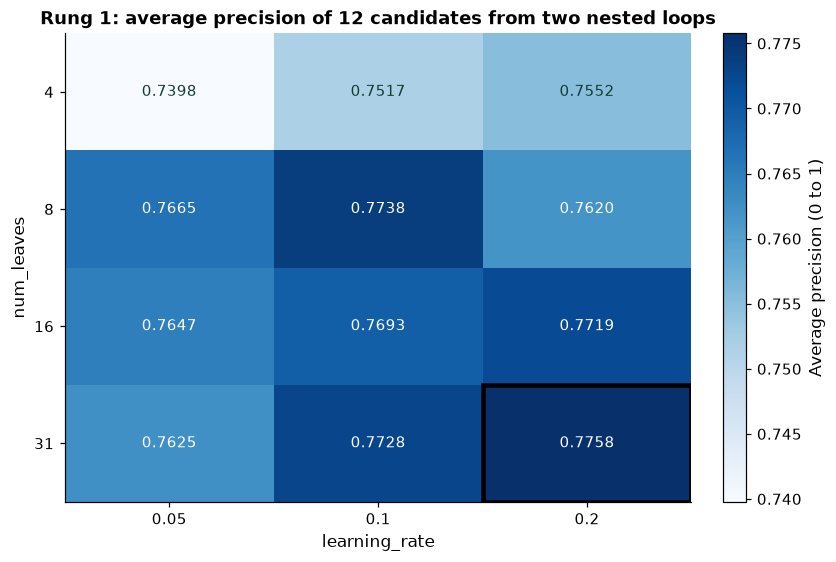

In [22]:
fig, ax = plt.subplots(figsize=(7.5, 5), layout="constrained")
image = ax.imshow(grid_scores.to_numpy(), cmap=plotkit.HEATMAP, aspect="auto")
ax.grid(False)
ax.set_xticks(range(len(rate_list)), labels=[str(rate) for rate in rate_list])
ax.set_yticks(range(len(leaves_list)), labels=[str(n) for n in leaves_list])
middle = (grid_scores.to_numpy().min() + grid_scores.to_numpy().max()) / 2
for row in range(len(leaves_list)):
    for column in range(len(rate_list)):
        value = grid_scores.iat[row, column]
        ax.text(column, row, f"{value:.4f}", ha="center", va="center", fontsize=10, color="white" if value > middle else plotkit.GREEN_DARK)
# the best candidate is outlined
best_row, best_column = np.unravel_index(grid_scores.to_numpy().argmax(), grid_scores.shape)
ax.add_patch(plt.Rectangle((best_column - 0.5, best_row - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=3))
ax.set_xlabel("learning_rate")
ax.set_ylabel("num_leaves")
ax.set_title("Rung 1: average precision of 12 candidates from two nested loops")
fig.colorbar(image, ax=ax, label="Average precision (0 to 1)")
plt.show()

* Four values of `num_leaves` and three of the learning rate is 12 candidates and 60 fits, three times rung 1's 20. A third setting with four values would be 48 candidates and 240 fits. This is how the cost grows.
* The best candidate is 31 leaves with a learning rate of 0.2, at 0.7758. The defaults (31 leaves, rate 0.1) score 0.7728, so the best of the sixteen is +0.0030 above them, less than the smallest fold standard deviation of rung 1 (0.0410).
* **How to read the heatmap.** Each cell is one candidate; darker is a higher mean, and the best is outlined. The 4-leaf row is the lowest cell in every column, and a rate of 0.05 scores below the default 0.1 at every size: with 100 trees, a small step has not got far enough. Away from those two edges the cells are close.
* The line printed under the grid checks the written-out loop of rung 1 against `cross_val_score` in the rate 0.1 column: the same numbers, so the shorter call is safe to use.

## 11.3 Rung 2: GridSearchCV

**How it works.** `GridSearchCV` is rung 1's loops written as one object. You give it a model and a dictionary of lists; it builds every combination (the `ParameterGrid` of section 11.1), fits and scores each by the folds you give it, and ranks them. A last step, the refit, fits the best combination once more on all the rows it was given, so `best_estimator_` is ready to use. You control the lists, `cv`, `scoring`, and `n_jobs`, which is 1 in the course. What comes out is `best_params_`, `best_score_` (the best mean), `best_estimator_`, and `cv_results_`, a dictionary with one entry per candidate, which `search_table` turns into a table.

Q. Run the same twelve candidates with `GridSearchCV`, and check it against the loops.

In [23]:
from sklearn.model_selection import GridSearchCV

# rung 2: GridSearchCV runs the same two loops: every pair of the two lists, scored by the same five folds
grid_search = GridSearchCV(LGBMClassifier(n_estimators=LADDER_TREES, random_state=SEED, n_jobs=1, verbose=-1),
                           {"num_leaves": leaves_list, "learning_rate": rate_list},
                           scoring="average_precision", cv=ladder_folds, n_jobs=1)
grid_search.fit(X_tune, y_tune)

found = grid_search.best_params_
print(f"GridSearchCV: best num_leaves {found['num_leaves']}, learning_rate {found['learning_rate']}, mean {grid_search.best_score_:.4f}")
print(f"the two loops' best: num_leaves {best_pair[0]}, learning_rate {best_pair[1]}, mean {grid_scores.stack().max():.4f}")

# cv_results_ holds one row per candidate; laid out as a grid it should equal the hand loops' grid
grid_results = pd.DataFrame(grid_search.cv_results_)
from_search = (grid_results.assign(num_leaves=grid_results["param_num_leaves"].astype(int),
                                   learning_rate=grid_results["param_learning_rate"].astype(float))
               .pivot(index="num_leaves", columns="learning_rate", values="mean_test_score"))
print(f"every candidate's mean equals the hand loops', within 1e-12: {np.allclose(from_search.to_numpy(), grid_scores.to_numpy(), atol=1e-12, rtol=0)}")

GridSearchCV: best num_leaves 31, learning_rate 0.2, mean 0.7758
the two loops' best: num_leaves 31, learning_rate 0.2, mean 0.7758
every candidate's mean equals the hand loops', within 1e-12: True


* The same best candidate, the same best mean, and every one of the twelve means equal to the loops' within 1e-12. `GridSearchCV` saves the code, not the cost: it fitted 12 candidates on five folds, 60 fits, plus one refit.

Q. Read `cv_results_` as a table. It holds one entry per candidate: the rank, the mean and standard deviation of the fold scores, and the settings.

In [24]:
# the twelve candidates, best first: cv_results_ keeps the rank, the mean and sd of the fold scores, and one column per setting
grid_table = (grid_results.assign(num_leaves=grid_results["param_num_leaves"].astype(int),
                                  learning_rate=grid_results["param_learning_rate"].astype(float))
              [["rank_test_score", "mean_test_score", "std_test_score", "num_leaves", "learning_rate"]]
              .rename(columns={"rank_test_score": "rank", "mean_test_score": "mean", "std_test_score": "sd"})
              .sort_values("rank", kind="stable").set_index("rank"))
display(plotkit.styled(grid_table, ["mean", "sd"],
                       "Rung 2: GridSearchCV, 12 candidates, mean and sd of average precision over the same five folds",
                       higher_is_better={"mean": True, "sd": False}, fmt="{:.4f}"))

,mean,sd,num_leaves,learning_rate
rank,,,,
1,0.7758,0.0371,31,0.2000
2,0.7738,0.0468,8,0.1000
3,0.7728,0.0419,31,0.1000
4,0.7719,0.0406,16,0.2000
5,0.7693,0.0410,16,0.1000
6,0.7665,0.0472,8,0.0500
7,0.7647,0.0409,16,0.0500
8,0.7625,0.0435,31,0.0500
9,0.7620,0.0479,8,0.2000


* The table is the heatmap again, sorted: rank 1 is the outlined cell. Its `sd` is the fold standard deviation of that candidate, and every one is larger than the gap between neighbouring means. Section 11.8 turns this reshaping into a function, `search_table`.

## 11.4 Rung 3: RandomizedSearchCV

**How it works.** A randomized search keeps `GridSearchCV`'s machinery and changes how the candidates are written down. Instead of a list per setting you write a distribution per setting, and `n_iter` says how many candidates to draw. Each candidate gets a fresh value of every setting, so 12 candidates try up to 12 values of each setting, where a 4 by 3 grid tries 4 of one and 3 of the other. That matters because usually one or two settings move the score and you do not know which. You control the distributions, `n_iter`, the folds, and the seed. What comes out is the same as the grid's: `best_params_`, `best_score_`, `best_estimator_`, and `cv_results_`.

The distributions come from `scipy.stats`, written with their bounds:

* `randint(4, 32)`: a whole number from 4 up to 31, each equally likely.
* `loguniform(0.05, 0.2)`: a number between 0.05 and 0.2, spread evenly on a log scale, so 0.05 to 0.1 is as likely as 0.1 to 0.2. Learning rates are searched this way because a step from 0.05 to 0.1 matters as much as one from 0.1 to 0.2.

Q. Spend the grid's budget, 12 candidates, on random draws from the same box.

In [25]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV

# rung 3: the same box as the grid (num_leaves 4 to 31, learning_rate 0.05 to 0.2) and the same budget, 12 candidates, but each
# setting is drawn from a distribution instead of read from a list
random_search = RandomizedSearchCV(LGBMClassifier(n_estimators=LADDER_TREES, random_state=SEED, n_jobs=1, verbose=-1),
                                   {"num_leaves": randint(4, 32), "learning_rate": loguniform(0.05, 0.2)},
                                   n_iter=12, scoring="average_precision", cv=ladder_folds, random_state=SEED, n_jobs=1)
random_search.fit(X_tune, y_tune)

# the 12 draws and the 12 grid candidates as tables of points, for the picture
random_points = pd.DataFrame({"num_leaves": random_search.cv_results_["param_num_leaves"].astype(int),
                              "learning_rate": random_search.cv_results_["param_learning_rate"].astype(float),
                              "mean": random_search.cv_results_["mean_test_score"]})
grid_points = (grid_scores.stack().rename("mean").rename_axis(["num_leaves", "learning_rate"]).reset_index())
drawn = random_search.best_params_
print(f"RandomizedSearchCV: best num_leaves {drawn['num_leaves']}, learning_rate {drawn['learning_rate']:.4f}, mean {random_search.best_score_:.4f}")
print(f"distinct values tried, random against grid: num_leaves {random_points['num_leaves'].nunique()} against {grid_points['num_leaves'].nunique()}, "
      f"learning_rate {random_points['learning_rate'].nunique()} against {grid_points['learning_rate'].nunique()}")

RandomizedSearchCV: best num_leaves 24, learning_rate 0.1379, mean 0.7788
distinct values tried, random against grid: num_leaves 11 against 4, learning_rate 12 against 3


* The same 12 candidates and 60 fits as the grid. The search tried 11 different values of `num_leaves` and 12 different learning rates; the grid tried 4 of each.
* Its best is 24 leaves with a rate of 0.1379, at 0.7788, against the grid's 0.7758: +0.0030, well inside one fold standard deviation. Do not read that as a win for random search; read the next picture.

Q. Draw both searches on the same two axes, and each candidate's score against each setting.

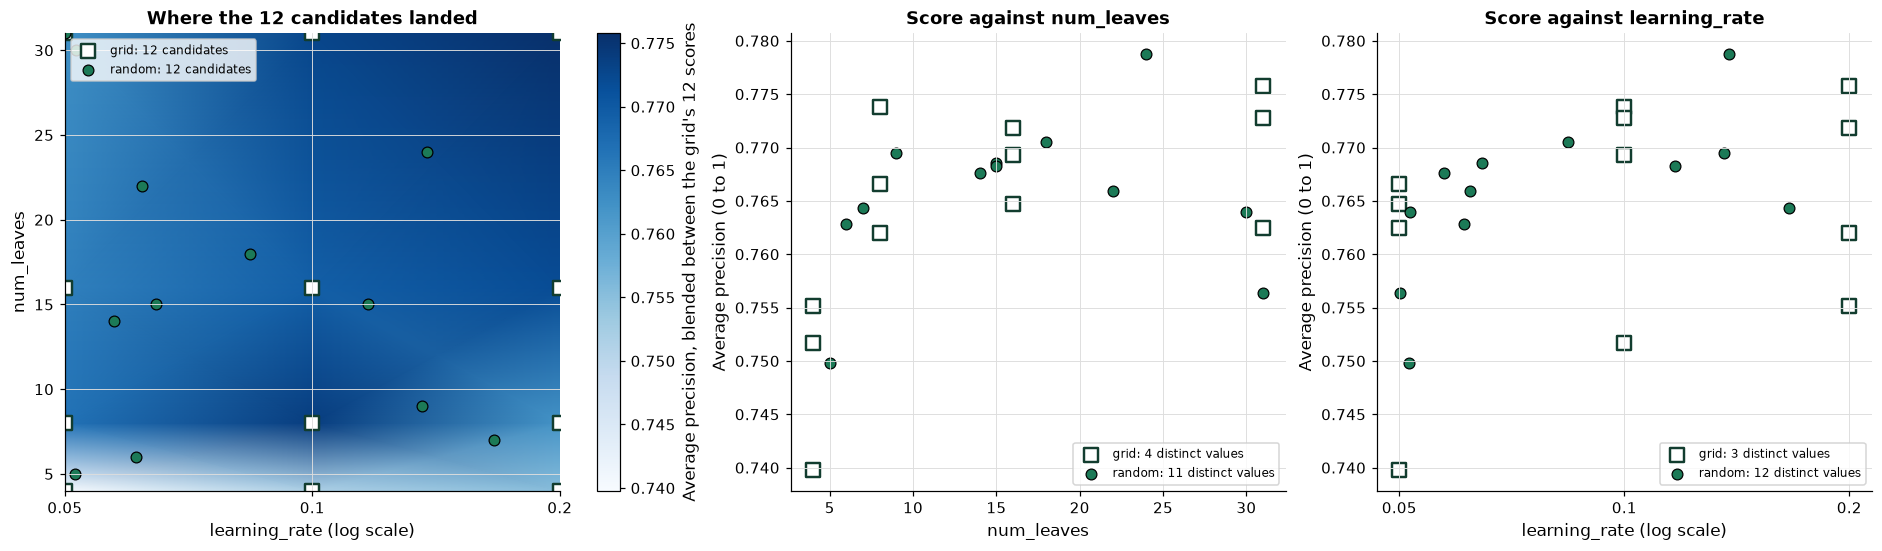

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.9), layout="constrained")
grid_style = dict(marker="s", s=75, color="white", edgecolor=plotkit.GREEN_DARK, linewidth=1.6)
random_style = dict(marker="o", s=50, color=plotkit.GREEN, edgecolor="black", linewidth=0.8)

# left: both searches on the same two axes, over the grid's 12 scores blended between the grid points
ax = axes[0]
surface = ax.pcolormesh(rate_list, leaves_list, grid_scores.to_numpy(), shading="gouraud", cmap=plotkit.HEATMAP)
ax.scatter(grid_points["learning_rate"], grid_points["num_leaves"], label="grid: 12 candidates", **grid_style)
ax.scatter(random_points["learning_rate"], random_points["num_leaves"], label="random: 12 candidates", **random_style)
ax.set_xscale("log")
ax.set_xticks(rate_list, labels=[str(rate) for rate in rate_list])
ax.minorticks_off()
ax.set_xlabel("learning_rate (log scale)")
ax.set_ylabel("num_leaves")
ax.set_title("Where the 12 candidates landed")
ax.legend(loc="upper left", fontsize=8)
fig.colorbar(surface, ax=ax, label="Average precision, blended between the grid's 12 scores")

# middle and right: each candidate's score against one setting, so the number of distinct values tried can be counted
for ax, column in [(axes[1], "num_leaves"), (axes[2], "learning_rate")]:
    ax.scatter(grid_points[column], grid_points["mean"], label=f"grid: {grid_points[column].nunique()} distinct values", **grid_style)
    ax.scatter(random_points[column], random_points["mean"], label=f"random: {random_points[column].nunique()} distinct values", **random_style)
    ax.set_xlabel(column + (" (log scale)" if column == "learning_rate" else ""))
    ax.set_ylabel("Average precision (0 to 1)")
    ax.set_title(f"Score against {column}")
    ax.legend(loc="lower right", fontsize=8)
axes[2].set_xscale("log")
axes[2].set_xticks(rate_list, labels=[str(rate) for rate in rate_list])
axes[2].minorticks_off()
plt.show()

* **How to read the picture.** Left: the squares are the grid's 12 candidates and the circles the random search's, on the same two axes, over the grid's scores blended between its points. The grid sits on 3 columns and 4 rows; the circles fall between them. Middle and right: one setting at a time, each candidate's score against that setting. The grid's squares stack in vertical lines, so it sees the score at 4 values of `num_leaves` and 3 of the learning rate. The random circles see 11 and 12.
* **Why that helps.** If the score depends mostly on `num_leaves`, the 12 grid candidates are really 4 tests of it, repeated 3 times with the learning rate changed. The 12 random candidates are 12 tests of it. You rarely know in advance which setting matters, and random draws cover whichever one it is.
* **A caution.** The picture shows coverage, and coverage is the claim: for the same number of fits, a random search looks at more values. The best scores differ by 0.0030 here, which these folds cannot tell from luck.

## 11.5 Rung 4: a Mini Optuna Study

**How it works.** Optuna searches by learning from its own trials. You write an `objective(trial)` function. It asks the trial for a value of each setting (`suggest_int` for a whole number, `suggest_float` with `log=True` for a rate), fits the model, and returns a score. A study calls the function again and again. The default sampler, TPE, spends its first trials at random; after that it sorts the trials so far into the better ones and the rest, and draws the next candidate where the better ones were dense. You control the ranges, the number of trials, the number of random starts, and the seed. What comes out is a study: `best_params`, `best_value`, and `trials_dataframe()`, one row per trial. Pruning, which stops a trial that is going badly before it finishes, is the next step, and it is not used here. Optuna is pinned in `requirements.txt` as `optuna==5.0.0`.

Q. Run a study of 12 trials on the same box, the same model, and the same folds.

In [27]:
import optuna

# only warnings and errors are printed; without this, Optuna prints a line for every trial
optuna.logging.set_verbosity(optuna.logging.WARNING)
print(f"optuna {optuna.__version__}")


def objective(trial):
    """One trial: draw the two settings, fit and score by the same five folds, and return the score to maximise."""
    num_leaves = trial.suggest_int("num_leaves", 4, 31)
    learning_rate = trial.suggest_float("learning_rate", 0.05, 0.2, log=True)
    trial_model = LGBMClassifier(n_estimators=LADDER_TREES, num_leaves=num_leaves, learning_rate=learning_rate,
                                 random_state=SEED, n_jobs=1, verbose=-1)
    return cross_val_score(trial_model, X_tune, y_tune, cv=ladder_folds, scoring="average_precision", n_jobs=1).mean()


# rung 4: the first 6 trials are random; from the 7th, TPE draws where the earlier trials scored well
study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED, n_startup_trials=6))
study.optimize(objective, n_trials=12, n_jobs=1)

trial_table = study.trials_dataframe()
print(f"Optuna: best num_leaves {study.best_params['num_leaves']}, learning_rate {study.best_params['learning_rate']:.4f}, value {study.best_value:.4f}")
print(f"found at trial {study.best_trial.number + 1} of {len(trial_table)}; trials 1 to 6 are random, trials 7 to {len(trial_table)} are guided")

optuna 5.0.0


Optuna: best num_leaves 13, learning_rate 0.1895, value 0.7785
found at trial 11 of 12; trials 1 to 6 are random, trials 7 to 12 are guided


* `optuna.logging.set_verbosity(optuna.logging.WARNING)` silences the line Optuna prints for every trial. `TPESampler(seed=SEED, n_startup_trials=6)` fixes the draws, so every run of the notebook gives the same study, and makes the first 6 trials random. TPE's own default is 10 random trials, which would leave only 2 of the 12 guided.
* The study's best is 13 leaves with a rate of 0.1895, at 0.7785, found at trial 11. The six random starts alone reached 0.7778, so the 6 guided trials added 0.0007.

Q. Draw the best score so far for the three searches that spent 16 candidates, and where Optuna looked.

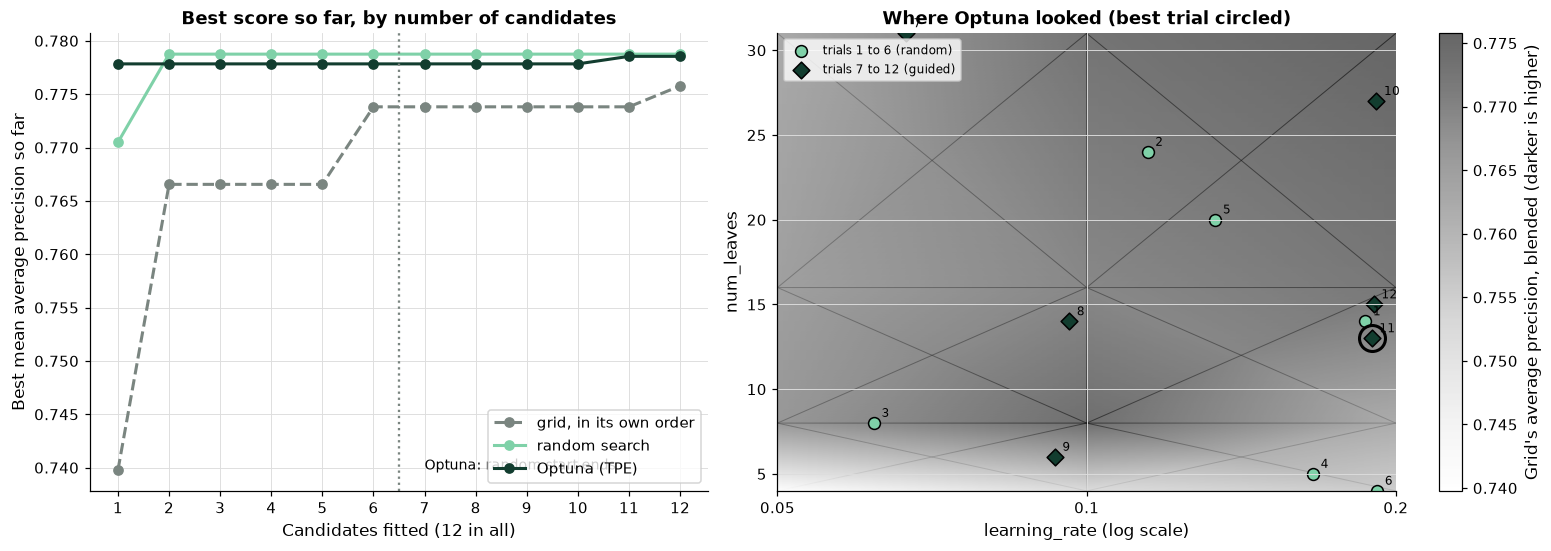

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.9), layout="constrained")
trial_number = np.arange(1, 13)
# left: the best score so far after each candidate, for the three searches that spend 12 candidates
for label, scores, style in [("grid, in its own order", grid_search.cv_results_["mean_test_score"], dict(color=plotkit.GREY, linestyle="--")),
                             ("random search", random_search.cv_results_["mean_test_score"], dict(color=plotkit.GREEN_LIGHT)),
                             ("Optuna (TPE)", trial_table["value"].to_numpy(), dict(color=plotkit.GREEN_DARK))]:
    axes[0].plot(trial_number, np.maximum.accumulate(scores), marker="o", linewidth=2, label=label, **style)
axes[0].axvline(6.5, color=plotkit.GREY, linestyle=":")
axes[0].annotate("Optuna: random start ends", (6.5, axes[0].get_ylim()[0]), xytext=(7, axes[0].get_ylim()[0] + 0.002), fontsize=9)
axes[0].set_xticks(trial_number)
axes[0].set_xlabel("Candidates fitted (12 in all)")
axes[0].set_ylabel("Best mean average precision so far")
axes[0].set_title("Best score so far, by number of candidates")
axes[0].legend(loc="lower right")

# right: where Optuna looked, over the grid's scores; the first 6 trials are circles, the guided ones diamonds
ax = axes[1]
surface = ax.pcolormesh(rate_list, leaves_list, grid_scores.to_numpy(), shading="gouraud", cmap="Greys", alpha=0.6)
early, guided = trial_table[trial_table["number"] < 6], trial_table[trial_table["number"] >= 6]
ax.scatter(early["params_learning_rate"], early["params_num_leaves"], marker="o", s=60, color=plotkit.GREEN_LIGHT, edgecolor="black", label="trials 1 to 6 (random)")
ax.scatter(guided["params_learning_rate"], guided["params_num_leaves"], marker="D", s=60, color=plotkit.GREEN_DARK, edgecolor="black", label="trials 7 to 12 (guided)")
# the trial numbers, so the order of the guided search can be followed
for _, trial_row in trial_table.iterrows():
    ax.annotate(str(int(trial_row["number"]) + 1), (trial_row["params_learning_rate"], trial_row["params_num_leaves"]),
                textcoords="offset points", xytext=(5, 4), fontsize=8)
best_row = trial_table.loc[trial_table["value"].idxmax()]
ax.plot(best_row["params_learning_rate"], best_row["params_num_leaves"], "o", markersize=17, fillstyle="none", markeredgecolor="black", markeredgewidth=2)
ax.set_xscale("log")
ax.set_xticks(rate_list, labels=[str(rate) for rate in rate_list])
ax.minorticks_off()
ax.set_xlabel("learning_rate (log scale)")
ax.set_ylabel("num_leaves")
ax.set_title("Where Optuna looked (best trial circled)")
ax.legend(loc="upper left", fontsize=8)
fig.colorbar(surface, ax=ax, label="Grid's average precision, blended (darker is higher)")
plt.show()

* **How to read the picture.** Left: after each candidate, the best mean found so far, for the grid in its own order, the random search, and Optuna. A line that rises early found a good region early. Right: Optuna's trials on the two axes, over the grid's scores in grey; circles are the random starts, diamonds the guided trials, numbered in order, and the best is circled.
* On these 12 trials Optuna (0.7785) did not beat the random search (0.7788), and both are above the grid (0.7758) by less than one fold standard deviation. With 12 trials only 6 are guided, which is little for TPE to learn from.
* **When it pays.** Optuna earns its keep when each trial is slow and the space is large, so every wasted trial costs a lot. This file is small and the box has two settings. The ladder's point is how the methods differ, not which wins here.

## 11.6 The Four Rungs Side by Side

Q. Put the rungs in one table: candidates, fits, the best five-fold mean, and the winner's score on the check rows, read once.

In [29]:
def check_score(**settings):
    """Refit on all the tuning rows with the winner's settings, and score the check rows once (average precision)."""
    final = LGBMClassifier(n_estimators=LADDER_TREES, random_state=SEED, n_jobs=1, verbose=-1, **settings).fit(X_tune, y_tune)
    return average_precision_score(y_check, final.predict_proba(X_check)[:, 1])


def settings_text(settings):
    return ", ".join(f"{name} {value:.3f}" if name == "learning_rate" else f"{name} {int(value)}" for name, value in settings.items())


# each rung's winner: its candidates, the fits the search used, its best five-fold mean, and the check score
winners = [
    ("no search: the defaults", 1, 5, grid_scores.loc[31, 0.1], dict(num_leaves=31, learning_rate=0.1)),
    ("1 loop over num_leaves", 4, 20, loop_table["mean"].max(), dict(num_leaves=best_leaves)),
    ("1 two nested loops", 12, 60, grid_scores.stack().max(), dict(num_leaves=best_pair[0], learning_rate=best_pair[1])),
    ("2 GridSearchCV", 12, 60, grid_search.best_score_, dict(grid_search.best_params_)),
    ("3 RandomizedSearchCV", 12, 60, random_search.best_score_, dict(random_search.best_params_)),
    ("4 Optuna (TPE)", 12, 60, study.best_value, dict(study.best_params)),
]
ladder = pd.DataFrame({
    "candidates": [w[1] for w in winners],
    "fits in the search": [w[2] for w in winners],
    "best five-fold mean (tuning rows)": [float(w[3]) for w in winners],
    "check rows, read once": [float(check_score(**w[4])) for w in winners],
    "settings of the winner": [settings_text(w[4]) for w in winners],
}, index=pd.Index([w[0] for w in winners], name="rung"))
print(ladder[["candidates", "fits in the search", "best five-fold mean (tuning rows)", "check rows, read once"]].round(4).to_string())

                         candidates  fits in the search  best five-fold mean (tuning rows)  check rows, read once
rung                                                                                                             
no search: the defaults           1                   5                             0.7728                 0.8034
1 loop over num_leaves            4                  20                             0.7738                 0.8130
1 two nested loops               12                  60                             0.7758                 0.7998
2 GridSearchCV                   12                  60                             0.7758                 0.7998
3 RandomizedSearchCV             12                  60                             0.7788                 0.8221
4 Optuna (TPE)                   12                  60                             0.7785                 0.8174


,candidates,fits in the search,best five-fold mean (tuning rows),"check rows, read once",settings of the winner
rung,,,,,
no search: the defaults,1,5,0.7728,0.8034,"num_leaves 31, learning_rate 0.100"
1 loop over num_leaves,4,20,0.7738,0.8130,num_leaves 8
1 two nested loops,12,60,0.7758,0.7998,"num_leaves 31, learning_rate 0.200"
2 GridSearchCV,12,60,0.7758,0.7998,"learning_rate 0.200, num_leaves 31"
3 RandomizedSearchCV,12,60,0.7788,0.8221,"learning_rate 0.138, num_leaves 24"
4 Optuna (TPE),12,60,0.7785,0.8174,"num_leaves 13, learning_rate 0.189"


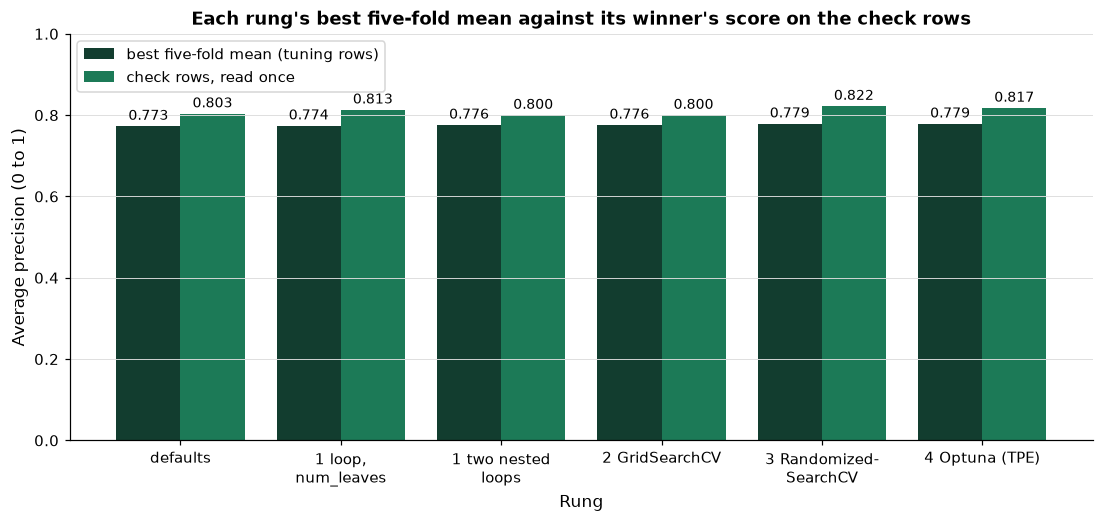

In [30]:
display(plotkit.styled(ladder, ["best five-fold mean (tuning rows)", "check rows, read once"],
                       "The four rungs: fits used, the best five-fold mean on the tuning rows, and the winner's score on the check rows (read once)",
                       fmt="{:.4f}"))

fig, ax = plt.subplots(figsize=(12, 4.8))
short = ladder.rename(index=lambda name: name.replace("no search: the defaults", "defaults").replace("RandomizedSearchCV", "Randomized-\nSearchCV")
                      .replace("two nested loops", "two nested\nloops").replace("loop over num_leaves", "loop,\nnum_leaves"))
drawn = plotkit.bars(short[["best five-fold mean (tuning rows)", "check rows, read once"]],
                     "Each rung's best five-fold mean against its winner's score on the check rows", "Average precision (0 to 1)",
                     ax=ax, fmt="{:.3f}")
ax.set_ylim(0, 1)
ax.set_xlabel("Rung")
plt.show()

* **Cost is counted in fits.** The loop over one setting used 20 fits; the twelve-candidate rungs used 60 each. The course prints no times: a clock differs on every run and every machine, and fits are what a clock would count.
* **Rung 1's two nested loops and `GridSearchCV` are the same search**, so they give the same winner and the same check score. Rungs 3 and 4 cost the same 60 fits but choose their candidates by a rule instead of a list.
* **Reading the two number columns.** The best five-fold means span 0.0060, which is inside the fold standard deviation. The check scores span 0.0222, with 65 bankrupt companies behind each. The two columns are scored on different rows, so their levels cannot be compared; the order of the rungs is not the same in the two columns, which is what noise looks like.
* **What the ladder shows.** All four methods find a candidate near the defaults' score. The rungs differ in cost per candidate and in coverage, and that is where they pay: with six settings of four values each the grid is 4,096 candidates, while a random search or an Optuna study costs whatever `n_iter` or `n_trials` says. Section 11.11 then asks how much of any best score is luck.

## 11.7 A Randomized Search at Full Size

**How it works.** This is rung 3 of the ladder on a larger job, and the search the rest of the day reads. The machinery is the same: a distribution for each setting, `n_iter` candidates drawn from them, each fitted and scored by five folds, the best kept. Three things change. The search now sees all 4,680 training rows, with no check rows set aside, so sections 11.9 to 11.11 ask what its best score is worth without them. `min_child_samples`, the third "tune first" row of day 9's table, joins `num_leaves` and `learning_rate`. And it draws 6 candidates, fewer than the ladder's 16, because three settings on all the rows cost more per candidate. You control the ranges, `n_iter`, the folds, and the seed. What comes out is `best_params_`, `best_score_`, and `cv_results_`, which sections 11.8 to 11.13 read.

Q. Search 6 candidates of a 100-tree LightGBM over three settings, scored by the same five folds.

In [31]:
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV

# one distribution per setting; every candidate keeps 100 trees, as the default model does
space = {"num_leaves": randint(8, 64), "learning_rate": loguniform(0.02, 0.3), "min_child_samples": randint(5, 60)}
search = RandomizedSearchCV(LGBMClassifier(n_estimators=100, random_state=SEED, n_jobs=1, verbose=-1), space,
                            n_iter=6, scoring="average_precision", cv=mlkit.cv_folds(),
                            random_state=SEED, n_jobs=1)
search.fit(X_train, y_train)

best = search.best_params_
print(f"best candidate: num_leaves {best['num_leaves']}, learning_rate {best['learning_rate']:.4f}, "
      f"min_child_samples {best['min_child_samples']}")
print(f"best mean average precision over the five folds: {search.best_score_:.4f}")

best candidate: num_leaves 46, learning_rate 0.1452, min_child_samples 25
best mean average precision over the five folds: 0.7760


* `random_state=SEED` on the search fixes the 6 draws, so every run tries the same candidates; `n_jobs=1` keeps every run's last digits the same. The search fitted 6 candidates on five folds each, then refitted the best one on all 4,680 rows: 31 models.
* The best candidate has `learning_rate` 0.1452, `min_child_samples` 25, `num_leaves` 46, and its mean over the five folds, `best_score_`, is 0.7760. That number is where most reports stop. Sections 11.9 to 11.11 ask what it is worth.

## 11.8 Reading the Search's Results

`search.cv_results_` holds every candidate's settings and fold scores in a dictionary of arrays. Two small functions make it readable, and make the next section honest.

Q. Add `nested_score` and `search_table` to `ensemblekit.py`.

In [32]:
%%writefile -a ensemblekit.py


def nested_score(search, X, y, outer=None, scoring: str = "average_precision") -> pd.Series:
    """An honest score for a tuned model: the whole search is repeated inside each outer fold.

    Inputs: search, an unfitted RandomizedSearchCV or GridSearchCV that carries its own inner cv; X, y, the
    training rows; outer, the outer splitter (default mlkit.cv_folds()); scoring, the metric.
    Output: one score per outer fold, indexed fold_1, fold_2, ...: each fold's search tunes on the other folds
    only and is scored on its own held-out rows (cross_val_score, n_jobs=1).
    Convention: a search's best_score_ is the best of many noisy numbers and is not an honest score of the model it
    chose; the mean of this Series is.
    Raises ValueError if the search has no inner cv.
    """
    if getattr(search, "cv", None) is None:
        raise ValueError("give the search its own inner cv, for example StratifiedKFold(3, shuffle=True, random_state=42)")
    folds = outer if outer is not None else mlkit.cv_folds()
    scores = cross_val_score(search, X, y, cv=folds, scoring=scoring, n_jobs=1)
    return pd.Series(scores, index=[f"fold_{i}" for i in range(1, len(scores) + 1)], name=scoring)


def search_table(search, top: int = 5) -> pd.DataFrame:
    """A fitted search's results as a short table, best first.

    Inputs: search, a fitted RandomizedSearchCV or GridSearchCV; top, how many candidates to keep.
    Output: columns rank, mean, sd (the mean and standard deviation of the fold scores, ddof=0, as cv_results_),
    then one column per searched parameter (the param_ prefix dropped), sorted by rank.
    Excel: =AVERAGE and =STDEV.P of a candidate's five fold scores give its mean and sd (STDEV.S does not).
    Raises ValueError if the search is not fitted.
    """
    if not hasattr(search, "cv_results_"):
        raise ValueError("the search is not fitted: call fit first")
    results = pd.DataFrame(search.cv_results_)
    params = [name for name in results.columns if name.startswith("param_")]
    table = results[["rank_test_score", "mean_test_score", "std_test_score"] + params]
    table.columns = ["rank", "mean", "sd"] + [name[len("param_"):] for name in params]
    return table.sort_values("rank", kind="stable").head(top).reset_index(drop=True)

Appending to ensemblekit.py


* `search_table` keeps the rank, the mean, the standard deviation of the fold scores, and one column per setting, best first. Its `sd` is `cv_results_`' own `std_test_score`, which divides by the number of folds (numpy's `ddof=0`).
* `nested_score` is for section 11.11: it runs the whole search again inside each outer fold. It refuses a search without its own inner `cv`, because the inner search must not use the outer folds.

Q. Add their tests, reload, and run every test.

In [33]:
%%writefile -a test_ensemblekit.py


def test_nested_score_one_per_fold():
    X, y = card_small()
    scores = ensemblekit.nested_score(small_search(), X, y)
    assert list(scores.index) == [f"fold_{i}" for i in range(1, 6)]
    assert ((scores > 0) & (scores < 1)).all()
    with pytest.raises(ValueError):
        ensemblekit.nested_score(RandomizedSearchCV(DecisionTreeClassifier(), {"max_depth": [2, 3]}, cv=None), X, y)


def test_nested_score_differs_from_best_score():
    X, y = card_small()
    scores = ensemblekit.nested_score(small_search(), X, y)
    search = small_search().set_params(cv=ensemblekit.mlkit.cv_folds()).fit(X, y)
    assert scores.mean() != pytest.approx(search.best_score_, abs=1e-6)


def test_search_table_sorted_and_columns():
    X, y = card_small()
    search = small_search().fit(X, y)
    table = ensemblekit.search_table(search, top=3)
    assert list(table.columns) == ["rank", "mean", "sd", "max_depth", "min_samples_leaf"]
    assert len(table) == 3
    assert table["rank"].is_monotonic_increasing
    assert table["mean"].iloc[0] == pytest.approx(search.best_score_, abs=1e-12)
    with pytest.raises(ValueError):
        ensemblekit.search_table(small_search())

Appending to test_ensemblekit.py


In [34]:
importlib.reload(ensemblekit)
print(f"nested_score, search_table in ensemblekit: {hasattr(ensemblekit, 'nested_score')}, {hasattr(ensemblekit, 'search_table')}")

nested_score, search_table in ensemblekit: True, True


In [35]:
import re

# run the tests in the work folder with the kernel's own Python, in a fresh process
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "test_ensemblekit.py"],
                        cwd=work, capture_output=True, text=True)
# past one minute pytest adds the run time again as h:mm:ss in brackets; run times differ every run, so it is left out
print(re.sub(r" \(\d+:\d\d:\d\d\)", "", result.stdout + result.stderr))

..........................................                               [100%]
42 passed in 15.09s



* `42 passed`: every day's tests, with today's four. `test_nested_score_differs_from_best_score` checks, on a small search of the card rows, that the nested mean is not the search's `best_score_`: the two numbers measure different things.

Q. Show every candidate the search tried, best first.

In [36]:
table = ensemblekit.search_table(search, top=6)
print(table.round(4).to_string())

   rank    mean      sd  learning_rate  min_child_samples  num_leaves
0     1  0.7760  0.0445         0.1452                 25          46
1     2  0.7747  0.0564         0.0551                 33          22
2     3  0.7742  0.0550         0.0694                 57          43
3     4  0.7710  0.0561         0.0669                 27          18
4     5  0.7629  0.0588         0.0294                  7          29
5     6  0.7591  0.0622         0.0233                 28          51


* The 6 means run from 0.7591 to 0.7760. Every candidate's fold standard deviation is between 0.0445 and 0.0622: larger than every gap between neighbouring candidates in the table. The ranking is mostly noise from which rows landed in which fold.
* Each column of settings holds 6 different values (two draws can land on the same whole number): the search covered the space more finely than the 8-candidate grid of section 11.1, which costs more and tries two.

Q. Show the same table formatted, then draw each candidate's mean with its fold standard deviation and its five fold scores.

,mean,sd,learning_rate,min_child_samples,num_leaves
rank,,,,,
1,0.7760,0.0445,0.1452,25,46
2,0.7747,0.0564,0.0551,33,22
3,0.7742,0.0550,0.0694,57,43
4,0.7710,0.0561,0.0669,27,18
5,0.7629,0.0588,0.0294,7,29
6,0.7591,0.0622,0.0233,28,51


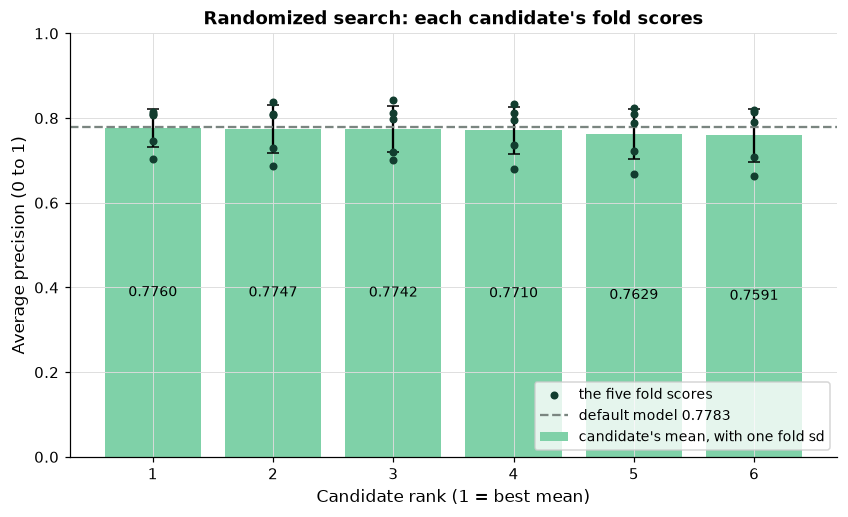

In [37]:
# cv_results_ keeps the settings as objects; as numbers they are formatted like the scores
shown = table.set_index("rank").astype({"learning_rate": float, "min_child_samples": int, "num_leaves": int})
display(plotkit.styled(shown, ["mean", "sd"],
                       "Randomized search: 6 candidates, mean and sd of average precision over the same five folds",
                       higher_is_better={"mean": True, "sd": False}, fmt="{:.4f}"))

fig, ax = plt.subplots(figsize=(9, 5))
ranks = table["rank"].to_numpy()
# each candidate's five fold scores, in the table's order (best first: sorted by rank)
order = np.argsort(search.cv_results_["rank_test_score"], kind="stable")
fold_scores = np.array([[search.cv_results_[f"split{i}_test_score"][k] for i in range(5)] for k in order])
# the bar is the mean, the error bar one fold standard deviation either side
drawn = ax.bar(ranks, table["mean"], yerr=table["sd"], capsize=4, color=plotkit.GREEN_LIGHT,
               label="candidate's mean, with one fold sd")
ax.bar_label(drawn, fmt="{:.4f}", fontsize=9, label_type="center")
# the five dots of each candidate: the scores the mean averages
for rank, candidate_folds in zip(ranks, fold_scores):
    ax.scatter(np.full(5, rank), candidate_folds, color=plotkit.GREEN_DARK, s=18, zorder=3)
ax.scatter([], [], color=plotkit.GREEN_DARK, s=18, label="the five fold scores")
ax.axhline(default_scores.mean(), color=plotkit.GREY, linestyle="--", label=f"default model {default_scores.mean():.4f}")
ax.set_ylim(0, 1)
ax.set_xticks(ranks)
ax.set_title("Randomized search: each candidate's fold scores")
ax.set_xlabel("Candidate rank (1 = best mean)")
ax.set_ylabel("Average precision (0 to 1)")
ax.legend(loc="lower right", fontsize=9)
plt.show()

* The means differ by at most 0.0169; every candidate's own five folds span at least 0.1130. Fold 1 is the lowest dot of every candidate, and of the default model in section 11.1: the folds, not the settings, make most of the spread.

## 11.9 How Much Did Tuning Buy?

Q. Put the search's best beside the default model, on the same five folds.

In [38]:
gain = search.best_score_ - default_scores.mean()
print(f"default LightGBM:      {default_scores.mean():.4f}")
print(f"search's best:         {search.best_score_:.4f}")
print(f"gain from tuning:      {gain:+.4f}")
print(f"default's fold standard deviation: {default_scores.std():.4f}")

default LightGBM:      0.7783
search's best:         0.7760
gain from tuning:      -0.0024
default's fold standard deviation: 0.0469


* The best of 6 candidates scores **below** the default, by -0.0024 of average precision, inside one fold standard deviation of the default model (0.0469): LightGBM's own defaults were not among the candidates, and none of the 6 drawn beat them.
* And this comparison favours the search twice. It took the **best** of 6 noisy numbers, and it picked that candidate on the same five folds it is scored on. Section 11.10 measures how much a mean moves by chance; section 11.11 removes the second advantage.

## 11.10 The Same Model on Other Folds

**How it works.** A cross-validated score depends on which rows happen to land in which fold. To see how much, keep the model and the rows fixed and change only the shuffle seed that cuts the folds. Each seed gives a different set of five folds; the same model is scored on each, and the means are compared. Their range is the movement that comes from the cut alone, with nothing about the model changed. You control the seeds, here `SEED` and three seeds after it. What comes out is one mean per cut and a range to hold a tuning gain against.

`mlkit.cv_folds()` shuffles the rows with `SEED` before cutting five folds. Another seed cuts other folds from the same rows. The model does not change; only which rows score it.

Q. Score the default model again on three other fold seeds.

In [39]:
from sklearn.model_selection import StratifiedKFold

# the same default model, the same rows, four ways of cutting five folds
fold_seed_means = {SEED: default_scores.mean()}
for shift in (1, 2, 3):
    # the course's splitter with its seed moved on purpose: the rows are shuffled with SEED + 1, SEED + 2, or SEED + 3
    folds = StratifiedKFold(5, shuffle=True, random_state=SEED + shift)
    scores = cross_val_score(default_model, X_train, y_train, cv=folds, scoring="average_precision", n_jobs=1)
    fold_seed_means[SEED + shift] = scores.mean()

for fold_seed, mean in fold_seed_means.items():
    print(f"fold seed {fold_seed}: mean average precision {mean:.4f}")
spread = max(fold_seed_means.values()) - min(fold_seed_means.values())
print(f"range across the four fold seeds: {spread:.4f}; gain from tuning: {gain:.4f}")

fold seed 42: mean average precision 0.7783
fold seed 43: mean average precision 0.7766
fold seed 44: mean average precision 0.7841
fold seed 45: mean average precision 0.7838
range across the four fold seeds: 0.0075; gain from tuning: -0.0024


* The default model's mean runs from 0.7766 to 0.7841 on four cuts of the same rows: a range of 0.0075, with nothing about the model changed.
* **The gap between the search's best and the default, -0.0024, is smaller than the change from reshuffling the folds.** On these rows, the candidates and the default cannot be told apart from the luck of the cut.

Q. Draw the search's candidates beside the range the default model covers on four cuts of the folds.

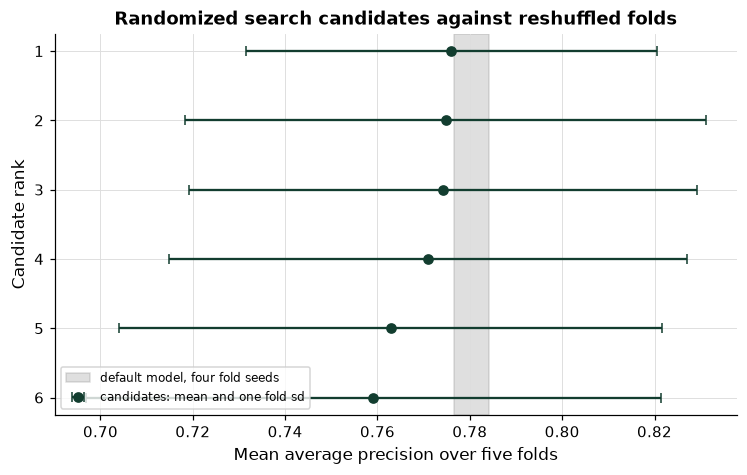

In [40]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))
ranks = table["rank"].to_numpy()
# each candidate's mean, with a bar of one fold standard deviation either side
ax.errorbar(table["mean"], ranks, xerr=table["sd"], fmt="o", capsize=3, label="candidates: mean and one fold sd")
# the default model's mean on four cuts of the folds, as a band
ax.axvspan(min(fold_seed_means.values()), max(fold_seed_means.values()), alpha=0.25, color="grey",
           label="default model, four fold seeds")
ax.set_yticks(ranks)
ax.invert_yaxis()
ax.set_title("Randomized search candidates against reshuffled folds")
ax.set_xlabel("Mean average precision over five folds")
ax.set_ylabel("Candidate rank")
ax.legend(loc="lower left", fontsize=8)
plt.show()

* The grey band is the default model alone, scored on four cuts of the same rows. The bars around each candidate are wider than the whole table's spread of means: on five folds of these rows, the candidates cannot be told apart with confidence.

## 11.11 Nested Cross-Validation: an Honest Score

**How it works.** `best_score_` is the best of 6 means, each measured on the five folds that also chose it, so it is flattered by the choosing. Nested cross-validation scores the whole procedure, search and choice and refit, on rows that took no part in choosing. Hold out one outer fold, run the complete search on the other four with its own inner folds, refit the winner on those four, and score it on the held-out fold; then repeat for each outer fold. You control the outer folds, the inner folds, and the search itself. What comes out is five honest scores, one per outer fold, whose mean is the score of the procedure, not of one set of settings. The steps in order:

1. Hold out one outer fold.
2. Run the complete search on the other four folds only, with its own inner folds to choose a candidate.
3. Refit the chosen candidate on those four folds and score it on the held-out fold.
4. Repeat for each of the five outer folds.

The held-out fold takes no part in choosing, so its score is honest. That is `nested_score`. The inner search uses two folds (StratifiedKFold(2, shuffle=True, random_state=SEED)), so each outer fold fits 6 candidates times 2, plus a refit: 65 models in all.

Q. Score the randomized search by nested cross-validation.

In [41]:
# the same search, with its own inner folds; the outer folds are mlkit.cv_folds()
inner_search = RandomizedSearchCV(LGBMClassifier(n_estimators=100, random_state=SEED, n_jobs=1, verbose=-1), space,
                                  n_iter=6, scoring="average_precision",
                                  cv=StratifiedKFold(2, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=1)
nested = ensemblekit.nested_score(inner_search, X_train, y_train)

print(nested.round(4).to_string())
print(f"nested mean {nested.mean():.4f}, fold standard deviation {nested.std():.4f}")
print(f"search's best_score_ {search.best_score_:.4f}; default model {default_scores.mean():.4f}")

fold_1    0.6792
fold_2    0.8120
fold_3    0.7358
fold_4    0.8153
fold_5    0.8062
nested mean 0.7697, fold standard deviation 0.0603
search's best_score_ 0.7760; default model 0.7783


* The nested folds run from 0.6792 to 0.8153, and their mean is 0.7697: below `best_score_` (0.7760) and below the default model (0.7783, -0.0086).
* Once the search has to choose without seeing the rows that score it, the tuned LightGBM does no better than the default one on these rows. The search's 0.7760 was the best of 6 noisy numbers, and even that best stayed below the default; the nested mean, lower still, shows the same thing honestly.
* The rule for the rest of the course: when a tuned model's cross-validated score is reported on rows it was also tuned on, the nested score is reported beside it.

Q. Put the three numbers in one table and one chart: the default model, the search's `best_score_`, and the nested score, each with its fold standard deviation.

,mean average precision,fold sd,rows that chose the settings
score,,,
default LightGBM,0.7783,0.0469,none chosen
search's best_score_,0.7760,0.0445,the same five folds
"search, nested",0.7697,0.0603,inner folds only


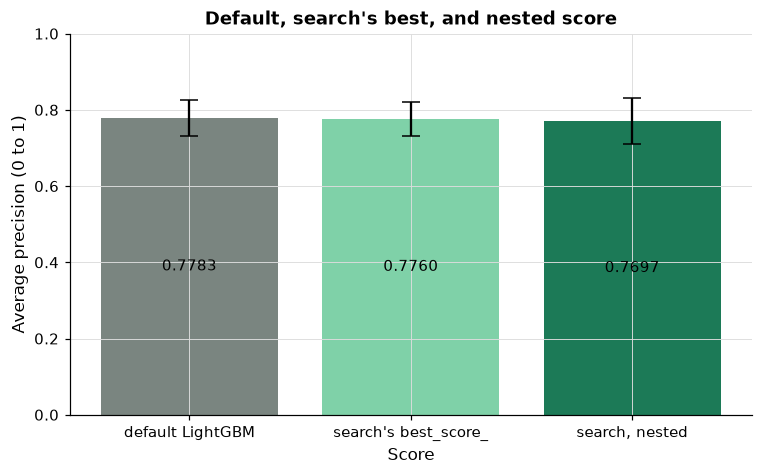

In [42]:
three = pd.DataFrame({
    "mean average precision": [default_scores.mean(), search.best_score_, nested.mean()],
    "fold sd": [default_scores.std(), search.cv_results_["std_test_score"][search.best_index_], nested.std()],
    "rows that chose the settings": ["none chosen", "the same five folds", "inner folds only"],
}, index=pd.Index(["default LightGBM", "search's best_score_", "search, nested"], name="score"))
display(plotkit.styled(three, ["mean average precision"],
                       "Three scores of LightGBM on the training rows: five outer folds, mean and fold sd",
                       fmt="{:.4f}"))

fig, ax = plt.subplots(figsize=(8, 4.5))
# the bar is the mean over five folds, the error bar one fold standard deviation either side
drawn = ax.bar(three.index, three["mean average precision"], yerr=three["fold sd"], capsize=6,
               color=[plotkit.GREY, plotkit.GREEN_LIGHT, plotkit.GREEN])
ax.bar_label(drawn, fmt="{:.4f}", fontsize=10, label_type="center")
ax.set_ylim(0, 1)
ax.set_title("Default, search's best, and nested score")
ax.set_xlabel("Score")
ax.set_ylabel("Average precision (0 to 1)")
plt.show()

* The three bars are within 0.0086 of each other, and each error bar is about 0.04 to 0.06 either side: on these rows the three cannot be told apart. Only the nested bar was scored on rows that took no part in choosing.

Q. Put the nested score beside the default model's score, outer fold by outer fold.

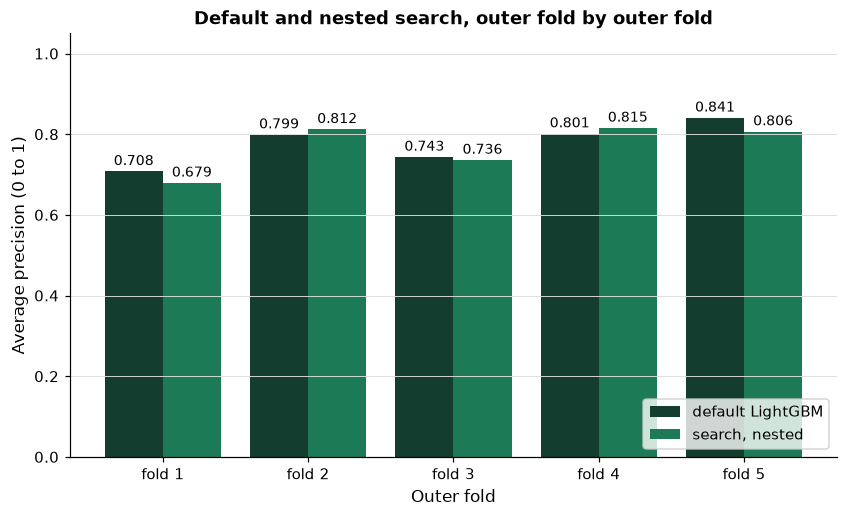

In [43]:
# the outer folds are mlkit.cv_folds(), the same five folds that scored the default model in section 11.1
by_fold = pd.DataFrame({"default LightGBM": default_scores, "search, nested": nested.to_numpy()},
                       index=pd.Index([f"fold {i}" for i in range(1, 6)], name="Outer fold"))
ax = plotkit.bars(by_fold, "Default and nested search, outer fold by outer fold", "Average precision (0 to 1)",
                  fmt="{:.3f}")
ax.set_ylim(0, 1.05)
ax.legend(loc="lower right")
plt.show()

* Fold 1 is the hardest for both, and the nested search scores higher than the default on 2 of the five folds. Each pair of bars moves together from fold to fold: the rows set the level, and the search moves it a little either way.

## 11.12 What to Tune First, and When to Stop

This is practice that has served well, not a rule:

* **Start simple,** as the ladder did: a loop over a short list tells you whether a setting matters at all; reach for a search class, then a random search, then Optuna, only as the number of settings and the cost of a fit grow.
* **Start from the defaults and score them,** as section 11.1 did. The defaults of LightGBM and XGBoost are sensible for tables of this size, and they are the baseline every search must beat.
* **Tune the settings that size the trees first:** `num_leaves` (or `max_depth`) and the rows per leaf (`min_child_samples`). Then the learning rate together with the number of trees, because a lower rate needs more trees; early stopping (day 8) chooses the number of trees for a given rate. Sampling rows and columns, and the penalties, come after.
* **Fix the budget before you look:** the number of candidates and the folds, written in the code, as `n_iter=6` is here. Searching again until a number looks good is choosing on noise.
* **Stop when the gain is inside the noise:** smaller than one fold standard deviation, or than the change from reshuffling the folds (section 11.10).
* **Log every search,** with its nested score beside its best score, in `results.csv`.

## 11.13 The Threshold Is a Choice Too

**How it works.** A desk that wants a flag also needs a threshold, and a threshold belongs to one model's scale of outputs. Course 4's rule takes the highest threshold whose recall is at least 0.70. Course 5 applies it to out-of-fold probabilities on the training rows (`oof_threshold`, day 5), so every output comes from a model that did not see its row and the rule never touches rows held back for reporting. You control the recall target and the folds. What comes out is one threshold per model, and the flags and recall and precision it gives.

Q. Choose the threshold for the default model and for the search's chosen model.

In [44]:
# each model's threshold, out-of-fold outputs, flags, and metrics, kept for the table and charts below
chosen = {}
for name, model in [("default", default_model), ("tuned", search.best_estimator_)]:
    # out-of-fold probabilities on the training rows (fresh copies are fitted; the model is left as it was)
    threshold, proba = ensemblekit.oof_threshold(model, X_train, y_train)
    flags = (proba >= threshold).astype(int)
    metrics = mlkit.classification_metrics(y_train, flags)
    chosen[name] = {"threshold": threshold, "proba": proba, "flags": flags, "metrics": metrics}
    print(f"{name}: threshold {threshold:.4f}, flagged {flags.sum()} of {len(flags):,}, "
          f"recall {metrics['recall']:.4f}, precision {metrics['precision']:.4f}")

default: threshold 0.0818, flagged 327 of 4,680, recall 0.7025, precision 0.7003


tuned: threshold 0.0181, flagged 336 of 4,680, recall 0.7025, precision 0.6815


* Each output is the model probability of bankruptcy in this file, from the fold model that did not see the row; a company is flagged at the threshold shown. The two models need different thresholds (0.0818 and 0.0181) for the same recall: changing the settings changed the scale of the outputs, so **a threshold chosen for one model is no threshold for another**. It is chosen again after every search.
* The recall of at least 0.70 holds on these rows by construction, because the threshold was chosen on them. The precision beside it (0.7003 and 0.6815) is an in-sample number for the threshold, in the same way `best_score_` is for the settings: one more choice made on the training rows.

Q. Show the two thresholds in a table, and draw where each model's outputs fall, with its threshold marked.

,threshold,flagged,recall,precision
model,,,,
default,0.0818,327,0.7025,0.7003
tuned,0.0181,336,0.7025,0.6815


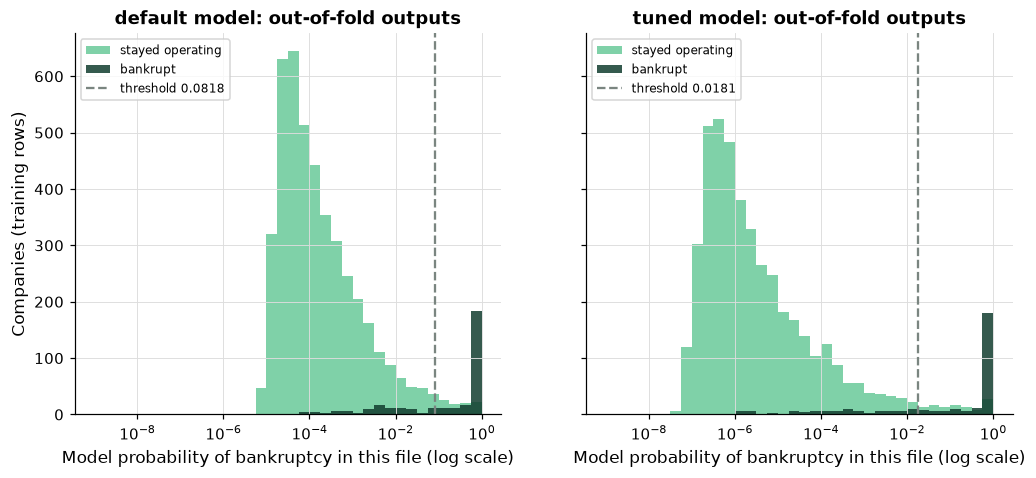

In [45]:
flag_table = pd.DataFrame({
    "threshold": [chosen[n]["threshold"] for n in chosen],
    "flagged": [int(chosen[n]["flags"].sum()) for n in chosen],
    "recall": [chosen[n]["metrics"]["recall"] for n in chosen],
    "precision": [chosen[n]["metrics"]["precision"] for n in chosen],
}, index=pd.Index(list(chosen), name="model"))
display(plotkit.styled(flag_table, ["recall", "precision"],
                       "Threshold for recall of at least 0.70, chosen on out-of-fold outputs of the training rows",
                       fmt="{:.4f}"))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
# outputs run from near 0 to near 1, so the bins are even on a log scale
bins = np.logspace(-9, 0, 37)
for ax, name in zip(axes, chosen):
    proba = chosen[name]["proba"]
    ax.hist(proba[y_train.to_numpy() == 0], bins=bins, color=plotkit.GREEN_LIGHT, label="stayed operating")
    ax.hist(proba[y_train.to_numpy() == 1], bins=bins, color=plotkit.GREEN_DARK, alpha=0.85, label="bankrupt")
    ax.axvline(chosen[name]["threshold"], color=plotkit.GREY, linestyle="--",
               label=f"threshold {chosen[name]['threshold']:.4f}")
    ax.set_xscale("log")
    ax.set_title(f"{name} model: out-of-fold outputs")
    ax.set_xlabel("Model probability of bankruptcy in this file (log scale)")
    ax.legend(loc="upper left", fontsize=8)
axes[0].set_ylabel("Companies (training rows)")
plt.show()

* The tuned model's outputs sit further left: the median output of the companies that stayed operating is 1.03e-04 for the default model and 1.39e-06 for the tuned one. The same recall needs a lower threshold, which is why each model gets its own.

Q. Draw the flags at each model's own threshold as confusion heatmaps.

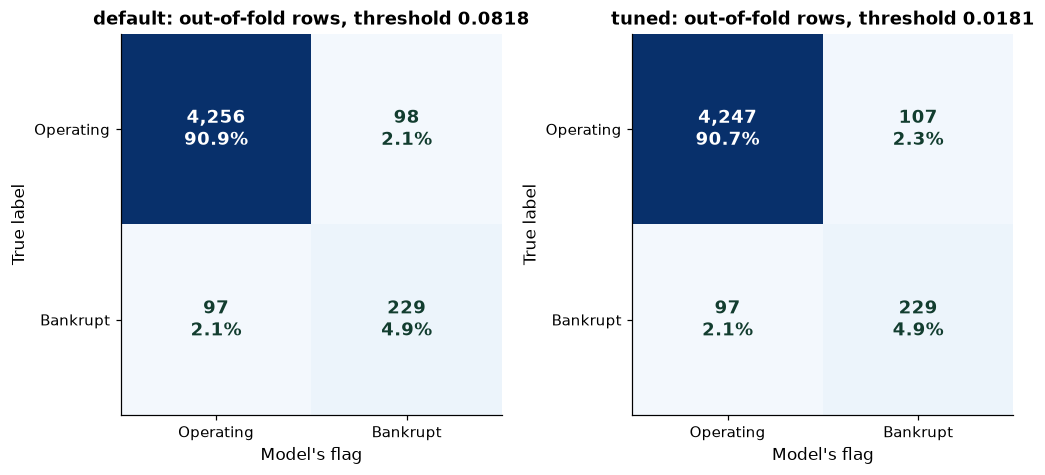

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, name in zip(axes, chosen):
    plotkit.confusion_heatmap(y_train, chosen[name]["flags"],
                              f"{name}: out-of-fold rows, threshold {chosen[name]['threshold']:.4f}",
                              labels=("Operating", "Bankrupt"), ax=ax)
plt.show()

* Both catch 229 of the 326 bankrupt companies; the default flags 98 operating companies with them and the tuned model 107. The cells are near twins once each model has its own threshold.

## Excel Side by Side

Excel has no randomized search and no cross-validation: there is no worksheet function that fits a model on four folds and scores the fifth. What Excel can do is read a search's results once they are pasted onto a sheet, and the formulas below were typed into Excel by script on this notebook's own numbers (Excel 16.0 build 20430, 2026-10-24).

| Job | Python | Excel | Excel returned |
| --- | --- | --- | --- |
| A candidate's mean fold score | `mean_test_score` | `=AVERAGE(B2:F2)`, filled down | equal to Python |
| Its fold standard deviation | `std_test_score` (`ddof=0`) | `=STDEV.P(B2:F2)`, filled down | 0.0445 for the best candidate |
| Not the same standard deviation | `np.std(..., ddof=1)` | `=STDEV.S(B2:F2)` | 0.0497, larger on every candidate |
| The search's best score | `search.best_score_` | `=MAX(G2:G7)` | 0.7760 |
| Which candidate it was | `search.best_index_ + 1` | `=INDEX(A2:A7,MATCH(MAX(G2:G7),G2:G7,0))` | candidate 2 |
| The nested mean and its spread | `nested.mean()`, `nested.std()` | `=AVERAGE(A20:E20)`, `=STDEV.P(A20:E20)` | 0.7697, 0.0539 |
| The nested folds' lowest and highest | `nested.min()`, `nested.max()` | `=MIN(A20:E20)`, `=MAX(A20:E20)` | 0.6792, 0.8153 |
| The range across fold seeds | `max - min` | `=MAX(A24:A27)-MIN(A24:A27)` | 0.0075 |
| The gain from tuning | `best_score_ - default mean` | `=K1-A24` | -0.0024 |

**The candidates' sheet.** Paste each candidate's five fold scores (`split0_test_score` to `split4_test_score` of `cv_results_`) into columns B to F, one row per candidate, with the candidate's number in column A. `AVERAGE` across a row is the candidate's mean, and `STDEV.P` across it is `cv_results_`' standard deviation, because both divide by the number of folds. `STDEV.S` divides by one less (four here) and gives a larger number on every row, so it is not the number `cv_results_` reports. `MAX` down the column of means is `best_score_`, and `INDEX` with `MATCH` returns the row it came from.

**The nested scores and the fold seeds.** The five nested scores pasted in a row give the honest mean with `AVERAGE`, and the four fold seeds' means pasted in a column give the range with `MAX` minus `MIN`. The tuning gain is one subtraction: the best score less the default model's mean.

The bar charts with error bars in sections 11.8 and 11.11 are Excel's clustered column chart, with custom error bars taken from the sd column.

Q. Do Excel's numbers equal Python's?

In [47]:
# Excel's numbers, from the course's Excel check, beside Python's
excel = {"best_score_ (MAX of the means)": 0.7759550824108887,
         "best candidate's sd (STDEV.P)": 0.04449150329314102,
         "nested mean (AVERAGE)": 0.7696937026956959,
         "range across fold seeds (MAX - MIN)": 0.007495969848864248}
python = {"best_score_ (MAX of the means)": search.best_score_,
          "best candidate's sd (STDEV.P)": search.cv_results_["std_test_score"][search.best_index_],
          "nested mean (AVERAGE)": nested.mean(),
          "range across fold seeds (MAX - MIN)": spread}

side_by_side = pd.DataFrame({"Excel": excel, "Python": python})
side_by_side["within 1e-12"] = (side_by_side["Excel"] - side_by_side["Python"]).abs() < 1e-12
print(side_by_side.to_string())

                                        Excel    Python  within 1e-12
best_score_ (MAX of the means)       0.775955  0.775955          True
best candidate's sd (STDEV.P)        0.044492  0.044492          True
nested mean (AVERAGE)                0.769694  0.769694          True
range across fold seeds (MAX - MIN)  0.007496  0.007496          True


* Every number matches within 1e-12. Excel reads the search; Python ran it.

## Save the Day with Git

Today's Git step reads a commit: `git show --stat HEAD` prints the last commit's message and, for each file it changed, how many lines it added and removed. It is the quickest answer to "what did that commit touch?"

Q. Make the work folder a repository.

In [48]:
# stop here, with the steps to install it, if Git is not on this machine
if shutil.which("git") is None:
    raise RuntimeError("Git is not installed. Install Git for Windows from https://git-scm.com/downloads "
                       "(or run  winget install --id Git.Git  where your firm allows it), restart VS Code, "
                       "and run this cell again. Colab has Git already.")

# -C "{work}" points every Git command at the work folder, whatever folder the notebook is in
!git -C "{work}" --version
# make the work folder a repository
!git -C "{work}" init -q -b main
# settings for this repository only: a course name, a reserved example email, line endings left as they are,
# and no commit signing, so a signing setup on your machine does not ask for a key here
!git -C "{work}" config user.name "Course Student"
!git -C "{work}" config user.email "student@example.com"
!git -C "{work}" config core.autocrlf false
!git -C "{work}" config commit.gpgsign false

git version 2.50.1.windows.1


Q. Is Git working in the work folder, and only there?

In [49]:
# the guard: Git must report the work folder as the top of this repository, or the notebook stops
top = subprocess.run(["git", "-C", str(work), "rev-parse", "--show-toplevel"],
                     capture_output=True, text=True, check=True).stdout.strip()
assert os.path.samefile(top, work), "Git is not working in the work folder. Stop, and run the setup cell again."
print(f"Git is working in {work.name} and nowhere else")

Git is working in pfi_course5_11_nwn4hy6s and nowhere else


Q. Tell Git which files never to track, then commit the day's code: Course 4's module, unchanged, and today's two files.

In [50]:
%%writefile .gitignore
__pycache__/
.pytest_cache/
*.xlsx

Writing .gitignore


In [51]:
# the four data files are copies of the course's data and stay untracked
!git -C "{work}" add .gitignore mlkit.py ensemblekit.py test_ensemblekit.py
!git -C "{work}" commit -q -m "Polish rows, nested_score, search_table: 42 tests"
!git -C "{work}" show --stat HEAD

commit 9a235e4de404f12d10ccc53ded498f64c331c003
Author: Course Student <student@example.com>
Date:   Sat Oct 24 22:59:59 2026 -0400

    Polish rows, nested_score, search_table: 42 tests

 .gitignore          |   3 +
 ensemblekit.py      | 458 ++++++++++++++++++++++++++++++++++++++++++
 mlkit.py            | 568 ++++++++++++++++++++++++++++++++++++++++++++++++++++
 test_ensemblekit.py | 522 +++++++++++++++++++++++++++++++++++++++++++++++
 4 files changed, 1551 insertions(+)


* The first lines name the commit, its author, date, and message. Below them, one line per file: the file's name, how many lines changed, and a bar of `+` signs for added lines. All four files are new in this work folder, so every line counts as added; in your own `my_bondmath` folder, the same command after today's commit shows only today's lines in `ensemblekit.py` and `test_ensemblekit.py`.

Q. Write the experiment log for a tuning day: each model's cross-validated mean, its fold standard deviation, and its nested mean.

In [52]:
log = pd.DataFrame([
    # nothing was tuned for the default model, so its cross-validated mean is already honest: the nested column repeats it
    {"model": "lightgbm_default", "cv_mean": default_scores.mean(), "cv_sd": default_scores.std(),
     "nested_mean": default_scores.mean()},
    {"model": "lightgbm_random_search", "cv_mean": search.best_score_,
     "cv_sd": search.cv_results_["std_test_score"][search.best_index_], "nested_mean": nested.mean()},
])
log.to_csv("results.csv", index=False, float_format="%.4f", lineterminator="\n")
print((work / "results.csv").read_text(encoding="utf-8"))

model,cv_mean,cv_sd,nested_mean
lightgbm_default,0.7783,0.0469,0.7783
lightgbm_random_search,0.7760,0.0445,0.7697



* A tuning day's log has four columns: `model, cv_mean, cv_sd, nested_mean`. For the search, `cv_mean` is `best_score_` (0.7760) and `nested_mean` is the honest score (0.7697); a reader of the log sees both, side by side.

In [53]:
!git -C "{work}" add results.csv
!git -C "{work}" commit -q -m "Experiment log: the default LightGBM against the randomized search, with its nested score"
!git -C "{work}" show --stat HEAD

commit 033837b372662944b6ea7c6b251d9126d5ee5140
Author: Course Student <student@example.com>
Date:   Sat Oct 24 22:59:59 2026 -0400

    Experiment log: the default LightGBM against the randomized search, with its nested score

 results.csv | 3 +++
 1 file changed, 3 insertions(+)


* This time `--stat` lists one file, `results.csv`, with its three lines added. Two commits: the code, then its results.

## Bring It Home

Add today's functions to your own `my_bondmath` folder. Open a PowerShell terminal in VS Code.

**Step 1.** Go to your folder and copy in the Polish file, which today's tests read.

```powershell
Set-Location "$HOME\projects\my_bondmath"
Copy-Item "$HOME\projects\python-fixed-income\data\polish_bankruptcy_5year.csv" .
```

**Step 2.** Paste the code of today's two `%%writefile -a ensemblekit.py` cells (sections 11.1 and 11.8), without their first lines, at the end of `ensemblekit.py`; do the same for the two `test_ensemblekit.py` cells. Save both.

**Step 3.** Run the tests.

```powershell
python -m pytest -q test_ensemblekit.py
```

The last line says `42 passed`.

**Step 4.** Commit the code only, and read the commit back. The data files are copies of the course's files, so they are never committed here.

```powershell
git add ensemblekit.py test_ensemblekit.py
git commit -m "Polish rows, nested_score, search_table: 42 tests"
git show --stat HEAD
```

Here `--stat` shows only today's additions to the two files.

**In Colab**, download `ensemblekit.py` and `test_ensemblekit.py` from the work folder under `/tmp` in the file browser.

## You Can Now

* Rebuild Course 4's Polish training rows with `course4_polish_rows`, with its test rows closed.
* Say what a grid search costs, and why a randomized search covers more values for the same cost.
* Write a tuning loop over a list, nested loops over two settings, and read their heatmap.
* Run `GridSearchCV` and check that it reproduces the loops, and read `cv_results_` as a table.
* Write a `RandomizedSearchCV` with `scipy.stats` distributions, `n_iter`, and the course's folds, and draw its coverage against a grid's.
* Write an Optuna objective with `suggest_int` and `suggest_float(..., log=True)`, run a seeded study, and compare its progress with a random search's.
* Read the four rungs by fits used, best five-fold mean, and a check score read once.
* Read a search's results with `search_table`: the mean, the fold standard deviation, and how close the candidates are.
* Measure a tuning gain against the change from reshuffling the folds.
* Score a tuned model honestly with `nested_score`, and log it beside `best_score_`.
* Say that a threshold chosen after the search is one more choice made on the training rows.

Tomorrow, day 12: feature engineering on financial ratios, with every statistic a feature needs learned inside the fold.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

The exercises use Course 4's 4,680 Polish training rows, scored by five folds; the test rows stay closed, and every answer describes this file. Replace each `...` with your own code, then run the check cell.

Q. Run the next cell first. It loads the training rows, rebuilds section 11.7's search space and the default model's fold scores, rebuilds the ladder's tuning rows and folds from section 11.2, and defines `check`, a small function that marks your answers.

In [54]:
from lightgbm import LGBMClassifier
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, cross_val_score

# Course 4's Polish training rows
polish = pd.read_csv("polish_bankruptcy_5year.csv", float_precision="round_trip")
X_train, y_train = ensemblekit.course4_polish_rows(polish)

# section 11.7's search space, and the default model's five fold scores
space = {"num_leaves": randint(8, 64), "learning_rate": loguniform(0.02, 0.3), "min_child_samples": randint(5, 60)}
default_scores = cross_val_score(LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1), X_train, y_train,
                                 cv=mlkit.cv_folds(), scoring="average_precision", n_jobs=1)
print(f"default LightGBM: mean average precision {default_scores.mean():.4f}")

# section 11.2's tuning rows, check rows, and folds, and Optuna (quiet)
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from sklearn.model_selection import train_test_split

# the ladder searches 80 percent of the training rows; the other 20 percent are the check, scored once per rung at the end
X_tune, X_check, y_tune, y_check = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
# the same five stratified folds of the tuning rows for every rung, so the rungs' scores compare
ladder_folds = mlkit.cv_folds()
# every candidate keeps 100 trees, as the default model does; the rungs change the shape of the trees and the step size
LADDER_TREES = 100
print(f"tuning rows: {len(X_tune):,}, of which bankrupt {int(y_tune.sum())}; check rows: {len(X_check):,}, of which bankrupt {int(y_check.sum())}")


def check(label, answer, expected):
    """Compare an exercise answer with the expected value and print the result."""
    if answer is ...:
        print(f"{label}: not attempted yet")
        return
    if isinstance(expected, float):
        # numbers with a decimal point: within a small tolerance
        correct = abs(answer - expected) < 1e-6
    else:
        correct = answer == expected
    if correct:
        print(f"{label}: correct")
    else:
        print(f"{label}: not yet. You have {answer}.")

default LightGBM: mean average precision 0.7783
tuning rows: 3,744, of which bankrupt 261; check rows: 936, of which bankrupt 65


### Exercise 1

Q. Run section 11.7's search with a smaller budget: `n_iter=4` instead of 6, everything else the same (100 trees, `mlkit.cv_folds()`, `random_state=SEED`, `n_jobs=1`). Store it in **search_4** and its `best_score_` in **ex1_best**. How does it compare with section 11.7's 0.7760?

In [55]:
search_4 = ...
ex1_best = ...

In [56]:
check("Exercise 1 the best of four candidates", ex1_best, 0.7759550824108887)

Exercise 1 the best of four candidates: not attempted yet


### Exercise 2

Q. Tune XGBoost instead. Search `XGBClassifier(n_estimators=100, random_state=SEED, n_jobs=1)` with `n_iter=4` over `{"max_depth": randint(2, 7), "learning_rate": loguniform(0.02, 0.3), "min_child_weight": randint(1, 10)}`, with the same folds, scoring, `random_state=SEED`, and `n_jobs=1`. XGBoost takes missing values as they are, as LightGBM does. Store the search's `best_score_` in **ex2_best**.

In [57]:
ex2_best = ...

In [58]:
check("Exercise 2 XGBoost's best of four", ex2_best, 0.7646129845876167)

Exercise 2 XGBoost's best of four: not attempted yet


### Exercise 3

Q. Add a function to your module. `tuning_gain(search, baseline_scores)` returns a fitted search's `best_score_` minus the mean of a baseline model's fold scores. It raises `ValueError` if the search is not fitted (it has no `best_score_`) or the baseline scores are empty. Write the docstring first, and say in it that the gain is optimistic. Then add `test_tuning_gain_hand`, which checks a stand-in object with `best_score_` 0.80 against baseline scores 0.70 and 0.80 (a gain of 0.05) and both errors. Run pytest, reload the module, and store `ensemblekit.tuning_gain(search_4, default_scores)` in **ex3_gain**.

Write the function in the cell that starts with `%%writefile -a ensemblekit.py` and the test in the one that starts with `%%writefile -a test_ensemblekit.py`, and run each of those cells once.

In [59]:
%%writefile -a ensemblekit.py


# Exercise 3: write tuning_gain(search, baseline_scores) below this line

Appending to ensemblekit.py


In [60]:
%%writefile -a test_ensemblekit.py


# Exercise 3: write test_tuning_gain_hand() below this line

Appending to test_ensemblekit.py


In [61]:
# run pytest, reload the module, then call your function
ex3_gain = ...

In [62]:
check("Exercise 3 tuning_gain of the best of four", ex3_gain, -0.00237385286446945)

Exercise 3 tuning_gain of the best of four: not attempted yet


### Exercise 4

Q. Grow section 11.5's study by one setting. Write an objective that also draws `min_child_samples` with `trial.suggest_int("min_child_samples", 5, 60)`, and run 12 trials on the tuning rows and `ladder_folds` with the same sampler, `TPESampler(seed=SEED, n_startup_trials=6)`. Store the study's `best_value` in **ex4_best**. How does it compare with the two-setting study's 0.7785?

In [63]:
ex4_best = ...

In [64]:
check("Exercise 4 the three-setting study best value", ex4_best, 0.7789137252103849)

Exercise 4 the three-setting study best value: not attempted yet


### Exercise 5: AI check

You ask an AI assistant for a function that fits a search and logs the tuned model's honest score, and you give it a docstring as the request. **The docstring is the prompt.** This is what you gave it:

```
Fit the search on the training rows and log the tuned model's honest cross-validated score.

    Appends one row to the experiment log at path: model, and cv_score, the average precision the tuned
    model can be expected to reach on rows that took no part in choosing it. Returns that score.
```

The function below came back. It was written for this course in the style of an AI assistant's answer. It runs without an error, writes a log with one row, returns a number between 0 and 1, and contains one bug.

In [65]:
# written for this course in the style of an AI assistant's answer. It runs, and it contains one bug.
def log_tuned_score(search, X, y, path="results.csv"):
    """Fit the search on the training rows and log the tuned model's honest cross-validated score.

    Appends one row to the experiment log at path: model, and cv_score, the average precision the tuned
    model can be expected to reach on rows that took no part in choosing it. Returns that score.
    """
    search.fit(X, y)
    # the search already cross-validated every candidate, so its best score is the tuned model's score
    score = search.best_score_
    pd.DataFrame([{"model": "tuned_lightgbm", "cv_score": score}]).to_csv(path, index=False, lineterminator="\n")
    return score

Q. Make a small search and run the function on the training rows. Before you run the next cell: is the number it logs a score on rows that took no part in choosing the model?

In [66]:
# a small search, so the check runs in seconds: 3 candidates of a 30-tree LightGBM, 3 inner folds
ai_search = RandomizedSearchCV(LGBMClassifier(n_estimators=30, random_state=SEED, n_jobs=1, verbose=-1), space,
                               n_iter=3, scoring="average_precision",
                               cv=StratifiedKFold(3, shuffle=True, random_state=SEED), random_state=SEED, n_jobs=1)
ai_score = log_tuned_score(ai_search, X_train, y_train, path="ai_log.csv")
print(pd.read_csv("ai_log.csv").to_string(index=False))

         model  cv_score
tuned_lightgbm  0.745141


Q. Test the function against its docstring before you trust it.

In [67]:
# the test, written from the docstring before the code is trusted
logged = pd.read_csv("ai_log.csv")["cv_score"].iloc[0]
honest = ensemblekit.nested_score(ai_search, X_train, y_train).mean()
print(f"logged {logged:.4f}; nested mean {honest:.4f}")
# the logged score must be the honest one: the nested mean of the same search on the same rows
assert abs(logged - honest) < 1e-12, "the logged score is not the nested score of the search"

logged 0.7451; nested mean 0.7655


AssertionError: the logged score is not the nested score of the search

Q. Read the test's message, fix the function in the cell that defines it, and run that cell, the search cell, and the test again until the test passes. Then store the score the fixed function logs, `ai_score`, in **ex5_score**.

In [68]:
# fix the function above, run the cells again, then store the answer
ex5_score = ...

In [69]:
check("Exercise 5 the fixed function's logged score", ex5_score, 0.7654945188595413)

Exercise 5 the fixed function's logged score: not attempted yet


## Tidying Up

The work folder stays where it is, so you can open it: its name was printed by the setup cell, and on Windows it is under `$env:TEMP`. Every run of the setup cell makes a new one. To delete a work folder, run these lines in a cell of the same notebook session. Git marks its own files read-only, and on Windows a plain delete stops at them with a `PermissionError`, so the handler clears that flag and tries again.

```python
import stat

def clear_read_only(function, path, error):
    """Make a read-only file writable, then retry the delete that failed on it."""
    os.chmod(path, stat.S_IWRITE)
    function(path)

os.chdir(notebook_folder)
shutil.rmtree(work, onexc=clear_read_only)
print(f"{work.name} exists: {work.exists()}")
```